# EDA and Data Preprocessing
**AI-Powered Stock Market Prediction**

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_pacf       
from statsmodels.stats.diagnostic import acorr_ljungbox   
pd.set_option("display.max_columns", None)                # show every column instead of "..."
pd.set_option("display.width", 200)
import warnings
warnings.filterwarnings("ignore")  # Ignore warnings for cleaner output

## 2. Load and clean the data

In [2]:
data_path = "dataset"
stock = ["AAPL", "NVDA", "JPM", "BHP", "CBA", "GMG"]

def check_data(data_path, csv_file):

    # Read the csv file into a dataframe
    file_path = f"{data_path}/{csv_file}.csv"
    df = pd.read_csv(file_path)

    # Convert date column to datetime format
    df['Date'] = pd.to_datetime(df['Date'], format= '%d %b %Y')

    # Sort from oldest to newest
    df = df.sort_values('Date').reset_index(drop=True)

    return df

raw_data = {s: check_data(data_path, s) for s in stock}
# Data quality summary for each stock
data_quality = pd.DataFrame([{
    "Stock": s,
    "Market": "US" if s in ['AAPL', 'NVDA', 'JPM'] else "AU",
    "Rows": len(df),
    "Start": df['Date'].min().date(),
    "End": df['Date'].max().date(),
    "Missing values": df.isnull().sum().sum(),
    "Duplicate rows": df.duplicated().sum(),
    "Duplicate dates": df.duplicated(subset=['Date']).sum(),
    "Zero volume days": (df['Volume'] == 0).sum()}
    for s, df in raw_data.items()])

data_quality


,Stock,Market,Rows,Start,End,Missing values,Duplicate rows,Duplicate dates,Zero volume days
0,AAPL,US,2010,2018-01-02,2025-12-30,0,0,0,0
1,NVDA,US,2010,2018-01-02,2025-12-30,0,0,0,0
2,JPM,US,2010,2018-01-02,2025-12-30,0,0,0,0
3,BHP,AU,2024,2018-01-02,2025-12-30,0,0,0,0
4,CBA,AU,2024,2018-01-02,2025-12-30,0,0,0,0
5,GMG,AU,2024,2018-01-02,2025-12-30,0,0,0,1


One non-trading observation was identified for **GMG on 19/2/25** (zero volume, with Open, High, Low, and Close equal to the previous close), consistent with a trading halt. This placeholder row was removed, as it would otherwise introduce an artificial 0% return and extreme values in the volume-change feature. The following day's return is therefore measured against the 18 Feburary close, preserving the true price movement.

In [3]:
# Clean the data
cleaned_data = {}

for s, df in raw_data.items():
    # Remove rows with zero volume
    non_trading = (df['Volume'] == 0) & (df['High'] == df['Low'])
    if non_trading.sum() > 0:
        print(f"{s}: {non_trading.sum()} non-trading day(s) removed")
    df = df[~non_trading]

    # Use date as the index (needed for the walk-forward steps)
    cleaned_data[s] = df.set_index('Date')
print(cleaned_data)
# Check again after cleaning
clean_data = pd.DataFrame([{
    "Stock": s,
    "Rows": len(df),
    "Missing values": df.isnull().sum().sum(),
    "Duplicate rows": df.reset_index().duplicated().sum(),
    "Duplicate dates": df.index.duplicated().sum(),
    "Zero volume days": (df['Volume'] == 0).sum()}
    for s, df in cleaned_data.items()
])

clean_data

GMG: 1 non-trading day(s) removed
{'AAPL':               Open    High     Low   Close  Adj Close     Volume
Date                                                            
2018-01-02   42.54   43.08   42.31   43.06      40.23  102223600
2018-01-03   43.13   43.64   42.99   43.06      40.23  118071600
2018-01-04   43.13   43.37   43.02   43.26      40.41   89738400
2018-01-05   43.36   43.84   43.26   43.75      40.87   94640000
2018-01-08   43.59   43.90   43.48   43.59      40.72   82271200
...            ...     ...     ...     ...        ...        ...
2025-12-23  270.84  272.50  269.56  272.36     271.62   29642000
2025-12-24  272.34  275.43  272.20  273.81     273.07   17910600
2025-12-26  274.16  275.37  272.86  273.40     272.66   21521800
2025-12-29  272.69  274.36  272.35  273.76     273.02   23715200
2025-12-30  272.81  274.08  272.28  273.08     272.34   22139600

[2010 rows x 6 columns], 'NVDA':               Open    High     Low   Close  Adj Close     Volume
Date         

,Stock,Rows,Missing values,Duplicate rows,Duplicate dates,Zero volume days
0,AAPL,2010,0,0,0,0
1,NVDA,2010,0,0,0,0
2,JPM,2010,0,0,0,0
3,BHP,2024,0,0,0,0
4,CBA,2024,0,0,0,0
5,GMG,2023,0,0,0,0


## 3. Walk-forward folds

**Walk-forward Validation** is a method for evaluating a model by simulating real-world forecasting. The model is trained using only data available prior to the forecast point, then advances incrementally over time. 
In this project, the team uses a 12-fold cross-validation approach using an expanding window. The first fold trains on data from January 2018 through December 2022 and testing on the first quarter of 2023. After each fold, the tested quarter is added to the training set for the subsequent fold, continuing until the 12th fold, which tests the fourth quarter of 2025.

**Why walk-forward validation with expanding window?**

+ A static split relies on a single testing period, making results highly dependent on whether the market is stable or volatile during that time. Financial data constantly changes, therefore, the walk-forward method addresses this by evaluating the model across diverse market phases. Furthermore, by utilizing only historical information within each fold, the method prevents future data leakage, ensuring the results accurately reflect the model's predictive capability.
+ The team chooses the expanding window approach because:
    The rolling window approach maintains a fixed training duration, while LSTM and CNN-LSTM models require substantial data, and discarding older data would reduce the number of training samples

In [4]:
# Build the list of 12 test quarters
test_quarters = pd.period_range(start='2023Q1', end='2025Q4', freq='Q')
folds = [(k+1, q.start_time, q.end_time) for k, q in enumerate(test_quarters)]

# Display the folds, using AAPL as an example
df = cleaned_data['AAPL']
fold_table = pd.DataFrame([{
    "Fold": k,
    "Training period": f"Jan 2018 - {(start - pd.Timedelta(days=1)):%b %Y}",
    "Test period": f"{start:%b %Y} - {end:%b %Y}",
    "Training days": (df.index < start).sum(),
    "Test days": ((df.index >= start) & (df.index <= end)).sum()
} for k, start, end in folds])

fold_table

,Fold,Training period,Test period,Training days,Test days
0,1,Jan 2018 - Dec 2022,Jan 2023 - Mar 2023,1259,62
1,2,Jan 2018 - Mar 2023,Apr 2023 - Jun 2023,1321,62
2,3,Jan 2018 - Jun 2023,Jul 2023 - Sep 2023,1383,63
3,4,Jan 2018 - Sep 2023,Oct 2023 - Dec 2023,1446,63
4,5,Jan 2018 - Dec 2023,Jan 2024 - Mar 2024,1509,61
5,6,Jan 2018 - Mar 2024,Apr 2024 - Jun 2024,1570,63
6,7,Jan 2018 - Jun 2024,Jul 2024 - Sep 2024,1633,64
7,8,Jan 2018 - Sep 2024,Oct 2024 - Dec 2024,1697,64
8,9,Jan 2018 - Dec 2024,Jan 2025 - Mar 2025,1761,60
9,10,Jan 2018 - Mar 2025,Apr 2025 - Jun 2025,1821,62


## 4. EDA

### 4.1 Closing prices

The shaded area is the walk-forward test period (2023-2025). Everything before it is the initial training data.

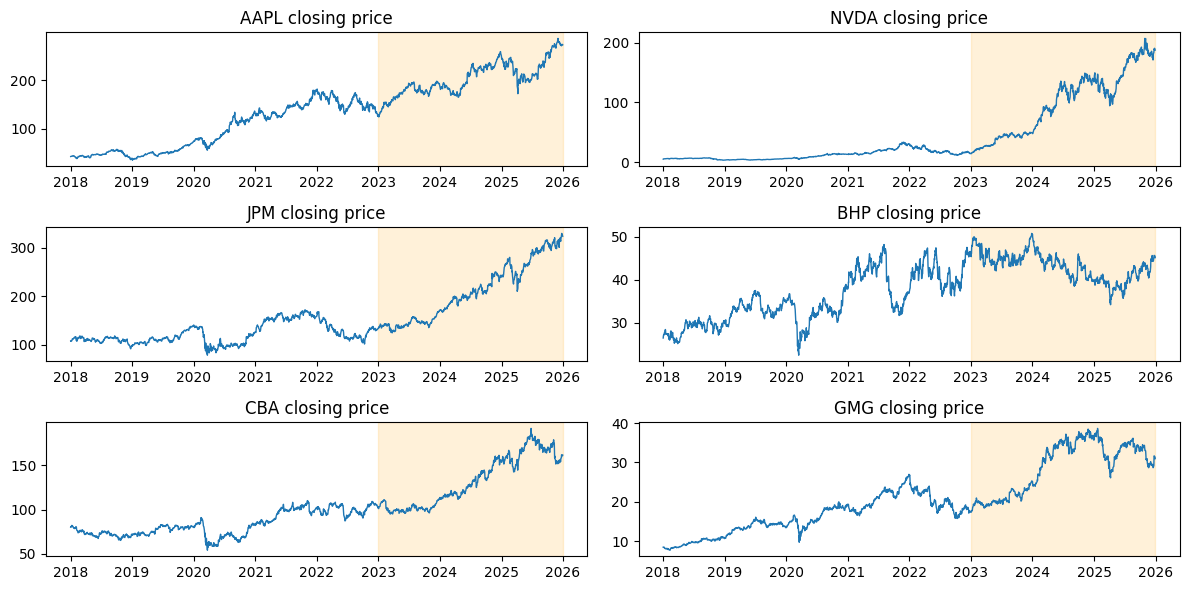

In [5]:
fig, axes = plt.subplots(3, 2,figsize=(12,6))
for ax, (name, df) in zip(axes.flatten(), cleaned_data.items()):
    ax.plot(df.index, df['Close'], linewidth=1)
    ax.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2025-12-31'), color='orange', alpha=0.15)
    ax.set_title(f"{name} closing price")
plt.tight_layout()
plt.show()

The figure above shows the daily closing prices of the six stocks from 2018 to 2025, with the walk-forward test period (2023-2025) shaded. All six series display clear trends rather than a stable mean, and common market shocks are visible across both markets, notably the COVID-19 crash in March 2020 and the sell-off in April 2025. Importantly, the test period differs markedly from the training period for several stocks: NVDA, JPM, CBA and AAPL reach price levels well above their 2018-2022 range, with NVDA rising roughly tenfold, whereas BHP remains within its historical range. This non-stationary means that models trained on raw price levels must extrapolate beyond the range obsered in training, which motivates modelling log returns rather than prices, and supports the use of walk-forwawrd validation to evaluate performance across changing market conditions.

### 4.2 Target Variable Analysis: Price Range and Log Returns

**Why we do not model raw prices?**

**"Close"** is the target variable. In the previous trial, LSTM and CNN-LSTM models were trained directly on price data, which was normalized to the [0,1] range using a Min-Max scaler fitted to the training set. This approach has a fundamental limitation: the scaler only learns the minimum and maximum values from the training period; consequently, if prices during the test period exceed the historical peak, the normalized values exceed 1. Since the models were never trained on this range, they were forced to extrapolate, often resulting in systematic prediction errors. This explains why the NVDA forecast curve flattened and JPM was consitenly under-predicted for the first model application, whereas BHP, whose test prices remained within the obsered range, yielded the best predictions. To verify this issue within the walk-forward framework, the team checks what share of the test quarter's prices is **higher than the highest price in that fold's training data**.

In [6]:
rows = []
for name, df in cleaned_data.items():
    for k, start, end in folds:
        train_max = df.loc[df.index < start, 'Close'].max()
        test_prices = df.loc[(df.index >= start) & (df.index <= end), 'Close']
        rows.append({
            "Stock": name,
            "Fold": k,
            "% test days above train max": 100 *(test_prices > train_max).mean()
        })
above_train_max = pd.DataFrame(rows).pivot(index = 'Stock', columns = 'Fold', values = '% test days above train max')
above_train_max.round(0)

Fold,1,2,3,4,5,6,7,8,9,10,11,12
Stock,,,,,,,,,,,,
AAPL,0.0,23.0,10.0,6.0,0.0,21.0,91.0,42.0,0.0,0.0,0.0,78.0
BHP,35.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CBA,10.0,0.0,0.0,5.0,94.0,35.0,85.0,59.0,15.0,66.0,0.0,0.0
GMG,0.0,0.0,0.0,0.0,53.0,50.0,24.0,27.0,2.0,0.0,0.0,0.0
JPM,0.0,0.0,0.0,0.0,79.0,13.0,89.0,64.0,58.0,8.0,81.0,21.0
NVDA,0.0,40.0,65.0,14.0,93.0,41.0,0.0,67.0,2.0,6.0,97.0,43.0


The table above shows that this rate reached 97% for NVDA (Fold 11), 94% for CBA (Fold 5), 91% for AAPL (Fold 7), and 89% for JPM (Fold 7), whereas it was near zero for BHP. Therefore rather than forecasting prices, the models will be trained to predict next-day log returns. The predicted returns were then converted back to closing prices for evaluation, ensuring that the RMSE, MAE, and MAPE metrics will be calculated based on the original price scale. 

**Daily log returns and descriptive statistics**

**Log return** measures the change in a stock's closing price from the previous day to the current day, using the formula:

$$
r_t = \ln\left(\frac{\text{Close}_t}{\text{Close}_{t-1}}\right)
$$

where $\text{Close}_t$ is today's closing price, $\text{Close}_{t-1}$ is yesterday's closing price

With small changes, the log return is almost the same percentage of the typical change. For example, the price increases from 100USD to 102USD, $r_t = \ln(102/100) \approx 0,0198$, which is about +2%. Unlike the price, which gradually increases over time, the yield always fluctuates around 0 and is in a relatively stable range, regardless of what price the stock is at. We use logarithms instead of regular percentages for two reasons: log returns can compound over time (a 1% increase and then a 2% increase equals a total return of 3%), and it is symmetrical between price increases and decreases, making statistical calculations and modeling more accurate.

In [7]:
log_returns = {}

# Daily log returns for each stock: r_t = ln(Close_t / Close_{t-1})
for s, df in cleaned_data.items():
    #shift(1) = yesterday's closing price, dropna() removes the first row which is NaN
    log_returns[s] = np.log(df['Close'] / df['Close'].shift(1)).dropna() 

return_stats = pd.DataFrame([{
    "Stock": s,
    "Mean (%)": 100 * r.mean(),    # average daily return
    "Std (%)": 100 * r.std(),      # std of daily return
    "Annual volatility (%)": 100 * r.std() * np.sqrt(252), # 252 trading days in a year
    "Min (%)": 100 * r.min(),        # worst daily return   
    "Worst date": r.idxmin().date(), # date of worst daily return
    "Max (%)": 100 * r.max(),        # best daily return
    "Best date": r.idxmax().date(),  # date of best daily return
    "Skewness": r.skew(),             # skewness of daily returns 
    "Excess Kurtosis": r.kurtosis(),          # kurtosis of daily returns
    "Jarque-Bera p-value": stats.jarque_bera(r).pvalue
} for s, r in log_returns.items()])     
return_stats.round(3)

,Stock,Mean (%),Std (%),Annual volatility (%),Min (%),Worst date,Max (%),Best date,Skewness,Excess Kurtosis,Jarque-Bera p-value
0,AAPL,0.092,1.938,30.768,-13.771,2020-03-16,14.262,2025-04-09,-0.083,6.208,0.0
1,NVDA,0.181,3.229,51.254,-20.794,2018-11-16,21.802,2023-05-25,-0.189,4.708,0.0
2,JPM,0.055,1.831,29.065,-16.211,2020-03-16,16.562,2020-03-13,-0.089,13.056,0.0
3,BHP,0.026,1.713,27.198,-15.561,2020-03-09,11.282,2020-03-17,-0.461,6.040,0.0
4,CBA,0.035,1.435,22.785,-10.543,2020-03-16,12.453,2020-03-17,-0.310,10.293,0.0
5,GMG,0.064,1.772,28.127,-15.797,2020-03-19,16.499,2020-03-20,-0.407,12.303,0.0


The table above summurizes the characteristics of daily log returns for six stocks during the 2018-2025 period:
+ **Mean**: the average daily price change
+ **Standard deviation**: the typical percentage fluctuation of the price on an average day
+ **Annual volatility**: converts std to an annual figure (by multiplying by sqrt(252), as there are approxiamtely 252 trading days). This is the most common measure of risk in finance: the higher the figure, the more volatile the price movements and the harder they are to predict.
+ **Min and Max**: represent the days with the sharpest declines and increases, respectively. They help identify unusual market events and allow for data error checks.
+ **Skewness**: indicates whether the distribution is symmetrical. A negative value implies that sharp declines occur more frequently or are more severe than sharp gains
+ **Kurtosis** or excess kurtosis: it is zeo for a normal (bell-shaped) distribution. The higher the value above zero, the more the data exhibits days of extreme volatility-a phenomenon known as fat tails.
+ **Jarque-Bera p-value**: is the result of a test determining whether the data follows a normal distribution. If the p-value is less than 0.05, we conclude that the data is not normally distributed.


Based on the table:
+ The average returns for all six stocks are very close to zero (from 0.03% to 0.18% daily), indicating that returns do not exhibit te upward or downward trends seen in stocks prices.
+ NVDA is the riskies, with an annualized volatility of 51.3%, nearly double that of the other stocks, reflecting the characteristics of a high-growth technology stock. Coversely, CBA is the most stable (22.8%), consistent with its status as a major Australian Bank. AAPL, JPM, GMG, and BHP fall within the moderate range (27-31%). This implies that the model's forecast error for NVDA is likely to be higher than for the other stocs; this not due to model inadequacy but rather the inherently less predictable nature of the stock itself.
+ Minimum and maximum values reveal days of extreme volatility, such as NVDA dropping 20.8% and rising 21.8% in a single day. Most of the sharpest declines occurred in March 2020 during the outbreak of COVID-19 pandemic. These represents actual market events rather than data errors.
+ Negative skewness is observed across all six stocks indicating a market tendency to rise gradually but fall abruptly.
+ Excess kurtosis values for all stocks are significantly above zero (fat tails).
+ Normality test: The Jarque-Bera p-value is 0 for all six tickers, statistically confirming that the returns do not follow a normal distribution

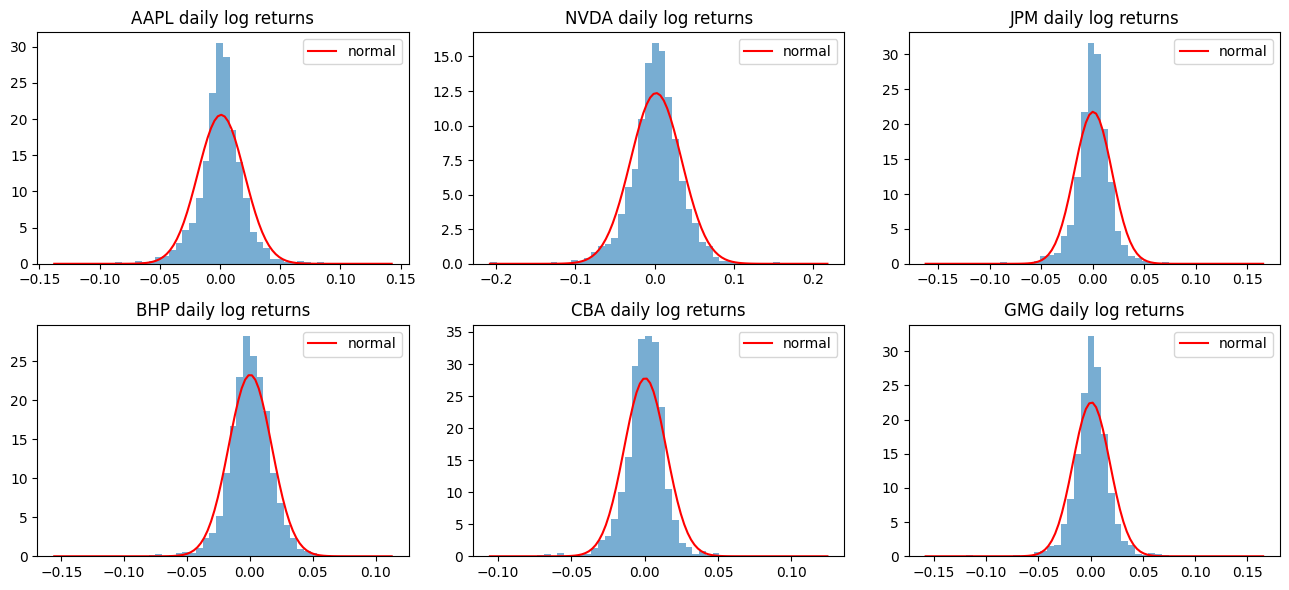

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13,6))
for ax, (name, r) in zip(axes.flatten(), log_returns.items()):
    ax.hist(r, bins=50, density=True, alpha=0.6)
    x = np.linspace(r.min(), r.max(), 100)
    ax.plot(x, stats.norm.pdf(x, loc=r.mean(), scale=r.std()), color='red', label='normal')
    ax.set_title(f"{name} daily log returns")
    ax.legend()
plt.tight_layout()
plt.show()

The firgure above again confirms that the distribution of all six stocks do not follow normal distribution. It could mean that markets are calm on most days but occasionally experience extreme shocks. Because such extreme observations can dominate a squared-error loss, winsorsation is considered during preprocessing, and the Diebold-Mariano test, which does not assume normality, is also used for model comparison.

### 4.3 Stationarity (ADF test)

**A stationary series** do not change over time, it consistently fluctuates around a fixed mean with relatively stable volatility. **Augmented Dickey-Fuller** (ADF) test is a statistical test that answers the question whether this data series is stationary.
**Why ADF  test is used?**
+ All forecasting models rely on the assumption that patterns learned from the past remain valid in the future. This assumption holds true only when the data is stationary.
+ ARIMA models function correctly only with stationary data. If the data is non-stationary, differencing must be applied to transform it into a stationary series. The number of differencing operations performed corresponds to the parameter d in ARIMA(p,d,q). The ADF test assists in determining d.
+ The ADF test provides formal statistical evidence to support th decision to forecast returns rather than raw prices.


Our null hypothesis:
+ $H_0$: The series is non-stationary
+ $H_1$: The series is stationary

In [9]:
adf_results = pd.DataFrame([{
    "Stock": s,
    "ADF p-value log price": adfuller(np.log(df['Close']))[1], #[1] = p-value
    "ADF p-value log returns": adfuller(log_returns[s])[1]
} for s, df in cleaned_data.items()])

adf_results["Price stationary?"] = adf_results["ADF p-value log price"] < 0.05
adf_results["Returns stationary?"] = adf_results["ADF p-value log returns"] < 0.05
adf_results.round(2)

,Stock,ADF p-value log price,ADF p-value log returns,Price stationary?,Returns stationary?
0,AAPL,0.75,0.0,False,True
1,NVDA,0.98,0.0,False,True
2,JPM,0.96,0.0,False,True
3,BHP,0.09,0.0,False,True
4,CBA,0.88,0.0,False,True
5,GMG,0.38,0.0,False,True


**ADF results.** For all six stocks the p-value for the log price is above 0.05 (0.09 to 0.98), so H0 cannot be rejected: log prices are non-stationary. BHP is the closest to the threshold (p = 0.09), consistent with its price staying within its historical range rather than trending strongly upward (Section 4.1), but it still fails the test at the 5% level. For log returns the p-value is 0.00 (rounded) for every stock, so returns are stationary. This is the formal evidence behind two decisions: the deep-learning models predict returns rather than prices, and ARIMA uses d = 1 (confirmed fold by fold in Section 5.4).

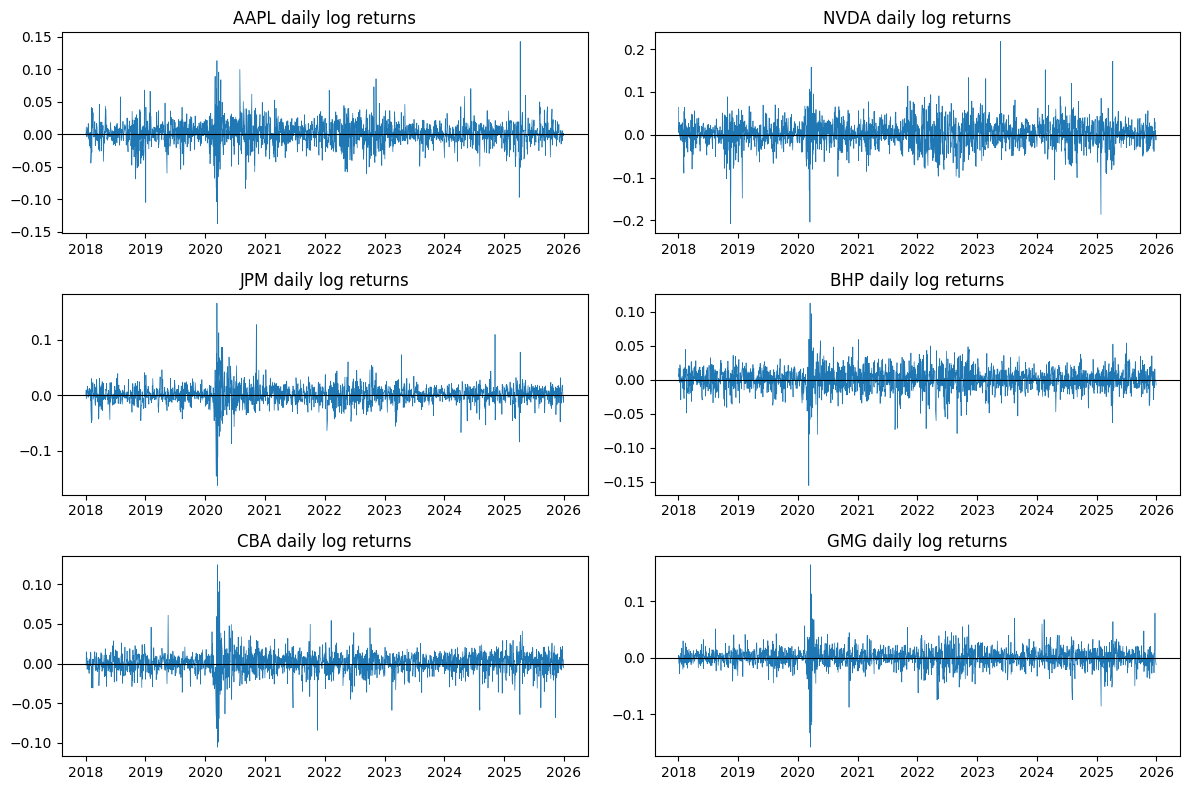

In [10]:
# Plot the returns over time (compare with the price chart: no trend, moves around 0)
fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for ax, (s, r) in zip(axes.flatten(), log_returns.items()):
    ax.plot(r.index, r, linewidth=0.5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f"{s} daily log returns")
plt.tight_layout()
plt.show()

### 4.4 Autocorrelation

**Autocorrelation** measures the extent to which today's value resembles (or is related to) its own past values. It answers the question: "If we know what happened yesterday, can we predict what will happen today?". The autocorrelation coefficient ranges from -1 to +1:
+ +1: if yesterday saw an increase, today likely sees an increase too.
+ 0: yesterday offers no predictive power for today.
+ -1: if yesterday saw an increase, today likely sees a decrease.


**Why autocorrelation is used?"**
+ Understanding the difficulty of the problem and the need for a naive baseline.
+ Selecting parameters for ARIMA. ARIMA(p,d,q) involves two parameters selected based on specific plots: p based on the PACF plot; q based on the ACF plot
+ Justification for using LSTM: Given than simple (linear) autocorrelation is weak, the question arises as to whether there are complex (non-linear) patterns that the ACF fails to detect. LSTM and CNN-LSTM models are desinged to identify such patterns within 60-day sequence. This can answer the quesion: can neural networks uncover information that ARIMA misses?

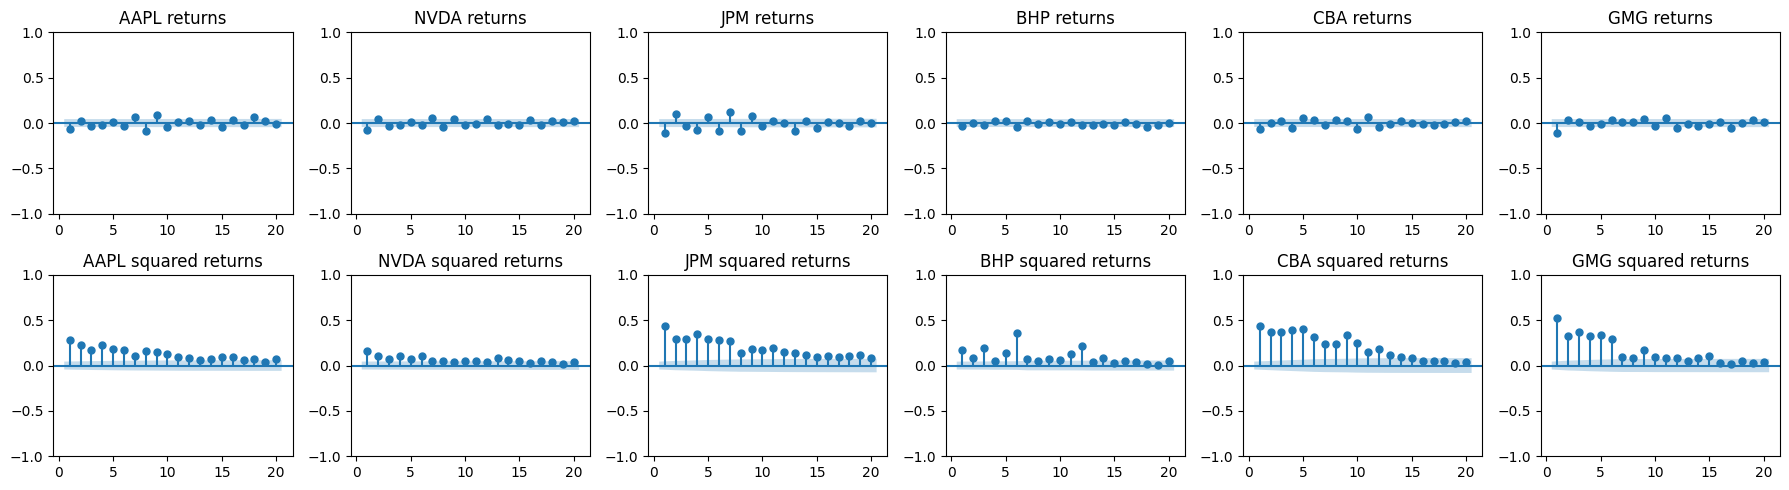

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(18, 5))
for i, (s, r) in enumerate(log_returns.items()):
    plot_acf(r, lags=20, zero = False, ax=axes[0, i], title=f"{s} returns")
    plot_acf(r**2, lags=20, zero = False, ax=axes[1,i], title=f"{s} squared returns")
plt.tight_layout()
plt.show()

The ACF plots reveal very weak autocorrelation in daily log returns across all six stocks: most coefficients are close to zero, with only JPM and GMG exhibiting a small negative coefficient. This indicates that the direction of price movements is virually unpredictable based on past returns, making the naive forecase a difficult benchmark to beat. In constrast, the autocorrelation of squared returns is clearly positive and decays with the lag, particularly for CBA, JPM, GMG, and AAPL, reflecting the phenomenon of volatility clusterng, where periods of high volatility tend to persist. Consequently, the difficulty of forecasting varies over time, reinforcing the need to evaluate models using a multi-fold walk-forward approach rather than a single test period.

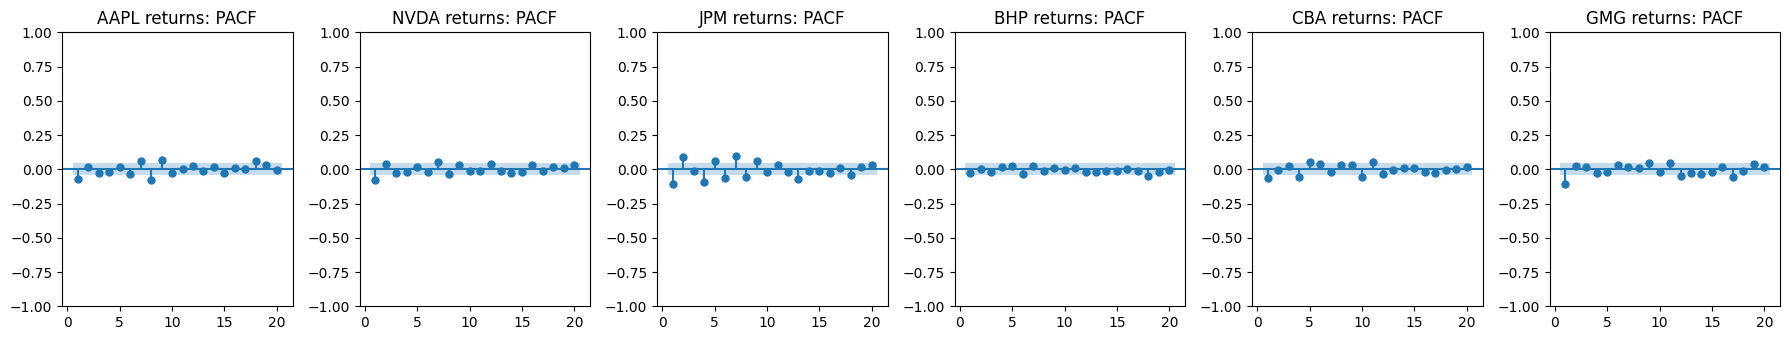

In [12]:
# The PACF shows the direct link between today and lag k after removing the shorter lags.
# It is used to choose the AR order p of ARIMA (the ACF above is used for the MA order q).
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, (s, r) in zip(axes, log_returns.items()):
    plot_pacf(r, lags=20, zero=False, method="ywm", ax=ax, title=f"{s} returns: PACF")
plt.tight_layout()
plt.show()

In [13]:
# H0: no autocorrelation up to lag 10. p < 0.05 means autocorrelation is present.
# Turns the visual reading of the ACF plots into a formal test.
# The test is repeated without 2020 to see how much of the result comes from the COVID period.
lb_rows = []
for s, r in log_returns.items():
    r_no_2020 = r[r.index.year != 2020]
    lb_rows.append({
        "Stock": s,
        "LB p-value: returns (lag 10)": acorr_ljungbox(r, lags=[10])["lb_pvalue"].iloc[0],
        "LB p-value: returns, excluding 2020": acorr_ljungbox(r_no_2020, lags=[10])["lb_pvalue"].iloc[0],
        "LB p-value: squared returns (lag 10)": acorr_ljungbox(r ** 2, lags=[10])["lb_pvalue"].iloc[0]})
ljung_box = pd.DataFrame(lb_rows)
ljung_box.round(4)

,Stock,LB p-value: returns (lag 10),"LB p-value: returns, excluding 2020",LB p-value: squared returns (lag 10)
0,AAPL,0.0000,0.5678,0.0
1,NVDA,0.0000,0.5724,0.0
2,JPM,0.0000,0.2311,0.0
3,BHP,0.5149,0.4447,0.0
4,CBA,0.0000,0.6798,0.0
5,GMG,0.0001,0.0209,0.0


**PACF.** Most partial autocorrelations lie inside the 95% band. The only consistent pattern is a small negative coefficient at lag 1 for five of the six stocks (between −0.06 and −0.11; BHP has none): on average, a rise today is followed by a very slight fall tomorrow. The PACF therefore points to a small AR order (p = 0 or 1) for ARIMA. As planned, the final p and q will be chosen by AIC within each fold.

**Ljung-Box test.** Over the full 2018–2025 sample, the test rejects "no autocorrelation" in returns for every stock except BHP (p = 0.51). This looks stronger than the ACF plots suggest, because the test adds up ten small coefficients over about 2,000 days, and much of the effect comes from the COVID period: with 2020 excluded, only GMG remains significant (p = 0.02). The autocorrelation in returns is therefore weak and not stable over time, which is why the naive forecast is a hard benchmark to beat. For squared returns, p = 0.00 for all six stocks, formally confirming the volatility clustering seen in the plots above.

### 4.5 Volatility over time

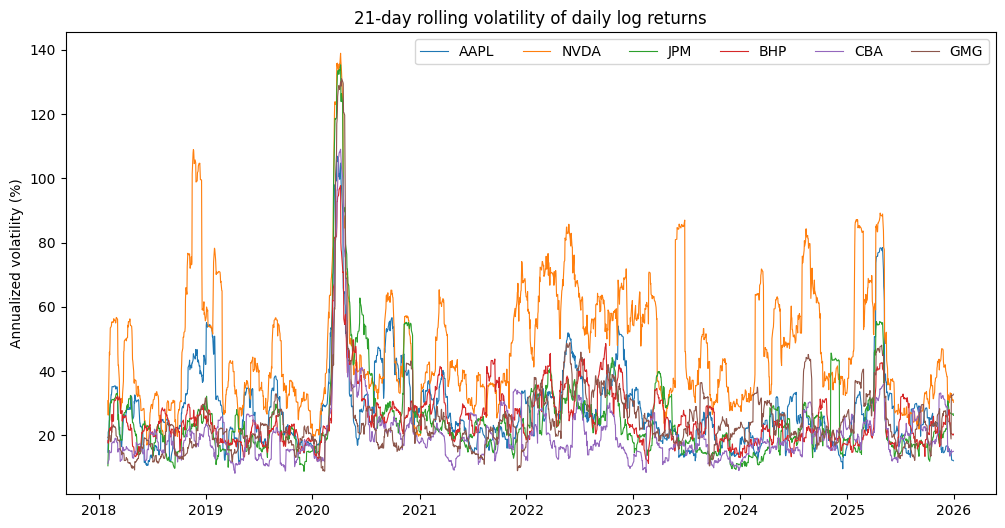

In [14]:
plt.figure(figsize=(12, 6))
for name, r in log_returns.items():
    rolling_vol = r.rolling(window=21).std() * np.sqrt(252) * 100 # 21 trading days ~ 1 month, annualized volatility in %
    plt.plot(rolling_vol, linewidth=0.8, label=name)
plt.ylabel("Annualized volatility (%)")
plt.title("21-day rolling volatility of daily log returns")
plt.legend(ncol=6)
plt.show()

The figure shows the 21-day rolling annualised volatility of each sotck. Volatility is clearly time-varying, with pronounced spikes during the COVID-19 creash in 2020 and 2025, followed by gradual decline, consistent with the volatitily clustering observed in the squared-return autocorrelations. As a result, some walk-forward test quarters are inherently more difficult to forecast than others, which motivates reporting performance as the mean and std across all 12 folds.

### 4.6 Correlation between stocks

Correlation measures the extent to which two stocks move together. 

**Why correlation?**
+ Comparing between the US and Australian markets: Correlation analysis reveals whether stocks within the same market exhibit similar volatility; whether stocks across the two markets are interrelated. 
+ Supporting SHAP analysis: Highly correlated stocks may exhibit similar behvior, potentially leading to more similar SHAP results.


In general, the correlation analysis does not alter the model construction process; rather, it serves as contextual analysis to aid in understanding and interpreting the results.

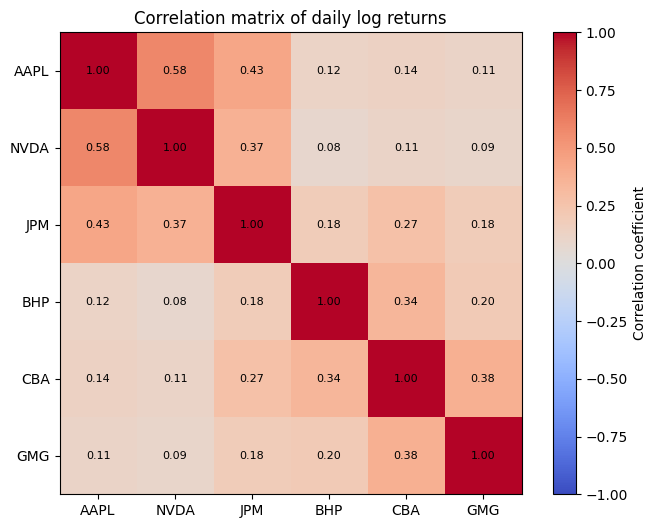

In [15]:
returns_table = pd.DataFrame(log_returns).dropna()
correlation_matrix = returns_table.corr()
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation coefficient')
plt.xticks(range(6), correlation_matrix.columns)
plt.yticks(range(6), correlation_matrix.index)
for i in range(6):
    for j in range(6):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8)
plt.title("Correlation matrix of daily log returns")
plt.show()

The figure shows that all stock are positively correlated, although only at low to moderate levels (0.08-0.58). Correlations within each market are noticeably stronger than those across markets: the two US technology stocks, AAPL and NVDA, display the highest correlation (0.58), whereas US-Australian pairs range only 0.08-0.27. JPM and CBA (banks) form the most correlated cross-market pair (0.27), while NVDA and BHP (tech vs mining) are the least correlated (0.08). These results ndicate that each market has distinct return dynamics, which supports evaluating the models separately across both markets.

In [16]:
# The ASX closes before New York opens, so news from US day t-1 reaches Australia on day t.
# Pair each Australian trading day with the most recent US trading day BEFORE it.
us_stocks, au_stocks = ["AAPL", "NVDA", "JPM"], ["BHP", "CBA", "GMG"]
au_table = pd.DataFrame({s: log_returns[s] for s in au_stocks}).dropna()
us_table = pd.DataFrame({s: log_returns[s] for s in us_stocks}).dropna()

us_previous = pd.merge_asof(au_table.index.to_frame(name="Date", index=False),
                            us_table.rename_axis("Date").reset_index(),
                            on="Date", allow_exact_matches=False).set_index("Date")

lag_rows = []
for u in us_stocks:
    for a in au_stocks:
        lag_rows.append({"US stock": u, "AU stock": a,
                         "Same-day correlation": correlation_matrix.loc[u, a],
                         "US previous day -> AU day": au_table[a].corr(us_previous[u])})
lagged_corr = pd.DataFrame(lag_rows)
lagged_corr.round(2)

,US stock,AU stock,Same-day correlation,US previous day -> AU day
0,AAPL,BHP,0.12,0.17
1,AAPL,CBA,0.14,0.08
2,AAPL,GMG,0.11,0.19
3,NVDA,BHP,0.08,0.13
4,NVDA,CBA,0.11,0.08
5,NVDA,GMG,0.09,0.22
6,JPM,BHP,0.18,0.18
7,JPM,CBA,0.27,0.14
8,JPM,GMG,0.18,0.08


**Effect of the time-zone gap.** The ASX trading day ends before the US trading day starts, so a same-date correlation pairs an Australian day with a US day that happens *after* it. Pairing each Australian day with the *previous* US day gives a different picture. For BHP and GMG the correlation with the previous US day is higher than the same-day figure (e.g. NVDA → GMG 0.22 vs 0.09, AAPL → GMG 0.19 vs 0.11), while for CBA it is lower (JPM → CBA 0.14 vs 0.27). Cross-market links are therefore spread over two consecutive days, and the same-day matrix above understates them for BHP and GMG. They remain weak either way (at most 0.27), so the conclusion that the two markets have distinct return dynamics still holds. The models use no cross-stock inputs, so this does not change the preprocessing; it is context for the cross-market comparison.

### 4.7 Outliers

In [17]:
outliers = []
for s, df in cleaned_data.items():
    # Old method: IQR method to detect outliers
    q1, q3 = df['Close'].quantile([0.25, 0.75])
    upper_bound = q3 + 1.5 * (q3 - q1)
    flagged_outliers = df[df['Close'] > upper_bound]

    # New method: 1st/99th percentile on returns
    r = log_returns[s]
    r_train = r[r.index < '2023-01-01'] # Use data before the test period for training
    low, high = r_train.quantile([0.01, 0.99])

    outliers.append({
        "Stock": s,
        "Price IQR outliers": len(flagged_outliers),
        "First flagged date": flagged_outliers.index.min().date() if len(flagged_outliers) > 0 else None,
        "Return outliers":((r_train < low) | (r_train > high)).sum()})

pd.DataFrame(outliers)

,Stock,Price IQR outliers,First flagged date,Return outliers
0,AAPL,0,None,26
1,NVDA,347,2024-05-29,26
2,JPM,191,2025-01-17,26
3,BHP,0,None,26
4,CBA,143,2025-02-12,26
5,GMG,0,None,26


The percentile approach affects only a small, fixed share of observations (about 2%), the most extreme days, rather than hundreds of consecutive days. Below we draw two graphs, using NVDA as an example, to clearly show the difference when removing outliers using old and new method.

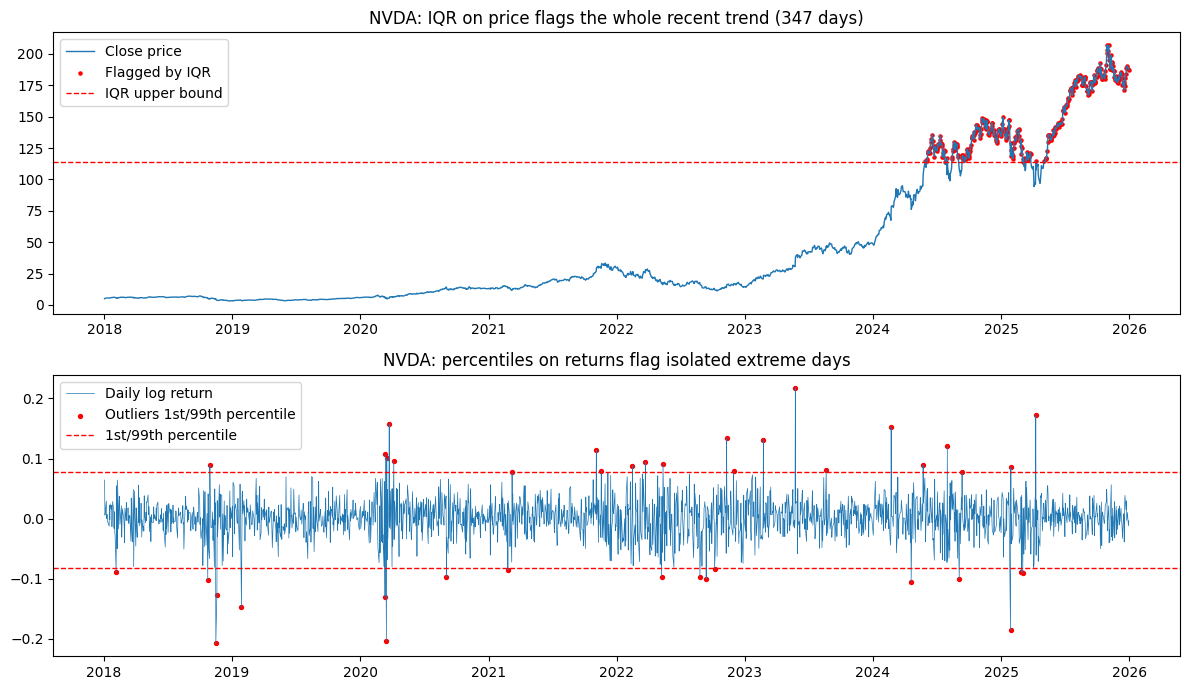

In [18]:
s = 'NVDA'
df = cleaned_data[s]
r = log_returns[s]
fig, axes = plt.subplots(2,1, figsize = (12,7))

# Old method
q1,q3 = df['Close'].quantile([0.25,0.75])
upper_bound = q3 + 1.5 * (q3 - q1)
flagged_outliers = df['Close'] > upper_bound
axes[0].plot(df.index, df['Close'], linewidth =1, label = 'Close price')
axes[0].scatter(df.index[flagged_outliers], df['Close'][flagged_outliers], color='red', s=5, label ='Flagged by IQR')
axes[0].axhline(upper_bound, color='red', linestyle='--', linewidth = '1', label = 'IQR upper bound')
axes[0].set_title(f"{s}: IQR on price flags the whole recent trend ({flagged_outliers.sum()} days)")
axes[0].legend()

# New method
r_train = r[r.index < '2023-01-01']
low, high = r_train.quantile([0.01, 0.99])
outside = (r<low) | (r>high)
axes[1].plot(r.index, r, linewidth=0.5, label = 'Daily log return')
axes[1].scatter(r.index[outside], r[outside], color='red', s=8, label='Outliers 1st/99th percentile')
axes[1].axhline(low, color='red', linestyle='--', linewidth =1)
axes[1].axhline(high, color='red', linestyle='--', linewidth =1, label = '1st/99th percentile')
axes[1].set_title(f"{s}: percentiles on returns flag isolated extreme days")
axes[1].legend()
plt.tight_layout()
plt.show()

In [19]:
# test-period returns beyond the training limits
# For each fold, the 1st/99th percentile limits come from returns BEFORE the test quarter.
# Count how many test-quarter returns fall outside them: these are the days winsorisation
# would clip in the model inputs. Unlike the fixed 2% above, this number can vary.
rows = []
for s, r in log_returns.items():
    for k, start, end in folds:
        r_train = r[r.index < start]
        low, high = r_train.quantile([0.01, 0.99])
        r_test = r[(r.index >= start) & (r.index <= end)]
        rows.append({"Stock": s, "Fold": k,
                     "% test days outside limits": 100 * ((r_test < low) | (r_test > high)).mean()})
test_outside = pd.DataFrame(rows)
test_outside_summary = (test_outside.groupby("Stock")["% test days outside limits"]
                        .agg(["mean", "max"]).round(1).reindex(stock))
test_outside_summary["Fold with max"] = (test_outside.loc[test_outside.groupby("Stock")["% test days outside limits"].idxmax()]
                                         .set_index("Stock")["Fold"])
test_outside_summary

,mean,max,Fold with max
Stock,,,
AAPL,0.9,8.1,10
NVDA,2.0,6.7,9
JPM,1.1,4.8,10
BHP,0.5,3.3,10
CBA,0.9,3.3,10
GMG,1.9,4.9,9



**Test-period returns outside the training limits.** The "Return outliers" column above is 26 for every stock by construction: a 1st/99th percentile cut-off always flags about 2% of the rows it was computed on. The more informative question is how often the *test* quarters go beyond limits learned from the past. On average this happens on 0.5% (BHP) to 2.0% (NVDA) of test days, roughly one day per quarter, so winsorisation changes very few test inputs. The exceptions are in 2025: AAPL reaches 8.1% in fold 10 (Apr–Jun 2025, which contains the April 2025 sell-off) and NVDA 6.7% in fold 9 (Jan–Mar 2025). These are the quarters where clipped inputs differ most from the raw data, so they are worth checking when raw and winsorised results are compared.

### 4.8 Close vs Adj Close

The dataset has two closing prices. `Close` is adjusted for stock splits only; `Adj Close` is also adjusted for dividends. On an ex-dividend day the share price drops by roughly the dividend paid, so a return computed from `Close` shows a fall that is not a market movement. This section measures how large that effect is for each stock.

In [20]:
# ---- Close vs Adj Close ----
# Close is adjusted for stock splits only. Adj Close is also adjusted for dividends.
# On an ex-dividend day the Close drops by roughly the dividend, which shows up as a
# negative return that the OHLCV inputs cannot explain.
adj_rows = []
for s, df in cleaned_data.items():
    r_close = np.log(df["Close"] / df["Close"].shift(1)).dropna()
    r_adj = np.log(df["Adj Close"] / df["Adj Close"].shift(1)).dropna()
    gap = 100 * (r_adj - r_close)          # % points; positive on ex-dividend days
    adj_rows.append({
        "Stock": s,
        "Days with gap > 0.5%": (gap > 0.5).sum(),
        "Largest gap (%)": gap.max(),
        "Largest gap date": gap.idxmax().date(),
        "Total return 2018-25, Close (%)": 100 * (np.exp(r_close.sum()) - 1),
        "Total return 2018-25, Adj Close (%)": 100 * (np.exp(r_adj.sum()) - 1)})
adj_table = pd.DataFrame(adj_rows)
adj_table.round(2)

,Stock,Days with gap > 0.5%,Largest gap (%),Largest gap date,"Total return 2018-25, Close (%)","Total return 2018-25, Adj Close (%)"
0,AAPL,0,0.45,2019-02-08,534.18,576.96
1,NVDA,0,0.30,2019-01-09,3665.86,3707.11
2,JPM,30,1.03,2020-04-03,199.60,272.88
3,BHP,17,7.06,2021-09-02,70.64,206.93
4,CBA,16,3.11,2018-08-15,101.06,181.66
5,GMG,12,1.40,2018-12-28,266.71,316.22


> *Newly added by Claude*

For AAPL and NVDA the difference is negligible (no day above 0.5%). For JPM and the three Australian stocks it is large: over 2018–2025 BHP's `Close` rose 70.6% but its dividend-adjusted return was 206.9%, and CBA's 101.1% vs 181.7%. BHP has 17 days on which the `Close`-based return understates the true return by more than 0.5 percentage points, the largest being 7.06% on 2021-09-02.

**Decision:** the target remains `Close`, because RQ1 asks about the next-day closing price and the models are evaluated against actual closing prices. The ex-dividend drops are recorded as a limitation: the models cannot anticipate them from OHLCV inputs, which will slightly raise errors for BHP, CBA, GMG and JPM on those days. A sensitivity check that rebuilds the return features from `Adj Close` could be run if time allows.

## 5. Preprocessing

### 5.1 Features

**Changes from the Assessment 2 plan.** The preprocessing below differs from the plan in Assessment 2. The changes and reasons are:

| Assessment 2 plan | Now | Reason |
|---|---|---|
| Target: next-day closing price | Target: next-day log return, converted back to a price for evaluation | Test prices often exceed the training maximum (up to 97% of a quarter for NVDA, Section 4.2), forcing the models to extrapolate. Recommended in the Assessment 2 feedback. |
| Min-Max scaling to [0, 1] | `StandardScaler` (mean 0, std 1) | The return features are centred on zero and roughly symmetric, which standardisation preserves. Both scalers would be fitted per fold on training rows only; the change is about the shape of the inputs, not leakage. |
| Winsorisation at the 5th/95th percentile of prices | Winsorisation at the 1st/99th percentile of returns | Feedback: capping a trending price series clips the test period. On returns, 5th/95th would alter about 10% of all days, most of them ordinary trading days; 1st/99th limits only the most extreme ~2% (Section 4.7). |
| IQR outlier detection on prices | Percentile limits on returns | IQR on prices flags the recent upward trend, not genuine outliers (Section 4.7). |
| Static 70/15/15 split | 12-fold expanding-window walk-forward; last 15% of each fold's pre-test data is validation | Evaluates the models over 12 different market periods (Section 3). |
| No baseline | Naive persistence baseline | Recommended in the Assessment 2 feedback (Section 5.5). |
| Compare raw vs winsorised data | `winsor=None` option in `preprocess_fold` | The comparison needs trained models, so it is run in the modelling sections: Section 6 for LSTM and CNN-LSTM, Section 7 for ARIMA (`clipped` vs `unclipped`). |

EDA reveals that stock prices tend to exhibit upward, non-stationary trend over time. Furthermore, prices during the test period often fall outside the range observed during the training phase. Using raw Open, High, Low, Close and Volume (OHLCV) data as model inputs would force the model to exptrapolate, increasing the risk of inaccurate predictions. To address this, all five OHLCV variables are transformed into variations relative to the previous day's closing price

| Feature | Formula | Meaning |
|---|---|---|
| Open | $ln\left(\frac{Open_t}{Close_{t-1}}\right)$ | overnight gap 
| High | $ln\left(\frac{High_t}{Close_{t-1}}\right)$ | how far the price rose during the day 
| Low | $ln\left(\frac{Low_t}{Close_{t-1}}\right)$ | how far the price fell during the day 
| Close | $ln\left(\frac{Close_t}{Close_{t-1}}\right)$ | daily log return 
| Volume | $ln(Volume_t) - ln(Volume_{t-1})$ | change in trading volume 

**Target variable** will be turned back to price. A predicted return is turned back into a price with: ***predicted price = today's close x exp(predicted return)***

In [21]:
def transform_features(df):
    # Turn raw OHLCV prices into the five return-based features
    prev_close = df['Close'].shift(1)   # yesterday's close
    var = pd.DataFrame(index=df.index)
    var['Open'] = np.log(df['Open']/prev_close)
    var['High'] = np.log(df['High']/prev_close)
    var['Low'] = np.log(df['Low']/prev_close)
    var['Close'] = np.log(df['Close']/prev_close)
    var['Volume'] = np.log(df['Volume'] + 1).diff()   # +1 avoids log(0), first row has no yesterday
    return var.dropna()
# Use AAPL as an example
transform_features(cleaned_data['AAPL']).head()

,Open,High,Low,Close,Volume
Date,,,,,
2018-01-03,0.001624,0.013380,-0.001627,0.000000,0.144129
2018-01-04,0.001624,0.007173,-0.000929,0.004634,-0.274392
2018-01-05,0.002309,0.013318,0.000000,0.011263,0.053181
2018-01-08,-0.003664,0.003423,-0.006191,-0.003664,-0.140059
2018-01-09,0.001146,0.003892,-0.005521,-0.000229,0.048226


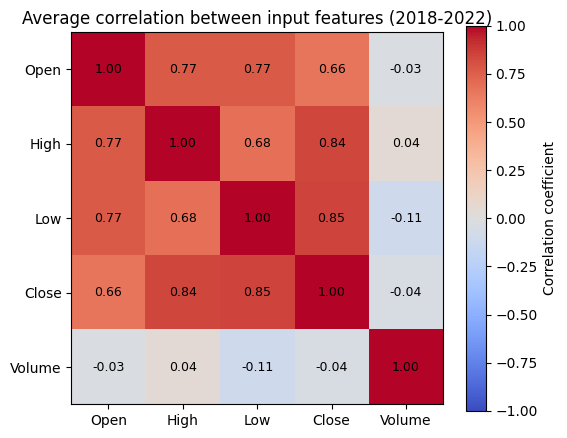

,Pair,Min,Average,Max
0,Open - High,0.71,0.77,0.88
1,Open - Low,0.71,0.77,0.89
2,Open - Close,0.59,0.66,0.81
3,Open - Volume,-0.06,-0.03,0.02
4,High - Low,0.56,0.68,0.84
5,High - Close,0.79,0.84,0.91
6,High - Volume,-0.02,0.04,0.16
7,Low - Close,0.79,0.85,0.91
8,Low - Volume,-0.18,-0.11,-0.05
9,Close - Volume,-0.10,-0.04,0.03


In [22]:
# Correlation between the five input features ----
# Uses the initial training period only (before 2023), averaged over the six stocks.
# Strongly correlated inputs matter for SHAP (RQ2): the model can rely on either feature,
# so credit may be split between them differently from stock to stock.
feature_corrs = {s: transform_features(df[df.index < "2023-01-01"]).corr() for s, df in cleaned_data.items()}
avg_feature_corr = sum(feature_corrs.values()) / len(feature_corrs)

plt.figure(figsize=(6, 5))
plt.imshow(avg_feature_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")
plt.xticks(range(5), avg_feature_corr.columns)
plt.yticks(range(5), avg_feature_corr.index)
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{avg_feature_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.title("Average correlation between input features (2018-2022)")
plt.show()

# Range across the six stocks for each feature pair
pairs = [(a, b) for i, a in enumerate(avg_feature_corr.columns) for b in avg_feature_corr.columns[i + 1:]]
pd.DataFrame([{"Pair": f"{a} - {b}",
               "Min": min(c.loc[a, b] for c in feature_corrs.values()),
               "Average": avg_feature_corr.loc[a, b],
               "Max": max(c.loc[a, b] for c in feature_corrs.values())} for a, b in pairs]).round(2)

**Feature correlation and SHAP.** Four of the five inputs are strongly correlated: Close with High (0.84) and Low (0.85), and Open with High and Low (0.77). This is expected, because all four are measured against the same previous close: on a day the stock rises, Open, High and Close all tend to be positive. Volume change is almost uncorrelated with the price features (−0.11 to 0.04).

+ **For prediction** this is not a problem; the features simply carry overlapping information.
+ **For SHAP (RQ2)** it matters. When features are correlated, a model can rely on either one, and SHAP may split the credit between them differently for different stocks or folds. Differences in feature rankings between stocks could then reflect this rather than a real difference in behaviour. This should be stated when interpreting the Spearman correlations of SHAP rankings, and one option is to also compare rankings with the four price features grouped together.

### 5.2 The per-fold preprocessing function

For one stock and one fold, `preprocess_fold` does these steps in the following order:

1. **Keep only data up to the end of the test quarter**. For example, AAPL dataset is from 2/1/2018 to 30/12/2025. Fold 1 uses the first quarter of 2023 (1/1/2023-31/3/2023) as the test quarter. The dataset after 31/3 is not included in Fold 1
2. **Split the dataset**: train (first 85% of the pre-test data) - validation (last 15% of the pre-test data) - test (the quarter)
3. **Winsorisation**: In this step, the 1st and 99th percentile thresholds of each feature are calculated using only the training data of the corresponding fold. Values beyond these thresholds in the training, validation and test sets are then replace with the threshold values themselves. This limits the influence of extreme trading days on model training without removing any observations, so the continuity of the time series is preserved. The thresholds are estimated from the training data alone to prevent data leakage: if they were calculated on the full dataset, the model would indirectly gain prior nowledge of the volatility in the test period. Each fold therefore has its own thresholds, which are recalculated as the training window expands by one quarter. The target values of the test set are never clipped, so the models are always evaluated against actual prices.
4. `StandardScaler`: After winsorisation, the features are standardised using StandardScaler, which transforms each feature to a common scale with a mean of 0 and a std of 1, using the formular:
$$
z = \frac{x - \mu}{\sigma}
$$
where $\mu$ is the mean and $\sigma$ is the standard deviation of the feature. This step is necessary because the features differ in magnitude. When all features share a common scale, neural networks train more stably and efficiently.
5. **Build 60-day sequence** To predict day t, the inputs is day t-60 to day t-1.

6. **The test target is never clipped**, so the models are always evaluated against the real prices.

In [23]:
LOOKBACK = 60           # each input - the previous 60 trading days
VAL_FRAC = 0.15       # last 15% of each fold's training data = validation set
WINSOR = (0.01, 0.99)   # clip at the 1st and 99th percentiles 

In [24]:
# the per-fold preprocessing function

def preprocess_fold (df, test_start, test_end, winsor=WINSOR):
    # Step 1: keep data only up to the end of this fold's test quarter
    df = df[df.index <= test_end]
    feats = transform_features(df) # 5 return-based features (from 5.1)
    dates = feats.index
    close = df['Close'].reindex(dates)  # closing prices on the same dates

    # Step 2: split dates into train/validation/test
    pre_test_dates = dates[dates < test_start]      #everything before the test quarter
    val_start = pre_test_dates[int(len(pre_test_dates) * (1 - VAL_FRAC))]   # first validation day (last 15%)
    is_train_row = dates < val_start 

    # Step 3: winsorisation (limits learned from training rows only)
    if winsor is not None:
        low = feats[is_train_row].quantile(winsor[0]) # 1st percentile of each feature
        high = feats[is_train_row].quantile(winsor[1]) # 99th percentile of each feature
        feats_clipped = feats.clip(lower=low, upper=high, axis =1) #clipped the value to the limit
    else:
        feats_clipped = feats.copy() # winsor is none, feats_clipped is a copy of original features

    # Step 4: StandardScaler (fitted on TRAINING rows only)
    scaler = StandardScaler().fit(feats_clipped[is_train_row])
    X_all = scaler.transform(feats_clipped)     # scaled inputs for every day

    # Target = that day's log return
    # Train/validation use te clipped value, the test period uses the REAL (unclipped)
    y_real = feats['Close'].values          # real value
    y_clipped = feats_clipped['Close'].values   # winsorised value
    y_mean = y_clipped[is_train_row].mean()
    y_std = y_clipped[is_train_row].std()

    # Step 5: build 60-day sequences
    X, y, target_dates = [], [], []
    for i in range (LOOKBACK, len(dates)):
        d = dates[i]        # the day we want to predict
        X.append(X_all[i - LOOKBACK:i])     # the 60 days before it
        # Step 6: test targets are never clipped
        target = y_real[i] if d >= test_start else y_clipped[i]
        y.append((target - y_mean)/y_std)
        target_dates.append(d)

    X = np.array(X)
    y = np.array(y)
    target_dates = pd.DatetimeIndex(target_dates)

    # Assign each sequence to train/validation/test by the date it predicts
    train = target_dates < val_start
    val = (target_dates >= val_start) & (target_dates < test_start)
    test = target_dates >= test_start

    return {
        "X_train": X[train], "y_train": y[train],
        "X_val": X[val], "y_val": y[val],
        "X_test": X[test], "y_test": y[test],
        "test_dates": target_dates[test],
        "test_prev_close": close.shift(1)[target_dates[test]].values,    # yesterday's close
        "test_actual": close[target_dates[test]].values,
        "y_mean": y_mean, "y_std": y_std,
        "val_start": val_start,
        # Newly added by Claude: also return the fitted limits and scaler so leakage check 2 can compare them
        "winsor_low": low if winsor is not None else None,
        "winsor_high": high if winsor is not None else None,
        "scaler": scaler
    }

In [25]:
# convert predictions back to prices
def to_price (y_scaled, prev_close, y_mean, y_std):
    # convert a scaled predicted log return back to a closing price
    predicted_return = y_scaled * y_std + y_mean #undo the scaling
    return prev_close * np.exp(predicted_return)

In [26]:
# Use NVIDIA to check
k, start, end = folds[0]
fold = preprocess_fold(cleaned_data['NVDA'], start, end)

print("Validation starts:", fold['val_start'].date())
print("X_train:", fold['X_train'].shape, " -> (samples, 60 days, 5 features)")
print("X_Val: ", fold["X_val"].shape)
print("X_test: ", fold['X_test'].shape)

# Converting the TRUE test targets back must give the TRUE prices
back = to_price(fold['y_test'], fold['test_prev_close'], fold['y_mean'], fold['y_std'])
print("Conversion back to price is exact:", np.allclose(back, fold['test_actual']))

Validation starts: 2022-04-01
X_train: (1009, 60, 5)  -> (samples, 60 days, 5 features)
X_Val:  (189, 60, 5)
X_test:  (62, 60, 5)
Conversion back to price is exact: True


### 5.3 Run the preprocessing for every stock and fold

This section executes the `preprocess_fold` function for all 6 stocks across 12 folds, totaling 72 iterations. The results from each iteration are stored in `all_folds` for use in the subsequent model training phase. For each stock and each fold, the code performs two checks to determine whether the test data falls outside the range learned by the model. The first check, based on price, calculates the proportion of days in the test quarter where the closing price exceeds the highest price observed during the training period. The second check, based on log returns, calculates the proportion of target values ​​in the test set that fall outside the range (minimum to maximum) of the target values ​​in the training set. These results are averaged across the 12 folds and presented in a comparison table. When using price, this proportion is quite high—averaging 39.1% for NVDA, 34.4% for JPM, and 30.6% for CBA. In contrast, when using log returns, the proportion drops to approximately 0.7–2.0% for all stocks. This indicates that shifting the target from price to log returns ensures the model rarely needs to extrapolate beyond the range of the data it has already learned.

In [27]:
# Run the preprocessing for every stock and every fold
all_folds = {}   # keeps every fold's data for the modelling phase, e.g. all_folds[('NVDA', 1)]
rows = []        # one row per stock and fold

for name in stock:
    for k, start, end in folds:
        # Preprocess this stock for this fold
        fold = preprocess_fold(cleaned_data[name], start, end)
        all_folds[(name, k)] = fold

        # RETURNS: % of test targets outside the range seen in training
        low  = fold['y_train'].min()
        high = fold['y_train'].max()
        outside = (fold['y_test'] < low) | (fold['y_test'] > high)

        # PRICES (same check as section 3.2): % of test days above the highest training price
        close = cleaned_data[name]['Close']
        train_max  = close[close.index < start].max()
        test_close = close[(close.index >= start) & (close.index <= end)]
        above_max  = test_close > train_max

        rows.append({'Stock': name,
                     'Fold': k,
                     'Prices: % test days above training max':         above_max.mean() * 100,
                     'Returns: % test targets outside training range': outside.mean() * 100})

summary = pd.DataFrame(rows)

# Compare prices vs returns, averaged over the 12 folds
comparison = (summary.groupby('Stock')[['Prices: % test days above training max',
                                        'Returns: % test targets outside training range']]
                     .mean()
                     .round(1)
                     .reindex(stock))     # keep the original stock order
comparison

,Prices: % test days above training max,Returns: % test targets outside training range
Stock,,
AAPL,22.5,0.8
NVDA,39.1,2.0
JPM,34.4,1.1
BHP,3.3,0.7
CBA,30.6,0.8
GMG,13.0,1.9


### 5.4 ARIMA Input: Selecting the Differencing Order (d) for each fold

Unlike LSTM and CNN-LSTM, ARIMA does not require data normalization or the use of 60-day rolling windows. This model operates directly on the log-transformed closing prices. However, ARIMA requires the data series to be stationary. Therefore, it is necessary to determine the parameter $d$—the number of times the series must be differenced to achieve stationarity. In this step, the Augmented Dickey-Fuller (ADF) test is applied to the training data for each fold, which includes only the periods prior to the test quarter, ensuring that no future information is leaked. The procedure is as follows: if the ADF $p$-value is less than 0.05, the series is considered stationary, and the current value of $d$ is maintained. Otherwise, the series is differenced once more, and the test is repeated. The results indicate that $d = 1$ in all 72 cases (6 stocks × 12 folds). This implies that the log-transformed prices are non-stationary, but they become stationary after a single round of differencing. A first-order difference of log prices is equivalent to the log return. This finding is consistent with the ADF test results from the Exploratory Data Analysis (EDA) section (4.3) and further demonstrates that both ARIMA and the deep learning models are, in essence, predicting the same quantity: the daily log return.

**Outliers.** Winsorisation is not required by the ARIMA model itself, but its maximum-likelihood estimates and the AIC choice of $ and $ are sensitive to extreme observations (Fox, 1972; Tsay, 1986; Chen & Liu, 1993). ARIMA is therefore run under the same two conditions as the deep-learning models: **clipped**, where the log returns are winsorised at the 1st/99th percentiles learned from the training rows of each fold (the same rule as `preprocess_fold`), and **unclipped**, where the raw log returns are used. Test-day closing prices are never clipped. The modelling is done in Section 7.

In [28]:
def choose_d(series, max_d=2):
    """Return the smallest number of differences that makes the series stationary (ADF p < 0.05)."""
    for d in range(max_d + 1):
        p_value = adfuller(series)[1]     # ADF test, [1] is the p-value
        if p_value < 0.05:                # p < 0.05: reject "non-stationary", so the series is stationary
            return d
        series = np.diff(series)          # not stationary yet: take one more difference and test again
    return max_d

d_table = {}
for name in stock:
    d_values = []
    for k, start, end in folds:
        # TRAINING data only: closing prices before the test quarter starts
        train_close = cleaned_data[name].loc[cleaned_data[name].index < start, 'Close']
        log_price = np.log(train_close).values          # ARIMA works on the log price
        d_values.append(choose_d(log_price))
    d_table[name] = d_values

# Table: rows = stocks, columns = folds
d_table = pd.DataFrame(d_table, index=[f'Fold {k}' for k, _, _ in folds]).T
d_table

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Fold 6,Fold 7,Fold 8,Fold 9,Fold 10,Fold 11,Fold 12
AAPL,1,1,1,1,1,1,1,1,1,1,1,1
NVDA,1,1,1,1,1,1,1,1,1,1,1,1
JPM,1,1,1,1,1,1,1,1,1,1,1,1
BHP,1,1,1,1,1,1,1,1,1,1,1,1
CBA,1,1,1,1,1,1,1,1,1,1,1,1
GMG,1,1,1,1,1,1,1,1,1,1,1,1


**Note on the fairness of the comparison.** ARIMA and the deep-learning models do not receive identical inputs: ARIMA uses only the log closing price (as daily log returns), while LSTM and CNN-LSTM use five standardised return features. To separate the effect of outlier treatment from the effect of the model, all three models are run in both conditions, clipped and unclipped, with the same winsorisation rule. All models are evaluated on the same test days against the same unclipped closing prices, so the error metrics are directly comparable. However, within the same condition a performance difference still reflects the whole approach (model + inputs), not the model architecture alone. This should be stated when answering RQ1.

### 5.5 Naive baseline (tomorrow's price = today's price)

The part is to define the naive baseline. It assumes that tomorrow’s closing price will be identical to today’s closing price. This method requires no training and involves no parameters. Nevertheless, it often yields a relatively low error rate, as stock prices typically change very little from one day to the next. For this reason, the naive baseline serves as a minimum benchmark for evaluating models such as ARIMA, LSTM, and CNN-LSTM. Without this point of comparison, it would be impossible to determine whether an error rate is considered good or poor. A model is only truly valuable if its error rate is lower than that of the naive baseline; if the error is equal to or higher, the model has failed to learn any useful information and is merely “repeating yesterday’s price.” This phenomenon explains why many predicted trajectories appear to align closely with actual prices while, in reality, they are simply lagged by one day. The naive baseline is calculated for each stock across all 12 folds, using the same metrics—RMSE, MAE, and MAPE—as those applied to the primary models. The fourth planned metric, the Sharpe ratio of a simple buy/sell strategy, needs a predicted direction, which the naive forecast does not have; it is reported for the models in Section 8, with the buy-and-hold Sharpe ratio as the reference.

In [29]:
naive = []
for name, df in cleaned_data.items():
    for k, start, end in folds:
        test = (df.index >= start) & (df.index <= end)
        actual = df["Close"][test]
        predicted = df["Close"].shift(1)[test]              # yesterday's close
        error = actual - predicted
        naive.append({"Stock": name, "Fold": k,
                      "RMSE": np.sqrt((error ** 2).mean()),
                      "MAE": error.abs().mean(),
                      "MAPE (%)": 100 * (error.abs() / actual).mean()})
naive = pd.DataFrame(naive)
naive.head()

# mean ± std over the 12 folds
naive_summary = naive.groupby("Stock")[["RMSE", "MAE", "MAPE (%)"]].agg(["mean", "std"]).round(3)
naive_summary

RMSE           MAE        MAPE (%)       
        mean    std   mean    std     mean    std
Stock                                            
AAPL   3.065  1.163  2.223  0.672    1.103  0.312
BHP    0.584  0.076  0.451  0.056    1.054  0.150
CBA    1.633  0.621  1.226  0.445    0.903  0.151
GMG    0.464  0.146  0.342  0.101    1.176  0.156
JPM    2.957  1.246  2.110  0.824    1.002  0.217
NVDA   2.882  1.597  2.178  1.234    2.257  0.565

### 5.6 Data Leakage check

Data leakage occurs when a model inadvertently “sees” information from the future during the training or prediction process. This leads to artificially high performance on the test set, results that the model cannot replicate when deployed in a real-world scenario. Such errors are notoriously difficult to detect by eye, as the code executes without throwing any exceptions. This section verifies that the preprocessing pipeline is free from data leakage. The approach is as follows: intentionally “corrupt” the future data by multiplying all values ​​occurring after the 30th day of the test quarter by a factor of three. Then, re-run the entire preprocessing pipeline and compare the output against the original results. If the pipeline is implemented correctly, components derived solely from historical data should remain unchanged. These components include the training and validation sets, winsorization thresholds, scalers, and the first 30 input sequences of the test set. If any of these elements change, it indicates that information from the future has leaked into the past. This validation step is particularly crucial here, given the use of walk-forward validation, winsorization, and fold-specific normalization—processes where it is easy to accidentally incorporate test data. This check provides concrete evidence that the model’s subsequent performance evaluation is honest and reliable.

In [30]:
# Corrupt all prices AFTER the 31st test day, preprocess again, and check that
# nothing that should only use past data has changed.

k, start, end = folds[4]          # use fold 5 as an example

for name, df in cleaned_data.items():
    # Trading days in this fold's test quarter
    test_days = df.index[(df.index >= start) & (df.index <= end)]

    # Corrupt the future: multiply every price and volume after the 31st test day by 3
    corrupted = df.copy()
    corrupted.loc[corrupted.index > test_days[30], ["Open", "High", "Low", "Close", "Volume"]] *= 3

    # Preprocess the original data and the corrupted data
    a = preprocess_fold(df, start, end)
    b = preprocess_fold(corrupted, start, end)

    # Check 1: everything built from past data must be exactly the same
    #   - training inputs and targets
    #   - validation inputs and targets
    #   - the first 31 test inputs (their 60-day windows end before the corrupted days)
    same = (np.allclose(a["X_train"], b["X_train"]) and np.allclose(a["y_train"], b["y_train"]) and
            np.allclose(a["X_val"],   b["X_val"])   and np.allclose(a["y_val"],   b["y_val"])   and
            np.allclose(a["X_test"][:31], b["X_test"][:31]))

    # Check 2: the later test inputs MUST change (proves the corruption actually happened)
    changed = not np.allclose(a["X_test"][31:], b["X_test"][31:])

    print(f"{name}: no leakage = {same}, later test inputs changed = {changed}")

AAPL: no leakage = True, later test inputs changed = True
NVDA: no leakage = True, later test inputs changed = True
JPM: no leakage = True, later test inputs changed = True
BHP: no leakage = True, later test inputs changed = True
CBA: no leakage = True, later test inputs changed = True
GMG: no leakage = True, later test inputs changed = True


**Leakage check 2: corrupt the validation period.** The check above only changes test-period data. This second check multiplies every price and volume in the **validation** period by 3 and compares the winsorisation limits and the scaler directly. Because both must be learned from training rows only, they and the training sequences must stay exactly the same, while the validation inputs must change.

In [31]:
# ---- leakage check 2 - corrupt the VALIDATION period ----
# The winsorisation limits and the scaler must be learned from TRAINING rows only.
# So changing the validation data must leave them, and the training sequences, unchanged.
k, start, end = folds[4]          # fold 5, same as above

for name, df in cleaned_data.items():
    a = preprocess_fold(df, start, end)

    # Multiply every price and volume in the validation period by 3
    corrupted = df.copy()
    is_val = (corrupted.index >= a["val_start"]) & (corrupted.index < start)
    corrupted.loc[is_val, ["Open", "High", "Low", "Close", "Volume"]] *= 3
    b = preprocess_fold(corrupted, start, end)

    same_limits = (np.allclose(a["winsor_low"], b["winsor_low"]) and
                   np.allclose(a["winsor_high"], b["winsor_high"]))
    same_scaler = (np.allclose(a["scaler"].mean_, b["scaler"].mean_) and
                   np.allclose(a["scaler"].scale_, b["scaler"].scale_))
    same_train = np.allclose(a["X_train"], b["X_train"]) and np.allclose(a["y_train"], b["y_train"])
    val_changed = not np.allclose(a["X_val"], b["X_val"])   # proves the corruption happened

    print(f"{name}: limits unchanged = {same_limits}, scaler unchanged = {same_scaler}, "
          f"training data unchanged = {same_train}, validation changed = {val_changed}")

AAPL: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
NVDA: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
JPM: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
BHP: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
CBA: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
GMG: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True


All six stocks pass: the winsorisation limits, the scaler and the training data are identical after the validation period is corrupted, and the validation inputs did change. Together with the first check, this confirms that nothing from the validation or test periods is used to fit the preprocessing.

## 6. LSTM and CNN-LSTM Model Development

Implementation follows the supplied **Model Development Plan**, sections 2–4. Run sections 1–5 first to create `cleaned_data`, `folds`, `preprocess_fold`, and `to_price`. Models predict **standardised next-day log returns**, converted to closing prices using the previous day's actual close. Each stock/quarter/seed gets fresh model weights. **No test-quarter outcomes are used to choose hyperparameters or stopping epochs.**

**Runtime:** 6 stocks × 12 folds × 3 seeds × 2 architectures = **432 fits per clipping condition**; the two planned clipping conditions require **864 fits**, plus tuning. Use a GPU if possible. For a quick smoke test, set `RUN_FULL = False` (not reportable as the full experiment). With `TRAIN_MODELS = False` (the default) the tuning and training steps are skipped and the saved results of the full run are loaded from `model_outputs/`, so Sections 6.4–6.5 can be rerun in minutes.

In [32]:
import os, time, gc, json, random
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')  # hide TensorFlow C++ log spam (e.g. use_unbounded_threadpool); only works if set before TF is first imported
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, Conv1D, MaxPooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

MODEL_DIR = Path('model_outputs')
MODEL_DIR.mkdir(exist_ok=True)
SEEDS = (0, 1, 2)
TRAIN_MODELS = False  # False = skip tuning and training, load the saved full-run results from model_outputs/ (~6 h)
RUN_FULL = True  # False = smoke test only (AAPL, fold 1, one seed, clipped)
RUN_TUNING = True  # set True to perform the plan's folds 1–2 validation-only check
RUN_UNCLIPPED = True
EPOCHS = 100
BATCH_SIZE = 32

print('TensorFlow:', tf.__version__, 'GPUs:', tf.config.list_physical_devices('GPU'))
assert 'preprocess_fold' in globals() and 'cleaned_data' in globals()
assert 'folds' in globals() and 'to_price' in globals()

TensorFlow: 2.21.0 GPUs: []


### 6.1 Architecture and reproducibility

**LSTM:** Input (60×5) → LSTM(64, sequence) → Dropout(0.2) → LSTM(64) → Dropout(0.2) → Dense(1, linear).

**CNN-LSTM:** Input (60×5) → Conv1D(64, kernel 3, ReLU, same) → MaxPool(2) → LSTM(64) → Dropout(0.2) → Dense(16, ReLU) → Dense(1, linear).

In [33]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

def build_model(kind, window=60, units=64, lr=0.001, filters=64, kernel=3):
    if kind == 'LSTM':
        model = Sequential([
            Input(shape=(window, 5)),
            LSTM(units, return_sequences=True), Dropout(0.2),
            LSTM(units), Dropout(0.2),
            Dense(1, activation='linear')
        ])
    elif kind == 'CNN-LSTM':
        model = Sequential([
            Input(shape=(window, 5)),
            Conv1D(filters=filters, kernel_size=kernel, activation='relu', padding='same'),
            MaxPooling1D(pool_size=2), LSTM(units), Dropout(0.2),
            Dense(16, activation='relu'), Dense(1, activation='linear')
        ])
    else:
        raise ValueError(kind)
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model

def fit_once(kind, fold_data, seed, config, save_path=None):
    set_seed(seed)
    tf.keras.backend.clear_session()
    model = build_model(kind, **config)
    callback = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    started = time.perf_counter()
    history = model.fit(
        fold_data['X_train'], fold_data['y_train'],
        validation_data=(fold_data['X_val'], fold_data['y_val']),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
        callbacks=[callback], verbose=0
    )
    seconds = time.perf_counter() - started
    val_pred = model.predict(fold_data['X_val'], verbose=0).reshape(-1)
    test_pred = model.predict(fold_data['X_test'], verbose=0).reshape(-1)
    if save_path is not None:
        model.save(str(save_path))
    result = {
        'val_mse': float(np.mean((fold_data['y_val'] - val_pred)**2)),
        'zero_val_mse': float(np.mean(fold_data['y_val']**2)),
        'best_epoch': int(np.argmin(history.history['val_loss']) + 1),
        'best_val_loss': float(np.min(history.history['val_loss'])),
        'seconds': float(seconds),
        'history': history.history,
        'test_pred_scaled': test_pred,
        'val_pred_scaled': val_pred,
    }
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return result

for kind in ('LSTM', 'CNN-LSTM'):
    m = build_model(kind)
    print(kind, 'parameters:', m.count_params())
    del m


LSTM parameters: 51009
CNN-LSTM parameters: 35105


### 6.2 Validation-only hyperparameter check (folds 1–2)

The plan requires comparing eight configurations for LSTM (30/60 days × 32/64 units × 0.001/0.0005 learning rate), and CNN-LSTM alternatives (30/60 days × 32/64 filters × kernels 3/5). **The existing preprocessing function has a global `LOOKBACK`; the helper below temporarily changes it and restores it.** All tuning uses validation MSE only. Keep the original configuration unless an alternative improves the average validation MSE by **more than 2%**. The same chosen configuration is then frozen for all folds.

In [34]:
from itertools import product

def get_fold(stock_name, fold_number, winsor=(0.01, 0.99), window=60):
    global LOOKBACK
    old = LOOKBACK
    try:
        LOOKBACK = window
        _, start, end = folds[fold_number - 1]
        return preprocess_fold(cleaned_data[stock_name], start, end, winsor=winsor)
    finally:
        LOOKBACK = old

DEFAULT_CONFIG = {
    'LSTM': {'window': 60, 'units': 64, 'lr': 0.001},
    'CNN-LSTM': {'window': 60, 'units': 64, 'lr': 0.001, 'filters': 64, 'kernel': 3}
}

def tune_kind(kind):
    if kind == 'LSTM':
        candidates = [dict(window=w, units=u, lr=lr)
                      for w,u,lr in product((30,60),(32,64),(0.001,0.0005))]
    else:
        candidates = [dict(window=w, units=64, lr=0.001, filters=f, kernel=k)
                      for w,f,k in product((30,60),(32,64),(3,5))]
    records = []
    for config in candidates:
        scores = []
        for name in stock:
            for fold_number in (1,2):
                data = get_fold(name, fold_number, window=config['window'])
                result = fit_once(kind, data, seed=0, config=config)
                scores.append(result['val_mse'])
        records.append({'model':kind, **config, 'mean_val_mse':float(np.mean(scores))})
        print(kind, config, 'mean validation MSE', round(float(np.mean(scores)), 6))
    return pd.DataFrame(records)

chosen_configs = {k:v.copy() for k,v in DEFAULT_CONFIG.items()}
tuning_tables = {}
if RUN_TUNING and TRAIN_MODELS:
    for kind in ('LSTM', 'CNN-LSTM'):
        table = tune_kind(kind)
        tuning_tables[kind] = table
        table.to_csv(MODEL_DIR / f'{kind}_validation_tuning.csv', index=False)
        default = DEFAULT_CONFIG[kind]
        mask = np.ones(len(table), dtype=bool)
        for key, val in default.items():
            mask &= (table[key] == val).to_numpy()
        base_mse = table.loc[mask, 'mean_val_mse'].iloc[0]
        best = table.loc[table['mean_val_mse'].idxmin()]
        if best['mean_val_mse'] < 0.98 * base_mse:
            chosen_configs[kind] = {k: (int(best[k]) if k in ('window','units','filters','kernel') else float(best[k])) for k in default}
        print('Frozen configuration:', kind, chosen_configs[kind])
else:
    print('Validation-only tuning not run; using plan defaults (saved tuning results: model_outputs/*_validation_tuning.csv).')
    print('Frozen configurations:', chosen_configs)


Validation-only tuning not run; using plan defaults (saved tuning results: model_outputs/*_validation_tuning.csv).
Frozen configurations: {'LSTM': {'window': 60, 'units': 64, 'lr': 0.001}, 'CNN-LSTM': {'window': 60, 'units': 64, 'lr': 0.001, 'filters': 64, 'kernel': 3}}


### 6.3 Quarterly expanding-window training and predictions

Train **fresh weights for every stock, fold, and seed**, and average the three **predicted log returns before converting to prices**. Run the main 1st/99th-percentile clipping experiment and the sensitivity experiment without clipping. Results are saved after every fold, allowing interrupted runs to retain prior outputs. The `RUN_FULL=False` setting runs only AAPL fold 1, one seed, clipped; it is a pipeline check, not a research result. With `TRAIN_MODELS = False` this cell only defines `run_experiment` and loads the saved outputs.

In [35]:
def run_experiment(full=True, include_unclipped=True):
    names = list(stock) if full else [stock[0]]
    fold_numbers = list(range(1,13)) if full else [1]
    seeds = SEEDS if full else (0,)
    conditions = {'clipped': (0.01,0.99)}
    if full and include_unclipped:
        conditions['unclipped'] = None
    prediction_rows, training_rows, history_rows = [], [], []
    for condition, winsor in conditions.items():
        for name in names:
            for fold_number in fold_numbers:
                for kind in ('LSTM', 'CNN-LSTM'):
                    config = chosen_configs[kind]
                    fold_data = get_fold(name, fold_number, winsor=winsor, window=config['window'])
                    assert fold_data['X_train'].shape[1:] == (config['window'],5)
                    assert len(fold_data['test_dates']) == len(fold_data['X_test'])
                    seed_returns = []
                    for seed in seeds:
                        model_path = MODEL_DIR / f'{kind}_{name}_fold{fold_number:02d}_{condition}_seed{seed}.keras'
                        result = fit_once(kind, fold_data, seed, config, save_path=model_path)
                        pred_log_return = result['test_pred_scaled'] * fold_data['y_std'] + fold_data['y_mean']
                        seed_returns.append(pred_log_return)
                        for j, d in enumerate(fold_data['test_dates']):
                            prediction_rows.append({
                                'model':kind,'stock':name,'fold':fold_number,'condition':condition,
                                'seed':seed,'date':d,'previous_close':float(fold_data['test_prev_close'][j]),
                                'actual_close':float(fold_data['test_actual'][j]),
                                'predicted_log_return':float(pred_log_return[j]),
                                'predicted_close':float(fold_data['test_prev_close'][j]*np.exp(pred_log_return[j])),
                                'forecast_type':'individual_seed'
                            })
                        training_rows.append({
                            'model':kind,'stock':name,'fold':fold_number,'condition':condition,'seed':seed,
                            'train_samples':len(fold_data['X_train']),'val_samples':len(fold_data['X_val']),
                            'test_samples':len(fold_data['X_test']),
                            'val_mse':result['val_mse'],'zero_val_mse':result['zero_val_mse'],
                            'best_epoch':result['best_epoch'],'best_val_loss':result['best_val_loss'],
                            'seconds':result['seconds'], 'model_file':str(model_path),
                            **{f'config_{k}':v for k,v in config.items()}
                        })
                        for epoch, (loss, val_loss) in enumerate(zip(result['history']['loss'],result['history']['val_loss']), 1):
                            history_rows.append({'model':kind,'stock':name,'fold':fold_number,
                                'condition':condition,'seed':seed,'epoch':epoch,
                                'loss':float(loss),'val_loss':float(val_loss)})
                    seed_returns = np.stack(seed_returns,axis=0)
                    mean_return = seed_returns.mean(axis=0)
                    mean_close = fold_data['test_prev_close'] * np.exp(mean_return)
                    for j, d in enumerate(fold_data['test_dates']):
                        prediction_rows.append({
                            'model':kind,'stock':name,'fold':fold_number,'condition':condition,
                            'seed':-1,'date':d,'previous_close':float(fold_data['test_prev_close'][j]),
                            'actual_close':float(fold_data['test_actual'][j]),
                            'predicted_log_return':float(mean_return[j]),
                            'predicted_close':float(mean_close[j]),
                            'seed_return_std':float(seed_returns[:,j].std()),
                            'forecast_type':'ensemble'
                        })
                    print(f'Finished {condition} / {name} / fold {fold_number} / {kind}')
                    pd.DataFrame(prediction_rows).to_csv(MODEL_DIR/'predictions.csv',index=False)
                    pd.DataFrame(training_rows).to_csv(MODEL_DIR/'training_summary.csv',index=False)
                    pd.DataFrame(history_rows).to_csv(MODEL_DIR/'learning_curves.csv',index=False)
    return pd.DataFrame(prediction_rows),pd.DataFrame(training_rows),pd.DataFrame(history_rows)

if TRAIN_MODELS:
    predictions_df, training_df, histories_df = run_experiment(
        full=RUN_FULL, include_unclipped=RUN_UNCLIPPED
    )
    print('Saved model outputs to:', MODEL_DIR.resolve())
else:   # reuse the saved results of the full run instead of retraining
    predictions_df = pd.read_csv(MODEL_DIR / 'predictions.csv', parse_dates=['date'])
    training_df = pd.read_csv(MODEL_DIR / 'training_summary.csv')
    histories_df = pd.read_csv(MODEL_DIR / 'learning_curves.csv')
    print('Loaded saved model outputs from:', MODEL_DIR.resolve(), '|', len(training_df), 'fits,', len(predictions_df), 'prediction rows')


Loaded saved model outputs from: C:\Users\happe\OneDrive\Desktop\COMP8851\model_outputs | 864 fits, 72416 prediction rows


### 6.4 Diagnostics, plots, and export

Review prediction collapse, seed variability, and training/validation learning curves (validation MSE against the training-mean baseline is checked in Section 6.5.3). **Use ensemble rows (`seed == -1`) for model comparison**, not the individual-seed rows. All prices are in original price units.

,model,stock,condition,MAE,MSE,test_days,RMSE
0,CNN-LSTM,AAPL,clipped,2.216778,10.631144,751,3.260544
1,CNN-LSTM,AAPL,unclipped,2.217812,10.685834,751,3.268919
2,CNN-LSTM,BHP,clipped,0.451352,0.347118,758,0.589167
3,CNN-LSTM,BHP,unclipped,0.451010,0.346480,758,0.588625
4,CNN-LSTM,CBA,clipped,1.220221,3.037105,758,1.742729
5,CNN-LSTM,CBA,unclipped,1.224680,3.051413,758,1.746829
6,CNN-LSTM,GMG,clipped,0.341373,0.235533,757,0.485318
7,CNN-LSTM,GMG,unclipped,0.342180,0.236026,757,0.485825
8,CNN-LSTM,JPM,clipped,2.103629,10.206655,751,3.194786
9,CNN-LSTM,JPM,unclipped,2.107161,10.313099,751,3.211401


,model,stock,fold,condition,pred_return_std,actual_return_std,fraction_pred_up,mean_seed_return_std
0,CNN-LSTM,AAPL,1,clipped,0.000881,0.015154,0.661290,0.001503
1,CNN-LSTM,AAPL,1,unclipped,0.000635,0.015154,0.822581,0.001348
2,CNN-LSTM,AAPL,2,clipped,0.000392,0.011365,1.000000,0.000728
3,CNN-LSTM,AAPL,2,unclipped,0.000329,0.011365,1.000000,0.000536
4,CNN-LSTM,AAPL,3,clipped,0.001125,0.013377,0.841270,0.000741


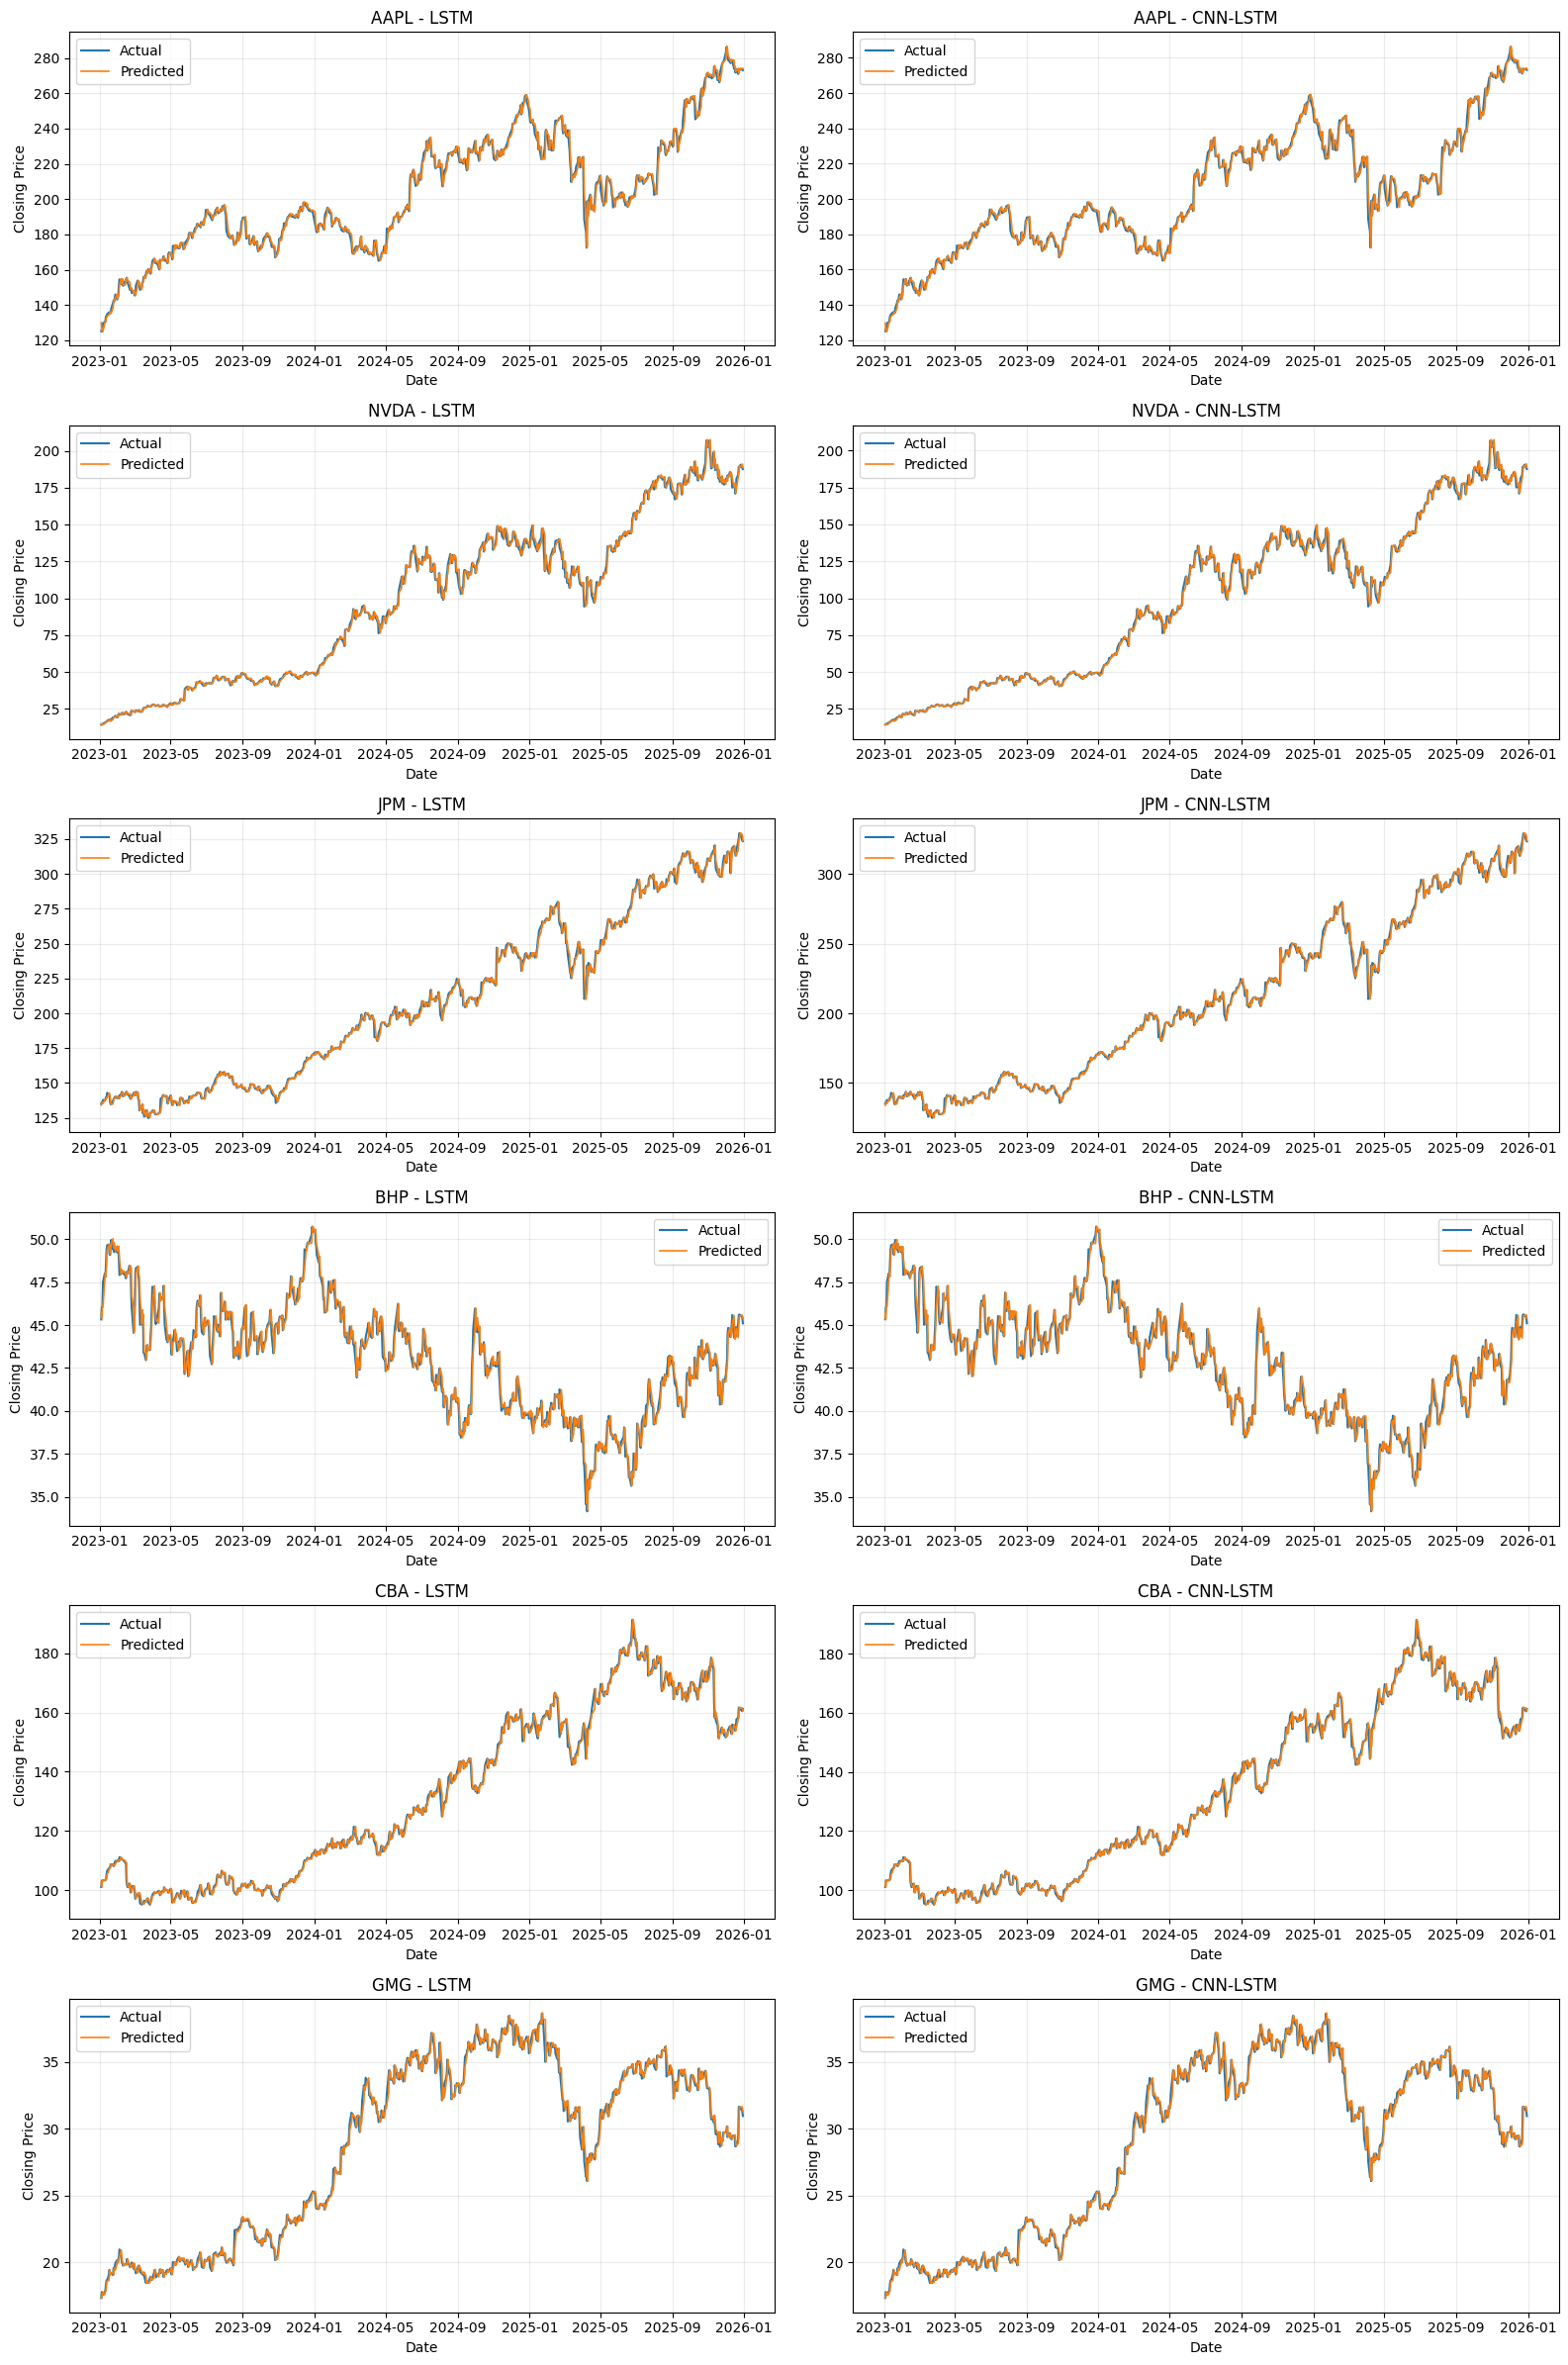

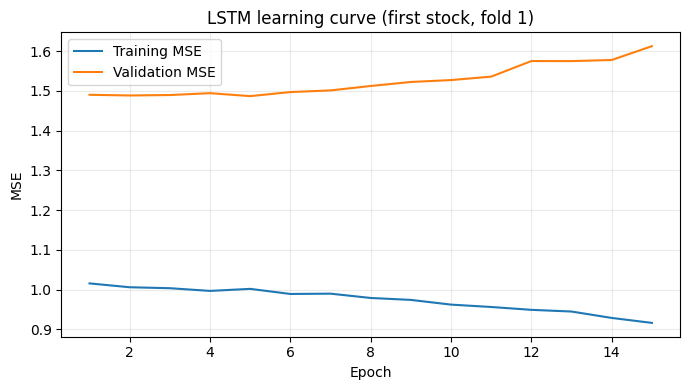

In [36]:
ensemble = predictions_df[predictions_df['forecast_type'] == 'ensemble'].copy()
ensemble['error'] = ensemble['actual_close'] - ensemble['predicted_close']
ensemble['absolute_error'] = ensemble['error'].abs()
ensemble['squared_error'] = ensemble['error']**2
summary_metrics = (ensemble.groupby(['model','stock','condition'])
    .agg(MAE=('absolute_error','mean'),MSE=('squared_error','mean'),
         test_days=('date','count')).reset_index())
summary_metrics['RMSE'] = np.sqrt(summary_metrics['MSE'])
summary_metrics.to_csv(MODEL_DIR/'preliminary_metrics.csv',index=False)
display(summary_metrics)

diagnostics = []
for (kind,name,fold_number,condition), group in ensemble.groupby(['model','stock','fold','condition']):
    predicted_r = group['predicted_log_return'].to_numpy()
    actual_r = np.log(group['actual_close'].to_numpy()/group['previous_close'].to_numpy())
    diagnostics.append({'model':kind,'stock':name,'fold':fold_number,'condition':condition,
        'pred_return_std':float(predicted_r.std()),'actual_return_std':float(actual_r.std()),
        'fraction_pred_up':float(np.mean(predicted_r>0)),
        'mean_seed_return_std':float(group['seed_return_std'].mean())})
diagnostics_df = pd.DataFrame(diagnostics)
diagnostics_df.to_csv(MODEL_DIR/'forecast_diagnostics.csv',index=False)
display(diagnostics_df.head())


# Actual vs Predicted Closing Prices - All 6 Stocks
# LSTM and CNN-LSTM (Clipped Condition)

stocks_to_plot = ["AAPL", "NVDA", "JPM", "BHP", "CBA", "GMG"]
models_to_plot = ["LSTM", "CNN-LSTM"]

fig, axes = plt.subplots(6, 2, figsize=(16, 24))

for i, stock_name in enumerate(stocks_to_plot):
    for j, model_name in enumerate(models_to_plot):

        ax = axes[i, j]

        sample = ensemble[
            (ensemble["stock"] == stock_name) &
            (ensemble["model"] == model_name) &
            (ensemble["condition"] == "clipped")
        ].sort_values("date")

        if sample.empty:
            ax.set_title(f"{stock_name} - {model_name}: No data")
            continue

        ax.plot(
            pd.to_datetime(sample["date"]),
            sample["actual_close"],
            label="Actual",
            linewidth=1.5
        )

        ax.plot(
            pd.to_datetime(sample["date"]),
            sample["predicted_close"],
            label="Predicted",
            linewidth=1.2
        )

        ax.set_title(f"{stock_name} - {model_name}")
        ax.set_xlabel("Date")
        ax.set_ylabel("Closing Price")
        ax.legend()
        ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    MODEL_DIR / "all_stocks_forecasts.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

histories_df = pd.read_csv(
    MODEL_DIR / "learning_curves.csv"
)

sample_hist = histories_df[(histories_df['model']=='LSTM') & (histories_df['stock'] == 'AAPL') &
                            (histories_df['fold']==1) & (histories_df['seed']==0) &
                            (histories_df['condition']=='clipped')]
plt.figure(figsize=(7,4))
plt.plot(sample_hist['epoch'],sample_hist['loss'],label='Training MSE')
plt.plot(sample_hist['epoch'],sample_hist['val_loss'],label='Validation MSE')
plt.xlabel('Epoch');plt.ylabel('MSE');plt.title('LSTM learning curve (first stock, fold 1)')
plt.legend();plt.grid(alpha=.25);plt.tight_layout()
plt.savefig(MODEL_DIR/'example_learning_curve.png',dpi=160)
plt.show()


### 6.5 Evaluation against the naive baseline

Section 6.4 pools all ~751 test days of a stock into a single RMSE. The naive baseline in Section 5.5, however, is reported as the **mean ± std over the 12 folds**. These are different quantities (a pooled RMSE is always at least as large as the day-weighted average of the per-fold RMSEs, and the folds have similar lengths), so the two cannot be compared directly. This section evaluates the models in exactly the same way as the baseline and adds the metrics and tests promised earlier in the notebook:

1. **Per-fold RMSE, MAE and MAPE**, summarised as mean ± std over the 12 folds (same method as Section 5.5). MAPE was listed as an evaluation metric in Sections 4.2 and 5.5.
2. **Diebold–Mariano (DM) test**, planned in Section 4.2 because it does not assume normally distributed errors.
3. **Skill check**: whether the models beat simply predicting the training-mean return, on the validation set and on the test set.

All comparisons use the **ensemble forecasts** (average of the 3 seeds), on the same test days and against the same unclipped closing prices as the naive baseline.

In [37]:
# ---- 6.5.1 Per-fold metrics (same method as the naive baseline in 5.5) ----
ens = ensemble.copy()
ens['ape'] = ens['absolute_error'] / ens['actual_close']        # absolute percentage error, for MAPE

# One row per model / stock / condition / fold: average error over that test quarter
per_fold = (ens.groupby(['model', 'stock', 'condition', 'fold'])
              .agg(MAE=('absolute_error', 'mean'), MSE=('squared_error', 'mean'), MAPE=('ape', 'mean'))
              .reset_index())
per_fold['RMSE'] = np.sqrt(per_fold['MSE'])
per_fold['MAPE (%)'] = 100 * per_fold['MAPE']

# Naive baseline ("tomorrow = today") recomputed on exactly the same test days as the models
naive_days = ens.drop_duplicates(['stock', 'fold', 'date']).copy()
naive_days['naive_abs'] = (naive_days['actual_close'] - naive_days['previous_close']).abs()
naive_days['naive_sq'] = naive_days['naive_abs']**2
naive_days['naive_ape'] = naive_days['naive_abs'] / naive_days['actual_close']
naive_fold = (naive_days.groupby(['stock', 'fold'])
                .agg(MAE=('naive_abs', 'mean'), MSE=('naive_sq', 'mean'), MAPE=('naive_ape', 'mean'))
                .reset_index())
naive_fold['RMSE'] = np.sqrt(naive_fold['MSE'])
naive_fold['MAPE (%)'] = 100 * naive_fold['MAPE']
naive_fold = naive_fold.assign(model='Naive', condition='-')

# Sanity check: should match the naive baseline of Section 5.5
if 'naive' in globals():
    check = naive.rename(columns={'Stock': 'stock', 'Fold': 'fold'}).merge(naive_fold, on=['stock', 'fold'], suffixes=('_5.5', '_6.5'))
    print('Max |naive RMSE difference| vs Section 5.5:', float((check['RMSE_5.5'] - check['RMSE_6.5']).abs().max()))

metric_cols = ['model', 'stock', 'condition', 'fold', 'RMSE', 'MAE', 'MAPE (%)']
fold_metrics = pd.concat([per_fold[metric_cols], naive_fold[metric_cols]], ignore_index=True)
fold_metrics.to_csv(MODEL_DIR / 'per_fold_metrics.csv', index=False)

# Mean ± std over the 12 folds
model_summary = (fold_metrics.groupby(['stock', 'model', 'condition'])[['RMSE', 'MAE', 'MAPE (%)']]
                 .agg(['mean', 'std']).round(3))
display(model_summary)

# Mean fold RMSE relative to naive: negative = model better than naive, positive = worse
mean_rmse = fold_metrics.groupby(['stock', 'model', 'condition'])['RMSE'].mean().reset_index()
naive_rmse = mean_rmse[mean_rmse['model'] == 'Naive'].set_index('stock')['RMSE']
vs_naive = mean_rmse[mean_rmse['model'] != 'Naive'].copy()
vs_naive['RMSE vs naive (%)'] = 100 * (vs_naive['RMSE'] / vs_naive['stock'].map(naive_rmse) - 1)
display(vs_naive.pivot_table(index='stock', columns=['model', 'condition'], values='RMSE vs naive (%)')
                .reindex(stock).round(2))

Max |naive RMSE difference| vs Section 5.5: 8.881784197001252e-16


RMSE           MAE        MAPE (%)       
                           mean    std   mean    std     mean    std
stock model    condition                                            
AAPL  CNN-LSTM clipped    3.068  1.172  2.221  0.675    1.103  0.315
               unclipped  3.075  1.178  2.221  0.676    1.103  0.314
      LSTM     clipped    3.073  1.174  2.225  0.685    1.104  0.316
               unclipped  3.074  1.171  2.229  0.681    1.107  0.315
      Naive    -          3.065  1.163  2.223  0.672    1.103  0.312
BHP   CNN-LSTM clipped    0.584  0.077  0.451  0.057    1.055  0.153
               unclipped  0.584  0.077  0.451  0.057    1.054  0.152
      LSTM     clipped    0.586  0.076  0.452  0.056    1.057  0.149
               unclipped  0.585  0.076  0.451  0.056    1.055  0.150
      Naive    -          0.584  0.076  0.451  0.056    1.054  0.150
CBA   CNN-LSTM clipped    1.634  0.624  1.218  0.442    0.898  0.149
               unclipped  1.639  0.625  1.223  0.443    0.902  0.149
      LSTM     clipped    1.638  0.624  1.226  0.449    0.903  0.154
               unclipped  1.651  0.637  1.235  0.459    0.908  0.161
      Naive    -          1.633  0.621  1.226  0.445    0.903  0.151
GMG   CNN-LSTM clipped    0.464  0.148  0.341  0.100    1.174  0.149
               unclipped  0.465  0.148  0.342  0.100    1.176  0.149
      LSTM     clipped    0.465  0.147  0.343  0.099    1.181  0.143
               unclipped  0.464  0.147  0.342  0.100    1.175  0.149
      Naive    -          0.464  0.146  0.342  0.101    1.176  0.156
JPM   CNN-LSTM clipped    2.959  1.256  2.104  0.820    1.001  0.217
               unclipped  2.970  1.276  2.107  0.825    1.002  0.218
      LSTM     clipped    2.959  1.238  2.107  0.814    1.002  0.211
               unclipped  2.960  1.236  2.112  0.810    1.004  0.208
      Naive    -          2.957  1.246  2.110  0.824    1.002  0.217
NVDA  CNN-LSTM clipped    2.880  1.606  2.168  1.231    2.248  0.569
               unclipped  2.872  1.597  2.159  1.217    2.244  0.558
      LSTM     clipped    2.883  1.613  2.174  1.245    2.251  0.577
               unclipped  2.884  1.612  2.179  1.249    2.256  0.578
      Naive    -          2.882  1.597  2.178  1.234    2.257  0.565

model     CNN-LSTM              LSTM          
condition  clipped unclipped clipped unclipped
stock                                         
AAPL          0.11      0.33    0.28      0.31
NVDA         -0.07     -0.34    0.03      0.06
JPM           0.08      0.43    0.06      0.10
BHP           0.11      0.03    0.30      0.20
CBA           0.06      0.34    0.31      1.11
GMG           0.18      0.30    0.24      0.13

**How to read these tables.** The first table has the same layout as `naive_summary` in Section 5.5, with the naive baseline added as `model = Naive`, so each model can be compared with the baseline row by row. The naive rows are recomputed from the same test days as the models, and the printed line above checks that they match Section 5.5. The second table shows the mean fold RMSE of each model as a percentage difference from the naive RMSE: a **negative** value means the model is more accurate than "tomorrow = today", a **positive** value means it is less accurate. Values within a fraction of a percent mean the model performs essentially like the naive forecast.

#### Diebold–Mariano test

The DM test checks whether the difference in accuracy between two forecasts is statistically significant. For each test day it computes the **loss differential** $d_t = e_{1,t}^2 - e_{2,t}^2$ (squared error of forecast 1 minus squared error of forecast 2) and tests whether its mean is zero:

$$
DM = \frac{\bar d}{\sqrt{\widehat{\operatorname{Var}}(d_t)/n}}
$$

+ **DM < 0 and p < 0.05**: forecast 1 (the model) is significantly more accurate.
+ **DM > 0 and p < 0.05**: forecast 2 (the naive baseline) is significantly more accurate.
+ **p ≥ 0.05**: no significant difference.

Each test uses all test days of a stock across the 12 folds (≈ 750 days). The test is run on two scales:

+ **Price errors**, the scale of RMSE/MAE. Squared price errors grow with the price level, so later folds with higher prices (e.g. NVDA, JPM, CBA) carry more weight.
+ **Return errors** (actual log return minus predicted log return; the naive forecast corresponds to a predicted return of 0). This weights all periods more equally.

The last table compares **LSTM against CNN-LSTM** directly on matched dates (DM < 0 means LSTM is more accurate).

In [38]:
# ---- 6.5.2 Diebold-Mariano test ----
from scipy import stats

def dm_test(e1, e2):
    """Diebold-Mariano test, squared-error loss, 1-step-ahead forecasts. DM < 0 => forecast 1 more accurate."""
    d = e1**2 - e2**2                       # loss differential for each test day
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / n)
    p_value = 2 * stats.t.sf(abs(dm), df=n - 1)
    return dm, p_value

def dm_verdict(dm, p, better='Model better', worse='Naive better'):
    if p >= 0.05:
        return 'No significant difference'
    return better if dm < 0 else worse

ens['actual_return'] = np.log(ens['actual_close'] / ens['previous_close'])
ens['naive_error'] = ens['actual_close'] - ens['previous_close']           # naive: tomorrow = today
ens['return_error'] = ens['actual_return'] - ens['predicted_log_return']   # naive return error = actual return

# Each model vs the naive baseline
dm_rows = []
for (m, s, c), g in ens.groupby(['model', 'stock', 'condition']):
    dm_price, p_price = dm_test(g['error'].values, g['naive_error'].values)
    dm_ret, p_ret = dm_test(g['return_error'].values, g['actual_return'].values)
    dm_rows.append({'model': m, 'stock': s, 'condition': c, 'test days': len(g),
                    'DM (price)': dm_price, 'p-value (price)': p_price,
                    'Result (price)': dm_verdict(dm_price, p_price),
                    'DM (return)': dm_ret, 'p-value (return)': p_ret,
                    'Result (return)': dm_verdict(dm_ret, p_ret)})
dm_table = pd.DataFrame(dm_rows)
dm_table.to_csv(MODEL_DIR / 'dm_test_vs_naive.csv', index=False)
display(dm_table.round(4))

# LSTM vs CNN-LSTM on matched dates
pair_rows = []
for (s, c), g in ens.groupby(['stock', 'condition']):
    errors = g.pivot(index='date', columns='model', values='error').dropna()
    dm, p = dm_test(errors['LSTM'].values, errors['CNN-LSTM'].values)
    pair_rows.append({'stock': s, 'condition': c, 'DM (LSTM vs CNN-LSTM)': dm, 'p-value': p,
                      'Result': dm_verdict(dm, p, better='LSTM better', worse='CNN-LSTM better')})
dm_pair_table = pd.DataFrame(pair_rows)
dm_pair_table.to_csv(MODEL_DIR / 'dm_test_lstm_vs_cnnlstm.csv', index=False)
display(dm_pair_table.round(4))

,model,stock,condition,test days,DM (price),p-value (price),Result (price),DM (return),p-value (return),Result (return)
0,CNN-LSTM,AAPL,clipped,751,0.6751,0.4998,No significant difference,0.5136,0.6077,No significant difference
1,CNN-LSTM,AAPL,unclipped,751,1.2828,0.2000,No significant difference,1.2004,0.2304,No significant difference
2,CNN-LSTM,BHP,clipped,758,0.5910,0.5547,No significant difference,0.4263,0.6700,No significant difference
3,CNN-LSTM,BHP,unclipped,758,0.2122,0.8320,No significant difference,0.1008,0.9198,No significant difference
4,CNN-LSTM,CBA,clipped,758,0.3739,0.7086,No significant difference,0.1470,0.8831,No significant difference
5,CNN-LSTM,CBA,unclipped,758,0.6884,0.4914,No significant difference,0.8757,0.3815,No significant difference
6,CNN-LSTM,GMG,clipped,757,0.7865,0.4318,No significant difference,0.5357,0.5923,No significant difference
7,CNN-LSTM,GMG,unclipped,757,1.2730,0.2034,No significant difference,0.9409,0.3471,No significant difference
8,CNN-LSTM,JPM,clipped,751,0.3265,0.7441,No significant difference,0.4241,0.6716,No significant difference
9,CNN-LSTM,JPM,unclipped,751,0.7974,0.4255,No significant difference,0.8019,0.4229,No significant difference


,stock,condition,DM (LSTM vs CNN-LSTM),p-value,Result
0,AAPL,clipped,0.6589,0.5101,No significant difference
1,AAPL,unclipped,-0.3295,0.7418,No significant difference
2,BHP,clipped,0.7989,0.4246,No significant difference
3,BHP,unclipped,0.8150,0.4153,No significant difference
4,CBA,clipped,0.4739,0.6357,No significant difference
5,CBA,unclipped,1.1761,0.2399,No significant difference
6,GMG,clipped,0.0414,0.9670,No significant difference
7,GMG,unclipped,-1.0633,0.2880,No significant difference
8,JPM,clipped,-0.5152,0.6066,No significant difference
9,JPM,unclipped,-0.9291,0.3531,No significant difference


#### Skill check: do the models beat predicting the average return?

**Validation set.** During training, `fit_once` stores two numbers for every fit (stock × fold × seed × condition), both on the standardised return scale of the validation set:

+ `val_mse`: the model's validation MSE.
+ `zero_val_mse`: the MSE of always predicting 0. A standardised value of 0 corresponds to the **training-mean log return**, the simplest possible forecast.

Their ratio measures how much the network learned beyond that constant forecast:

+ **ratio < 1**: the model is better than predicting the average return.
+ **ratio ≈ 1 or above**: no skill; the model is effectively predicting the average return.

**Caveat.** Early stopping (`restore_best_weights=True`) keeps the epoch with the lowest validation loss, so `val_mse` is measured on the same data that was used to choose the model and is optimistically biased. In the clipped condition the validation targets are also winsorised, while the test targets are not. A validation ratio below 1 is therefore only weak evidence of skill.

**Test set.** The decisive check repeats the comparison out-of-sample: the ensemble's predicted log return against the fold's training-mean log return (`y_mean` from `preprocess_fold`), both scored on the real, unclipped test returns:

$$
\text{ratio} = \frac{\sum_t (r_t - \hat r_t)^2}{\sum_t (r_t - \bar r_{\text{train}})^2}, \qquad R^2_{OOS} = 1 - \text{ratio}
$$

This is the out-of-sample $R^2$ of Campbell & Thompson (2008): a ratio below 1 (positive $R^2_{OOS}$) means the network adds information beyond the historical average return.

In [39]:
# ---- 6.5.3 Skill vs predicting the training-mean return ----
# Validation set (optimistic: early stopping chose the epoch on this data)
skill = training_df.assign(ratio=training_df['val_mse'] / training_df['zero_val_mse'])
skill.to_csv(MODEL_DIR / 'validation_skill.csv', index=False)

# Distribution of the ratio for each model and condition (ratio >= 1 => no skill)
display(skill.groupby(['model', 'condition'])['ratio'].describe().round(3))

# Mean ratio per stock
display(skill.pivot_table(index='stock', columns=['model', 'condition'], values='ratio', aggfunc='mean')
             .reindex(stock).round(3))

# Share of fits that beat the training-mean forecast
display((skill.assign(beats_mean=skill['ratio'] < 1)
              .groupby(['model', 'condition'])['beats_mean'].mean().mul(100).round(1)
              .rename('% of fits with ratio < 1')))

# Test set (out-of-sample): training-mean log return of each fold, as used to standardise the targets
CONDITION_WINSOR = {'clipped': (0.01, 0.99), 'unclipped': None}
train_mean = {(name, k, condition): preprocess_fold(cleaned_data[name], start, end, winsor=winsor)['y_mean']
              for name in stock for k, start, end in folds
              for condition, winsor in CONDITION_WINSOR.items()}

test_skill = ens.copy()
test_skill['actual_return'] = np.log(test_skill['actual_close'] / test_skill['previous_close'])
test_skill['train_mean_return'] = [train_mean[key] for key in zip(test_skill['stock'], test_skill['fold'], test_skill['condition'])]
test_skill['model_sq'] = (test_skill['actual_return'] - test_skill['predicted_log_return'])**2
test_skill['mean_sq'] = (test_skill['actual_return'] - test_skill['train_mean_return'])**2

test_ratio = (test_skill.groupby(['model', 'stock', 'condition'])[['model_sq', 'mean_sq']].sum()
                        .assign(ratio=lambda t: t['model_sq'] / t['mean_sq']).reset_index())
test_ratio['R2_OOS (%)'] = 100 * (1 - test_ratio['ratio'])
test_ratio.to_csv(MODEL_DIR / 'test_skill.csv', index=False)
display(test_ratio.pivot_table(index='stock', columns=['model', 'condition'], values='R2_OOS (%)')
                  .reindex(stock).round(3))

count   mean    std    min    25%    50%    75%    max
model    condition                                                        
CNN-LSTM clipped    216.0  0.994  0.011  0.930  0.990  0.997  1.000  1.047
         unclipped  216.0  0.996  0.011  0.943  0.992  0.998  1.001  1.020
LSTM     clipped    216.0  1.000  0.008  0.967  0.996  1.001  1.004  1.022
         unclipped  216.0  0.999  0.008  0.966  0.996  1.000  1.004  1.023

model     CNN-LSTM              LSTM          
condition  clipped unclipped clipped unclipped
stock                                         
AAPL         0.998     1.000   1.003     1.001
NVDA         0.994     0.993   1.001     0.997
JPM          0.986     0.989   1.001     1.000
BHP          0.995     0.997   0.997     0.997
CBA          0.996     0.996   1.001     1.000
GMG          0.997     0.999   0.997     1.001

model     condition
CNN-LSTM  clipped      78.2
          unclipped    67.6
LSTM      clipped      44.0
          unclipped    48.6
Name: % of fits with ratio < 1, dtype: float64

model     CNN-LSTM              LSTM          
condition  clipped unclipped clipped unclipped
stock                                         
AAPL        -0.666    -1.123  -0.918    -0.969
NVDA        -0.522    -0.139  -0.468    -0.426
JPM         -0.671    -1.575  -0.281    -0.273
BHP         -0.037     0.081  -0.276    -0.175
CBA         -0.218    -1.018  -0.731    -2.331
GMG         -0.496    -0.686  -0.569    -0.363

## 7. ARIMA Model Development

This part builds the ARIMA benchmark for RQ1. It reuses what was established earlier: the cleaned data (Section 2), the 12 walk-forward folds (Section 3), the stationarity and autocorrelation analysis (Sections 4.3–4.4), the choice of $d$ and the outlier conditions (Section 5.4), the naive baseline (Section 5.5) and the Diebold–Mariano test (Section 6.5.2). **Run Sections 1–6 first.**

As stated in Section 5.4, ARIMA works on the log closing price with $d = 1$ and is run under the same two conditions as the deep-learning models: **clipped** (winsorised log returns) and **unclipped** (raw log returns). The model is re-estimated from scratch in each of the 12 folds using only data from before the test quarter, and it is evaluated on the same test days and against the same unclipped closing prices as the naive baseline and the deep-learning models.

**ARIMA-specific design choices**

| Item | Choice | Reason |
|---|---|---|
| Series modelled | Log closing price with $d = 1$ (Section 5.4), fitted as an ARMA($p$, $q$) model on the daily log return | The first difference of the log price *is* the log return, so ARIMA($p$,1,$q$) on the log price and ARMA($p$,$q$) on the log return are the same model. Fitting it on returns allows a drift term (the average daily return), allows the same winsorisation as the deep-learning models, and means ARIMA predicts the same quantity as LSTM and CNN-LSTM (Section 5.4). |
| Choice of $p$, $q$ | AIC over $p, q \in \{0,…,3\}$, with and without drift (32 candidates), in every fold. If several candidates are within 2 AIC points of the best, the one with the fewest parameters is kept. | The PACF and ACF (Section 4.4) point to a small order ($p$ = 0 or 1), so a grid up to 3 covers every plausible specification; higher orders often fail to converge. The 2-point rule is the usual guide for "no real difference in AIC" (Burnham & Anderson, 2002) and stops AIC from choosing larger models that fit noise. Because the grid is wider than the EDA suggests and AIC uses only pre-test data, the full-sample plots of Section 4.4 do not steer the choice towards the test period. |
| Estimation data | All days before the test quarter | The neural networks hold out the last 15% of these days for early stopping (Section 5.2). ARIMA has no such step, so holding them out would only discard the most recent data. This is the same pre-test window used for the ADF test in Section 5.4. |
| Forecasting the test quarter | One day ahead, updated with each real closing price; parameters fixed within the quarter | This gives ARIMA the same information as the neural networks, whose 60-day input window always ends yesterday. |
| Outliers | Two conditions (Section 5.4): **clipped** – returns winsorised at the 1st/99th percentiles learned from the training rows (first 85% of pre-test days), exactly as `preprocess_fold` does for the `Close` feature; **unclipped** – raw returns | ARIMA's maximum-likelihood estimates and AIC order choice are sensitive to outliers (Fox, 1972; Tsay, 1986; Chen & Liu, 1993). Using the same rule as the deep-learning models makes the comparison like-for-like within each condition. Test-day closing prices are never clipped. |
| Evaluation | RMSE, MAE, MAPE per fold, mean ± std over the 12 folds; naive baseline; DM test | Same metrics and method as Sections 5.5 and 6.5, so the results are directly comparable. |
| Residual diagnostics *(added; not in the Assessment 2 plan)* | Ljung-Box test on the residuals and on the squared residuals | The plan chooses $d$, $p$ and $q$ (ADF, ACF/PACF, AIC) but does not check the fitted model. The Ljung-Box test is the standard diagnostic-checking step of the Box–Jenkins method (Box & Jenkins, 1970; Ljung & Box, 1978): it shows whether the chosen model has captured the linear structure, using the test already applied to the returns in Section 4.4. |
| Diagnostic refinements *(added based on Nahian's parts)* | (a) Ljung-Box degrees of freedom reduced by the number of ARMA parameters (`model_df = p + q`); (b) smallest modulus of the AR and MA roots recorded for every fit | (a) The residuals of a fitted ARMA($p$,$q$) model have $p + q$ fewer degrees of freedom; without the correction the test is too lenient and overstates how well the model fits (Ljung & Box, 1978). (b) A root close to 1 means the model is close to non-stationary (AR) or non-invertible (MA); AR and MA roots that are close together also cancel each other, a sign that AIC chose extra parameters that fit noise. Nahian's notebook showed this happening with larger orders such as ARIMA(4,1,4). |

### 7.1 Setup and data for one fold

Section 5.4 found $d = 1$ for all 72 stock-fold cases; the code checks this before going on. For one fold, the data are the closing prices up to the end of the test quarter and their daily log returns (the first difference of the log price). In the clipped condition, the winsorisation limits come from the same training rows as in `preprocess_fold` (`VAL_FRAC` and `WINSOR` from Section 5.2) and are applied to every return the model sees. The real returns and closing prices are kept unchanged for evaluation.

The full walk-forward run (Section 7.5) takes about 20–25 minutes. Its results are saved in `model_outputs/`; set `RUN_ARIMA = False` to reload them instead of re-estimating.

In [40]:
# ---- 7.1 Setup ----
import time
from statsmodels.tsa.arima.model import ARIMA

assert (d_table == 1).all().all(), 'Section 5.4: d = 1 is expected for every stock and fold'
assert 'dm_test' in globals() and 'MODEL_DIR' in globals(), 'Run Section 6 first'

RUN_ARIMA = False   # False = load the saved ARIMA results from model_outputs/ instead of re-estimating (~20-25 min)
CONDITIONS = {'clipped': WINSOR, 'unclipped': None}   # same two conditions as Section 6.3

def arima_fold_data(df, test_start, test_end, winsor=WINSOR):
    # Keep only data up to the end of this fold's test quarter
    close = df.loc[df.index <= test_end, 'Close']
    # d = 1 on the log price (Section 5.4) -> daily log return
    r = np.log(close).diff().dropna()

    # Same train/validation boundary as preprocess_fold (first 85% of pre-test days = training rows)
    pre_test = r.index[r.index < test_start]
    val_start = pre_test[int(len(pre_test) * (1 - VAL_FRAC))]

    # Winsorisation: limits from training rows only, applied to every return the model sees
    if winsor is not None:
        r_train = r[r.index < val_start]
        low, high = r_train.quantile(winsor[0]), r_train.quantile(winsor[1])
        r_input = r.clip(low, high)
    else:
        low, high = None, None
        r_input = r.copy()

    return {'r_real': r,            # real returns (never clipped)
            'r_input': r_input,     # returns the model sees
            'close': close,         # real closing prices
            'winsor_low': low, 'winsor_high': high}

# Added based on Nahian's parts: smallest root modulus of a fitted model (used in Sections 7.4, 7.5 and 7.7)
def min_root(roots):
    return float(np.min(np.abs(roots))) if len(roots) else np.nan   # no AR (or MA) terms -> no roots

### 7.2 Order selection by AIC

Every combination of $p, q \in \{0,…,3\}$ is fitted with and without a constant. With $d = 1$, the constant of the ARMA model on returns is the **drift** of the ARIMA model on log prices (the average daily return). Candidates that fail to converge are skipped. Among the converged candidates, any within 2 AIC points of the lowest are treated as equally good, and the one with the fewest parameters is chosen.

Returns are multiplied by 100 (i.e. expressed in %) before fitting. This does not change the model, but daily log returns of about 0.01 make the likelihood optimiser less stable.

In [41]:
# ---- 7.2 Order selection ----
P_MAX, Q_MAX = 3, 3
TRENDS = ['n', 'c']      # 'n' = no drift, 'c' = drift (constant daily return)
AIC_TOL = 2              # candidates within 2 AIC points of the best are treated as equal
SCALE = 100              # fit on returns in %

def select_order(y):
    # y: pre-test returns (in %). Returns the chosen row, the full AIC grid and the fitted chosen model.
    rows, fitted = [], {}
    for p in range(P_MAX + 1):
        for q in range(Q_MAX + 1):
            for trend in TRENDS:
                try:
                    res = ARIMA(y, order=(p, 0, q), trend=trend).fit()
                    converged = res.mle_retvals.get('converged', True) if res.mle_retvals else True
                    aic = res.aic
                except Exception:
                    res, converged, aic = None, False, np.nan
                rows.append({'p': p, 'q': q, 'trend': trend,
                             'n_params': p + q + (trend == 'c'),
                             'AIC': aic, 'converged': converged})
                fitted[(p, q, trend)] = res
    grid = pd.DataFrame(rows)
    ok = grid[grid['converged']]
    near_best = ok[ok['AIC'] <= ok['AIC'].min() + AIC_TOL]
    chosen = near_best.sort_values(['n_params', 'AIC']).iloc[0]       # simplest among the near-best
    return chosen, grid, fitted[(chosen.p, chosen.q, chosen.trend)]

### 7.3 One-day-ahead forecasts for the test quarter

The chosen model's parameters are kept fixed. The model is then run forward over the test quarter: each day's forecast uses all data up to the previous close, and after the forecast that day's return is added (`res.apply`). In the clipped condition the model sees the winsorised returns, exactly as the neural networks see winsorised inputs. This is the same information the neural networks have.

The predicted return is turned back into a price exactly as for the neural networks (Section 5.1), using the real previous close:

$$\widehat{\text{Close}}_t = \text{Close}_{t-1} \times \exp(\hat r_t)$$

The output uses the same columns as the deep-learning predictions in `model_outputs/predictions.csv`, so all models can be compared directly.

In [42]:
# ---- 7.3 One-day-ahead forecasts ----
def forecast_test(res, fd, test_start):
    # Run the fitted model (same parameters) over the full series up to the end of the test quarter.
    # predict() then gives the one-step-ahead forecast for every day, using only earlier days.
    applied = res.apply(fd['r_input'].values * SCALE)
    pred_r = pd.Series(applied.predict() / SCALE, index=fd['r_input'].index)
    pred_r = pred_r[pred_r.index >= test_start]

    prev_close = fd['close'].shift(1)[pred_r.index].values     # real close of the previous day
    return pd.DataFrame({'date': pred_r.index,
                         'previous_close': prev_close,
                         'actual_close': fd['close'][pred_r.index].values,   # real close (never clipped)
                         'predicted_log_return': pred_r.values,
                         'predicted_close': prev_close * np.exp(pred_r.values)})

### 7.4 Worked example: NVDA, fold 1 (clipped)

Before running all 144 fits (6 stocks × 12 folds × 2 conditions), the steps are shown for one stock and fold in the clipped condition.

**Step 1 – AIC over the grid.** $d = 1$ is taken from Section 5.4. The table shows the 8 best candidates and the one chosen.

In [43]:
name = 'NVDA'
k, start, end = folds[0]
fd = arima_fold_data(cleaned_data[name], start, end, winsor=WINSOR)
y = fd['r_input'][fd['r_input'].index < start].values * SCALE

print(f"{name}, fold {k}: estimation {fd['r_input'].index.min().date()} to {fd['r_input'][fd['r_input'].index < start].index.max().date()} "
      f"({len(y)} days), test {start.date()} to {end.date()}, d = {d_table.loc[name, f'Fold {k}']} (Section 5.4)")
print(f"Winsorisation limits (from training rows): {100 * fd['winsor_low']:.2f}% to {100 * fd['winsor_high']:.2f}%")
chosen, grid, res = select_order(y)

print(f"Converged candidates: {grid['converged'].sum()} of {len(grid)}")
display(grid[grid['converged']].sort_values('AIC').head(8).round(2))
print(f"Chosen: ARIMA({chosen.p},1,{chosen.q}) {'with' if chosen.trend == 'c' else 'without'} drift, AIC = {chosen.AIC:.2f}")
print(res.summary().tables[1])

NVDA, fold 1: estimation 2018-01-03 to 2022-12-30 (1258 days), test 2023-01-01 to 2023-03-31, d = 1 (Section 5.4)
Winsorisation limits (from training rows): -8.02% to 7.49%
Converged candidates: 32 of 32


,p,q,trend,n_params,AIC,converged
20,2,2,n,4,6353.21,True
21,2,2,c,5,6353.70,True
28,3,2,n,5,6354.73,True
29,3,2,c,6,6355.16,True
8,1,0,n,1,6365.75,True
9,1,0,c,2,6366.11,True
2,0,1,n,1,6366.26,True
3,0,1,c,2,6366.61,True


Chosen: ARIMA(2,1,2) without drift, AIC = 6353.21
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.7528      0.038    -45.536      0.000      -1.828      -1.677
ar.L2         -0.9174      0.040    -23.035      0.000      -0.995      -0.839
ma.L1          1.6980      0.050     34.167      0.000       1.601       1.795
ma.L2          0.8574      0.051     16.947      0.000       0.758       0.957
sigma2         9.0638      0.332     27.304      0.000       8.413       9.714


**Step 2 – residual check.** If the model has captured the linear structure, the residuals should show no autocorrelation (Ljung-Box p > 0.05). Volatility clustering (Section 4.4) is expected to remain in the squared residuals, because ARIMA assumes a constant variance.

*Added based on Nahian's parts:* the Ljung-Box test uses `model_df = p + q`, so its degrees of freedom account for the estimated ARMA parameters, and the smallest AR and MA root moduli are printed (values close to 1 indicate a near non-stationary or near non-invertible model; see the design table above).

Ljung-Box p-values, residuals (lag 10, 20; model_df = p + q): [0.712, 0.842]
Ljung-Box p-value, squared residuals (lag 10): 0.0
Smallest |AR root|: 1.044 | smallest |MA root|: 1.08


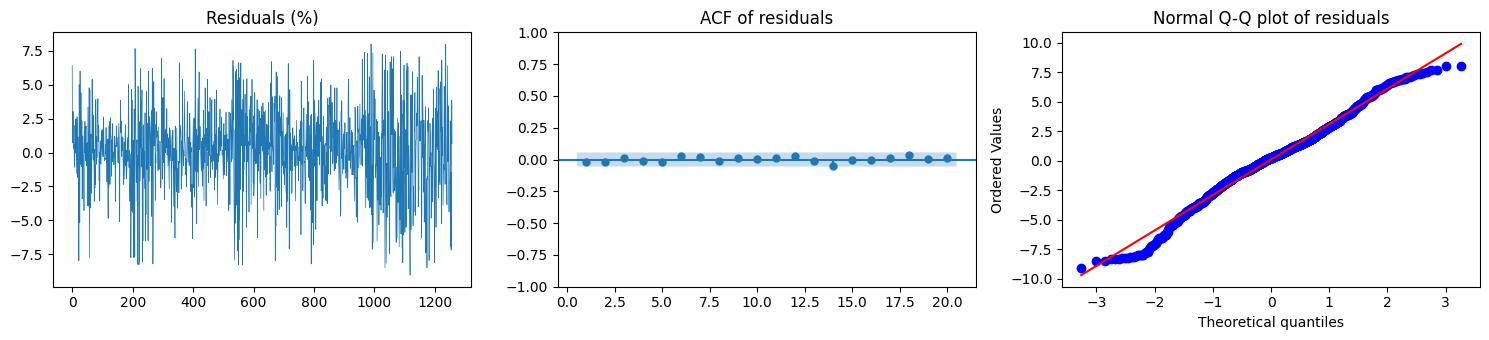

In [44]:
# Added based on Nahian's parts: model_df = p + q and the AR/MA root check (see the design table at the start of Part 7)
resid = res.resid
n_arma = int(chosen.p + chosen.q)
lb = acorr_ljungbox(resid, lags=[10, 20], model_df=n_arma)
lb_sq = acorr_ljungbox(resid ** 2, lags=[10])
print('Ljung-Box p-values, residuals (lag 10, 20; model_df = p + q):', lb['lb_pvalue'].round(3).tolist())
print('Ljung-Box p-value, squared residuals (lag 10):', round(lb_sq['lb_pvalue'].iloc[0], 3))
print('Smallest |AR root|:', round(min_root(res.arroots), 3), '| smallest |MA root|:', round(min_root(res.maroots), 3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(resid, linewidth=0.5); axes[0].set_title('Residuals (%)')
plot_acf(resid, lags=20, zero=False, ax=axes[1], title='ACF of residuals')
stats.probplot(resid, dist='norm', plot=axes[2]); axes[2].set_title('Normal Q-Q plot of residuals')
plt.tight_layout()
plt.show()

**Step 3 – forecast the test quarter one day at a time.**

,RMSE,MAE,MAPE (%)
ARIMA,0.739,0.566,2.699
Naive,0.726,0.557,2.648


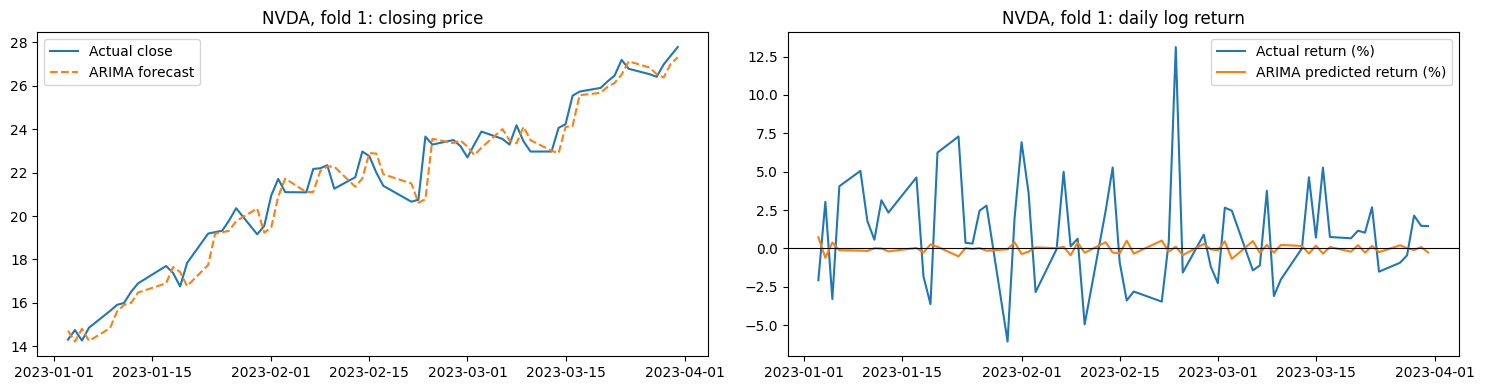

In [45]:
pred = forecast_test(res, fd, start)
example_errors = {'ARIMA': pred['actual_close'] - pred['predicted_close'],
                  'Naive': pred['actual_close'] - pred['previous_close']}
display(pd.DataFrame({m: {'RMSE': np.sqrt((e ** 2).mean()), 'MAE': e.abs().mean(),
                          'MAPE (%)': 100 * (e.abs() / pred['actual_close']).mean()}
                      for m, e in example_errors.items()}).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(pred['date'], pred['actual_close'], label='Actual close')
axes[0].plot(pred['date'], pred['predicted_close'], label='ARIMA forecast', linestyle='--')
axes[0].set_title(f'{name}, fold {k}: closing price')
axes[0].legend()
axes[1].plot(pred['date'], 100 * np.log(pred['actual_close'] / pred['previous_close']), label='Actual return (%)')
axes[1].plot(pred['date'], 100 * pred['predicted_log_return'], label='ARIMA predicted return (%)')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title(f'{name}, fold {k}: daily log return')
axes[1].legend()
plt.tight_layout()
plt.show()

The price chart looks like a close fit, but the return chart shows what is happening: the predicted returns are tiny compared with the actual ones, so the forecast is essentially yesterday's close plus a small adjustment. As explained in Section 5.5, a good-looking price chart is therefore not evidence of skill; the comparison with the naive baseline is.

### 7.5 Walk-forward run: all stocks, folds and conditions

For each condition, stock and fold: build the fold data, select the order by AIC on all pre-test days, record the residual diagnostics (Ljung-Box with `model_df = p + q` and the smallest AR/MA root moduli, *added based on Nahian's parts*), and forecast the test quarter one day at a time. The predictions and the chosen orders are saved to `model_outputs/arima_predictions.csv` and `model_outputs/arima_orders.csv`.

In [46]:
# ---- 7.5 Walk-forward run ----
if RUN_ARIMA:
    order_rows, pred_frames = [], []
    t0 = time.time()
    for condition, winsor in CONDITIONS.items():
        for name in stock:
            for k, start, end in folds:
                fd = arima_fold_data(cleaned_data[name], start, end, winsor=winsor)
                y_train = fd['r_input'][fd['r_input'].index < start]

                chosen, grid, res = select_order(y_train.values * SCALE)
                # Added based on Nahian's parts: Ljung-Box degrees of freedom corrected for the p + q ARMA parameters
                lb = acorr_ljungbox(res.resid, lags=[10, 20], model_df=int(chosen.p + chosen.q))['lb_pvalue']
                lb_sq = acorr_ljungbox(res.resid ** 2, lags=[10])['lb_pvalue'].iloc[0]

                order_rows.append({
                    'condition': condition, 'stock': name, 'fold': k, 'estimation_days': len(y_train),
                    'p': int(chosen.p), 'q': int(chosen.q), 'drift': chosen.trend == 'c',
                    'AIC': chosen.AIC, 'converged_candidates': int(grid['converged'].sum()),
                    'params': dict(zip(res.model.param_names, np.round(res.params, 4))),
                    'LB p (lag 10)': lb.iloc[0], 'LB p (lag 20)': lb.iloc[1],
                    'LB p squared (lag 10)': lb_sq,
                    # Added based on Nahian's parts: closeness to non-stationarity / non-invertibility
                    'min |AR root|': min_root(res.arroots), 'min |MA root|': min_root(res.maroots)})

                pred_frames.append(forecast_test(res, fd, start)
                                   .assign(model='ARIMA', stock=name, fold=k, condition=condition))
            print(f'{condition:>9} | {name} done ({(time.time() - t0) / 60:.1f} min)')

    arima_orders = pd.DataFrame(order_rows)
    arima_pred = pd.concat(pred_frames, ignore_index=True)[
        ['model', 'stock', 'fold', 'condition', 'date', 'previous_close', 'actual_close',
         'predicted_log_return', 'predicted_close']]
    arima_orders.to_csv(MODEL_DIR / 'arima_orders.csv', index=False)
    arima_pred.to_csv(MODEL_DIR / 'arima_predictions.csv', index=False)
    print('Saved ARIMA outputs to:', MODEL_DIR.resolve())
else:   # reuse the saved results instead of re-estimating
    arima_orders = pd.read_csv(MODEL_DIR / 'arima_orders.csv')
    arima_pred = pd.read_csv(MODEL_DIR / 'arima_predictions.csv', parse_dates=['date'])
    print('Loaded saved ARIMA outputs from:', MODEL_DIR.resolve())
print('Fits:', len(arima_orders), '| test-day predictions:', len(arima_pred))

Loaded saved ARIMA outputs from: C:\Users\happe\OneDrive\Desktop\COMP8851\model_outputs
Fits: 144 | test-day predictions: 9052


### 7.6 Selected orders

The chosen specification for each stock and fold in the clipped condition; `c` marks a model with drift. ARIMA(0,1,0) without drift is the random walk, which gives exactly the naive forecast. The second table counts how often each specification is chosen in each condition.

In [47]:
# ---- 7.6 Selected orders ----
arima_orders['spec'] = arima_orders.apply(lambda r: f'ARIMA({r.p},1,{r.q})' + (' + drift' if r.drift else ''), axis=1)
clipped_orders = arima_orders[arima_orders['condition'] == 'clipped']
order_table = (clipped_orders.assign(order=clipped_orders.apply(lambda r: f'({r.p},1,{r.q})' + (' c' if r.drift else ''), axis=1))
               .pivot(index='stock', columns='fold', values='order').reindex(stock))
display(order_table)

# How often each specification is chosen, per condition
spec_counts = arima_orders.groupby(['condition', 'spec']).size().unstack(0).fillna(0).astype(int)
display(spec_counts[list(CONDITIONS)].sort_values('clipped', ascending=False))

rw = (arima_orders.assign(rw=(arima_orders['p'] == 0) & (arima_orders['q'] == 0))
      .groupby('condition')['rw'].mean().mul(100).round(1))
print('Share of stock-folds where ARIMA(0,1,0) (random walk, with or without drift) is chosen (%):')
print(rw.to_string())
print('Minimum number of converged candidates in any fit:', arima_orders['converged_candidates'].min(), 'of 32')

fold,1,2,3,4,5,6,7,8,9,10,11,12
stock,,,,,,,,,,,,
AAPL,"(0,1,1)","(0,1,1)","(0,1,1) c","(0,1,1) c","(0,1,1) c","(0,1,1)","(0,1,0) c","(0,1,0) c","(0,1,0) c","(0,1,1) c","(0,1,0)","(0,1,0) c"
NVDA,"(2,1,2)","(2,1,2) c","(2,1,2)","(2,1,2)","(2,1,2) c","(1,1,0) c","(1,1,0) c","(2,1,2) c","(2,1,2) c","(2,1,2) c","(2,1,2) c","(1,1,0) c"
JPM,"(2,1,3)","(2,1,2)","(2,1,3)","(2,1,3)","(2,1,3)","(2,1,3)","(2,1,3)","(2,1,3)","(2,1,3)","(2,1,3)","(2,1,3)","(2,1,3)"
BHP,"(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(2,1,2)"
CBA,"(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)","(0,1,0)"
GMG,"(0,1,0)","(0,1,0)","(0,1,0)","(2,1,3) c","(0,1,0) c","(2,1,3) c","(0,1,0) c","(2,1,2) c","(2,1,2) c","(2,1,2)","(0,1,0) c","(0,1,0) c"


condition,clipped,unclipped
spec,,
"ARIMA(0,1,0)",27,11
"ARIMA(2,1,3)",11,4
"ARIMA(0,1,0) + drift",8,0
"ARIMA(2,1,2) + drift",8,9
"ARIMA(2,1,2)",6,9
"ARIMA(0,1,1) + drift",4,3
"ARIMA(0,1,1)",3,0
"ARIMA(1,1,0) + drift",3,7
"ARIMA(2,1,3) + drift",2,1


Share of stock-folds where ARIMA(0,1,0) (random walk, with or without drift) is chosen (%):
condition
clipped      48.6
unclipped    15.3
Minimum number of converged candidates in any fit: 25 of 32


### 7.7 Residual diagnostics

The first table counts the folds (out of 12) in which the Ljung-Box test rejects "no autocorrelation" at the 5% level, for the residuals and for the squared residuals (ARCH effect), per condition.

*Added based on Nahian's parts:* the residual test uses `model_df = p + q` (Section 7.5), and the second table checks the roots of the chosen models. Random-walk fits (no AR or MA terms) have no roots and are left out of the root columns. A smallest root modulus below 1.05 is flagged as **near unit root**: such a model is close to non-stationary or non-invertible, and when its AR and MA roots nearly cancel it adds parameters without adding forecasting information. This is necessary because the Ljung-Box test alone cannot reveal over-parameterised models: Nahian's notebook (orders up to 5) found models such as ARIMA(4,1,4) with roots of about 1.03 that pass the Ljung-Box test but forecast no better than naive.

In [48]:
# ---- 7.7 Residual diagnostics ----
display(arima_orders.groupby(['condition', 'stock']).agg(
    **{'Folds with LB p < 0.05 (lag 10)': ('LB p (lag 10)', lambda x: int((x < 0.05).sum())),
       'Folds with LB p < 0.05 (lag 20)': ('LB p (lag 20)', lambda x: int((x < 0.05).sum())),
       'Folds with ARCH effect (squared, lag 10)': ('LB p squared (lag 10)', lambda x: int((x < 0.05).sum()))})
 .unstack('condition').reindex(stock))

# Added based on Nahian's parts: AR / MA root check of the chosen models
NEAR_UNIT = 1.05
roots = arima_orders.assign(min_root=arima_orders[['min |AR root|', 'min |MA root|']].min(axis=1))
display(roots.groupby(['condition', 'stock']).agg(
    **{'Folds with ARMA terms': ('min_root', lambda x: int(x.notna().sum())),
       'Smallest root modulus': ('min_root', 'min'),
       f'Folds with near unit root (< {NEAR_UNIT})': ('min_root', lambda x: int((x < NEAR_UNIT).sum()))})
 .unstack('condition').reindex(stock).round(3))

Folds with LB p < 0.05 (lag 10)           Folds with LB p < 0.05 (lag 20)           Folds with ARCH effect (squared, lag 10)          
condition                         clipped unclipped                         clipped unclipped                                  clipped unclipped
stock                                                                                                                                           
AAPL                                   12         8                              12         8                                       12        12
NVDA                                    2         0                               1         0                                       12        12
JPM                                     0         0                               0        10                                       12        12
BHP                                     0         0                               0         0                                       12        12
CBA                                     0        10                               0        12                                       12        12
GMG                                     1         0                               8         6                                       12        12

Folds with ARMA terms           Smallest root modulus           Folds with near unit root (< 1.05)          
condition               clipped unclipped               clipped unclipped                            clipped unclipped
stock                                                                                                                 
AAPL                          7        12                15.125     1.026                                  0         4
NVDA                         12        12                 1.044     1.046                                  5         7
JPM                          12        12                 1.090     1.107                                  0         0
BHP                           1         1                 1.028     1.004                                  1         1
CBA                           0        12                   NaN     1.001                                  0         7
GMG                           5        12                 1.003     1.014                                  5         3

### 7.8 Forecast accuracy vs the naive baseline

Metrics are computed per fold and summarised as mean ± std over the 12 folds, as in Sections 5.5 and 6.5.1. The naive baseline is recomputed on exactly the same test days, and the printed line checks that it matches Section 5.5. The second table shows ARIMA's mean fold RMSE and MAE as a percentage difference from naive (**negative** = ARIMA more accurate) and the number of folds in which ARIMA has the lower RMSE, for each condition.

*Added based on Nahian's parts:* the third table compares the two conditions fold by fold: the number of folds (out of 12) in which winsorisation lowers ARIMA's RMSE. The mean RMSE can be moved by one or two volatile quarters, so this count shows whether the effect of winsorisation is consistent across the test period or driven by a few folds. Nahian's notebook found that clipping lowered the RMSE in 48 of 72 folds but not for every stock.

In [49]:
# ---- 7.8 Accuracy vs naive ----
a = arima_pred.copy()
a['actual_return'] = np.log(a['actual_close'] / a['previous_close'])
a['error'] = a['actual_close'] - a['predicted_close']
a['naive_error'] = a['actual_close'] - a['previous_close']          # naive: tomorrow = today

def fold_row(model, condition, s, k, err, actual):
    return {'model': model, 'condition': condition, 'stock': s, 'fold': k,
            'RMSE': np.sqrt((err ** 2).mean()), 'MAE': err.abs().mean(),
            'MAPE (%)': 100 * (err.abs() / actual).mean()}

rows = [fold_row('ARIMA', c, s, k, g['error'], g['actual_close'])
        for (c, s, k), g in a.groupby(['condition', 'stock', 'fold'])]
rows += [fold_row('Naive', '-', s, k, g['naive_error'], g['actual_close'])       # naive is the same in both conditions
         for (s, k), g in a.drop_duplicates(['stock', 'fold', 'date']).groupby(['stock', 'fold'])]
arima_fold_metrics = pd.DataFrame(rows)
arima_fold_metrics.to_csv(MODEL_DIR / 'arima_per_fold_metrics.csv', index=False)

# Sanity check: should match the naive baseline of Section 5.5
check = naive.rename(columns={'Stock': 'stock', 'Fold': 'fold'}).merge(
    arima_fold_metrics[arima_fold_metrics['model'] == 'Naive'], on=['stock', 'fold'], suffixes=('_5.5', '_7'))
print('Max |naive RMSE difference| vs Section 5.5:', float((check['RMSE_5.5'] - check['RMSE_7']).abs().max()))

# Mean ± std over the 12 folds
display(arima_fold_metrics.groupby(['stock', 'model', 'condition'])[['RMSE', 'MAE', 'MAPE (%)']]
        .agg(['mean', 'std']).reindex(stock, level=0).round(3))

# ARIMA relative to naive, per condition
naive_f = arima_fold_metrics[arima_fold_metrics['model'] == 'Naive'].set_index(['stock', 'fold'])
rel_rows = []
for (c, s), g in arima_fold_metrics[arima_fold_metrics['model'] == 'ARIMA'].groupby(['condition', 'stock']):
    g = g.set_index('fold')
    nv = naive_f.loc[s].reindex(g.index)
    rel_rows.append({'condition': c, 'stock': s,
                     'RMSE vs naive (%)': 100 * (g['RMSE'].mean() / nv['RMSE'].mean() - 1),
                     'MAE vs naive (%)': 100 * (g['MAE'].mean() / nv['MAE'].mean() - 1),
                     'Folds with ARIMA RMSE < naive': int((g['RMSE'] < nv['RMSE']).sum())})
display(pd.DataFrame(rel_rows).pivot(index='stock', columns='condition').reindex(stock).round(2))

# Added based on Nahian's parts: fold-by-fold effect of winsorisation on ARIMA's RMSE
by_cond = (arima_fold_metrics[arima_fold_metrics['model'] == 'ARIMA']
           .pivot_table(index=['stock', 'fold'], columns='condition', values='RMSE'))
clip_effect = pd.DataFrame({
    'Folds where clipping lowers RMSE': (by_cond['clipped'] < by_cond['unclipped']).groupby('stock').sum(),
    'Folds with equal RMSE': pd.Series(np.isclose(by_cond['clipped'], by_cond['unclipped']), index=by_cond.index)
                              .groupby('stock').sum(),
    'Mean RMSE change, clipped vs unclipped (%)': (100 * (by_cond['clipped'] / by_cond['unclipped'] - 1)).groupby('stock').mean()
}).reindex(stock)
display(clip_effect.round(3))
print('Total folds where clipping lowers ARIMA RMSE:', int(clip_effect['Folds where clipping lowers RMSE'].sum()), 'of', len(by_cond))

Max |naive RMSE difference| vs Section 5.5: 0.0


RMSE           MAE        MAPE (%)       
                        mean    std   mean    std     mean    std
stock model condition                                            
AAPL  ARIMA clipped    3.077  1.165  2.224  0.675    1.105  0.316
            unclipped  3.125  1.193  2.270  0.717    1.127  0.336
      Naive -          3.065  1.163  2.223  0.672    1.103  0.312
NVDA  ARIMA clipped    2.876  1.595  2.165  1.217    2.252  0.559
            unclipped  2.895  1.604  2.192  1.245    2.275  0.583
      Naive -          2.882  1.597  2.178  1.234    2.257  0.565
JPM   ARIMA clipped    2.951  1.239  2.116  0.830    1.004  0.216
            unclipped  2.977  1.250  2.144  0.843    1.016  0.220
      Naive -          2.957  1.246  2.110  0.824    1.002  0.217
BHP   ARIMA clipped    0.585  0.077  0.451  0.056    1.055  0.150
            unclipped  0.586  0.074  0.451  0.057    1.054  0.151
      Naive -          0.584  0.076  0.451  0.056    1.054  0.150
CBA   ARIMA clipped    1.633  0.621  1.226  0.445    0.903  0.151
            unclipped  1.653  0.623  1.248  0.457    0.919  0.156
      Naive -          1.633  0.621  1.226  0.445    0.903  0.151
GMG   ARIMA clipped    0.465  0.149  0.343  0.102    1.177  0.158
            unclipped  0.470  0.145  0.343  0.098    1.183  0.149
      Naive -          0.464  0.146  0.342  0.101    1.176  0.156

RMSE vs naive (%)           MAE vs naive (%)           Folds with ARIMA RMSE < naive          
condition           clipped unclipped          clipped unclipped                       clipped unclipped
stock                                                                                                   
AAPL                   0.39      1.97             0.07      2.13                             4         0
NVDA                  -0.18      0.46            -0.61      0.63                             8         4
JPM                   -0.21      0.68             0.30      1.61                             7         6
BHP                    0.20      0.30             0.10     -0.05                             0         0
CBA                    0.00      1.23             0.00      1.80                             0         1
GMG                    0.27      1.46             0.11      0.29                             4         1

,Folds where clipping lowers RMSE,Folds with equal RMSE,"Mean RMSE change, clipped vs unclipped (%)"
stock,,,
AAPL,12,0,-1.472
NVDA,10,0,-0.603
JPM,10,0,-0.899
BHP,1,10,-0.162
CBA,11,0,-1.330
GMG,9,0,-1.584


Total folds where clipping lowers ARIMA RMSE: 53 of 72


### 7.9 Diebold–Mariano test: ARIMA vs naive

The test is the one defined in Section 6.5.2 (`dm_test`), run per stock and condition on all ~750 test days pooled across the 12 folds, on the price scale and on the return scale. DM < 0 with p < 0.05 means ARIMA is significantly more accurate; DM > 0 with p < 0.05 means the naive forecast is. If ARIMA chose the random walk without drift in every fold, its forecasts are identical to naive and the test is not defined.

In [50]:
# ---- 7.9 Diebold-Mariano test vs naive ----
dm_rows = []
for c in CONDITIONS:
    for s in stock:
        g = a[(a['condition'] == c) & (a['stock'] == s)]
        if np.allclose(g['error'], g['naive_error']):     # random walk in every fold = the naive forecast
            dm_rows.append({'condition': c, 'stock': s, 'test days': len(g),
                            'Result (price)': 'Identical to naive', 'Result (return)': 'Identical to naive'})
            continue
        dm_price, p_price = dm_test(g['error'].values, g['naive_error'].values)
        dm_ret, p_ret = dm_test((g['actual_return'] - g['predicted_log_return']).values, g['actual_return'].values)
        dm_rows.append({'condition': c, 'stock': s, 'test days': len(g),
                        'DM (price)': dm_price, 'p-value (price)': p_price,
                        'Result (price)': dm_verdict(dm_price, p_price, better='ARIMA better'),
                        'DM (return)': dm_ret, 'p-value (return)': p_ret,
                        'Result (return)': dm_verdict(dm_ret, p_ret, better='ARIMA better')})
arima_dm_table = pd.DataFrame(dm_rows)
arima_dm_table.to_csv(MODEL_DIR / 'arima_dm_test_vs_naive.csv', index=False)
display(arima_dm_table.round(4))

,condition,stock,test days,DM (price),p-value (price),Result (price),DM (return),p-value (return),Result (return)
0,clipped,AAPL,751,1.1529,0.2493,No significant difference,1.0406,0.2984,No significant difference
1,clipped,NVDA,751,-0.3799,0.7042,No significant difference,-0.5117,0.6090,No significant difference
2,clipped,JPM,751,-0.5395,0.5897,No significant difference,-1.0033,0.3160,No significant difference
3,clipped,BHP,758,1.4690,0.1423,No significant difference,1.4888,0.1370,No significant difference
4,clipped,CBA,758,NaN,NaN,Identical to naive,NaN,NaN,Identical to naive
5,clipped,GMG,757,1.5226,0.1283,No significant difference,1.1161,0.2647,No significant difference
6,unclipped,AAPL,751,2.4431,0.0148,Naive better,1.9881,0.0472,Naive better
7,unclipped,NVDA,751,0.7952,0.4267,No significant difference,1.0225,0.3069,No significant difference
8,unclipped,JPM,751,0.6338,0.5264,No significant difference,0.3612,0.7180,No significant difference
9,unclipped,BHP,758,1.5614,0.1188,No significant difference,1.6386,0.1017,No significant difference


### 7.10 Forecast behaviour

As for the neural networks (Section 6.4), this checks how large ARIMA's predicted returns are compared with the actual ones and how often it predicts a rise. A model that almost always predicts "up" by a tiny amount is effectively the naive forecast plus a drift. The plot below shows the actual and predicted closing prices over the whole test period (2023–2025), in the same layout as the LSTM / CNN-LSTM plot in Section 6.4. As explained in Section 5.5, the predicted line follows the actual one closely because it is essentially yesterday's close shifted by one day; the plot shows the forecasts, not evidence of skill.

In [51]:
# ---- 7.10 Forecast behaviour ----
(a.assign(up=a['predicted_log_return'] > 0,
          abs_pred=100 * a['predicted_log_return'].abs(),
          abs_act=100 * a['actual_return'].abs())
  .groupby(['condition', 'stock'])
  .agg(**{'% of days predicted up': ('up', lambda x: 100 * x.mean()),
          'Mean |predicted return| (%)': ('abs_pred', 'mean'),
          'Mean |actual return| (%)': ('abs_act', 'mean'),
          'Predicted return std': ('predicted_log_return', 'std'),
          'Actual return std': ('actual_return', 'std')})
  .reindex(pd.MultiIndex.from_product([list(CONDITIONS), stock], names=['condition', 'stock']))
  .round(4))

% of days predicted up  Mean |predicted return| (%)  Mean |actual return| (%)  Predicted return std  Actual return std
condition stock                                                                                                                        
clipped   AAPL                  73.3688                       0.0838                    1.1016                0.0008             0.0161
          NVDA                  70.1731                       0.2405                    2.2602                0.0027             0.0313
          JPM                   50.7324                       0.1265                    1.0014                0.0017             0.0146
          BHP                    4.2216                       0.0129                    1.0542                0.0005             0.0138
          CBA                    0.0000                       0.0000                    0.9030                0.0000             0.0122
          GMG                   64.8613                       0.0683                    1.1752                0.0007             0.0162
unclipped AAPL                  63.6485                       0.1532                    1.1016                0.0021             0.0161
          NVDA                  63.3822                       0.3005                    2.2602                0.0038             0.0313
          JPM                   49.9334                       0.2226                    1.0014                0.0031             0.0146
          BHP                    4.0897                       0.0179                    1.0542                0.0007             0.0138
          CBA                   46.4380                       0.1191                    0.9030                0.0015             0.0122
          GMG                   59.8415                       0.1764                    1.1752                0.0024             0.0162

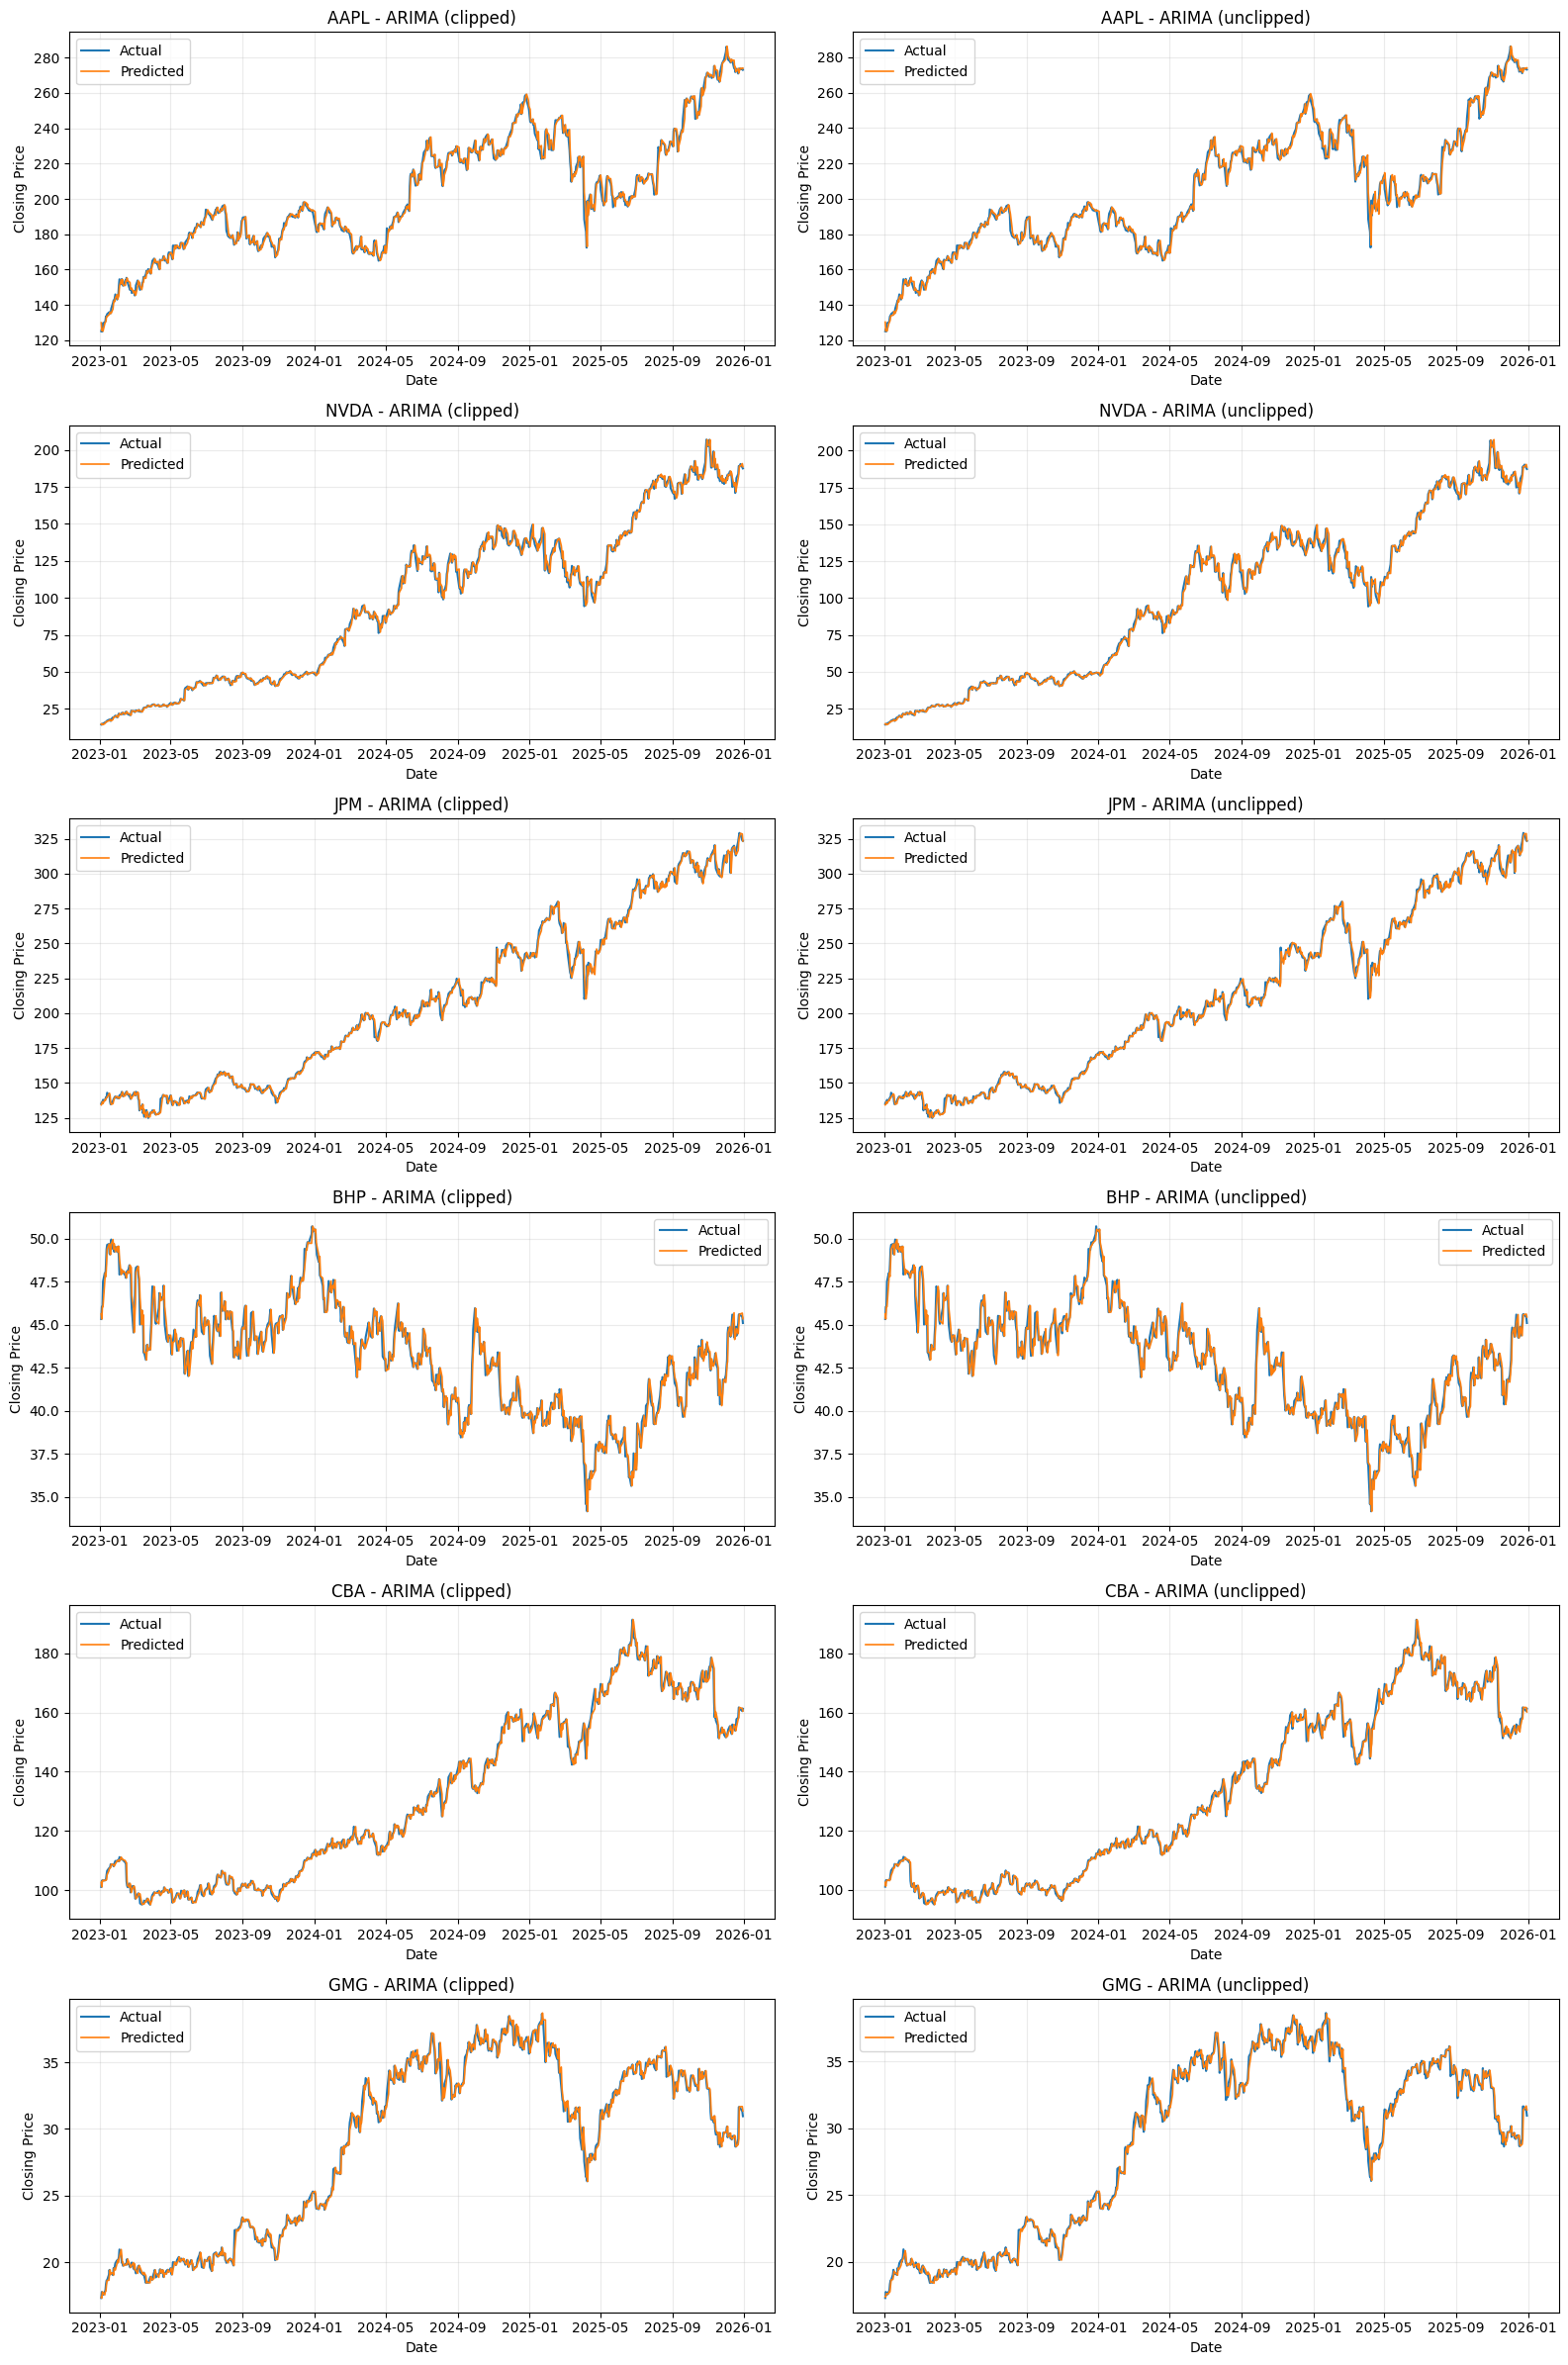

In [52]:
# Actual vs Predicted Closing Prices - All 6 Stocks
# ARIMA (clipped and unclipped), same layout as the LSTM / CNN-LSTM plot in Section 6.4

conditions_to_plot = list(CONDITIONS)

fig, axes = plt.subplots(6, 2, figsize=(16, 24))

for i, stock_name in enumerate(stock):
    for j, condition in enumerate(conditions_to_plot):

        ax = axes[i, j]

        sample = arima_pred[
            (arima_pred["stock"] == stock_name) &
            (arima_pred["condition"] == condition)
        ].sort_values("date")

        ax.plot(
            pd.to_datetime(sample["date"]),
            sample["actual_close"],
            label="Actual",
            linewidth=1.5
        )

        ax.plot(
            pd.to_datetime(sample["date"]),
            sample["predicted_close"],
            label="Predicted",
            linewidth=1.2
        )

        ax.set_title(f"{stock_name} - ARIMA ({condition})")
        ax.set_xlabel("Date")
        ax.set_ylabel("Closing Price")
        ax.legend()
        ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    MODEL_DIR / "arima_all_stocks_forecasts.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### 7.11 Findings

*The statements below refer to the outputs of Sections 7.6–7.10.*

+ **Order selection.** Winsorisation changes the chosen models substantially. In the clipped condition AIC chooses the random walk ARIMA(0,1,0) in 48.6% of the stock-folds (every fold for CBA, 11 of 12 for BHP); in the unclipped condition it does so in only 15.3%, and most folds pick AR and MA terms of order 2–3. Section 4.4 showed that much of the autocorrelation in returns comes from the 2020 COVID period, so these extra terms most likely fit a few extreme days rather than a stable pattern.
+ **Residuals (Ljung-Box with `model_df = p + q`).** With the degrees of freedom corrected for the estimated parameters, autocorrelation remains in a sizeable share of the fits: AAPL in every clipped fold and 8 of 12 unclipped folds, CBA in 10 of 12 unclipped folds (lag 10), JPM in 10 of 12 unclipped folds (lag 20) and GMG in 8 of 12 clipped folds (lag 20). NVDA, BHP and clipped JPM and CBA show little or none. For AAPL clipped, the 2-AIC rule keeps a small model (ARIMA(0,1,1) or the random walk), and the larger models that would remove the autocorrelation (chosen in the unclipped condition) forecast worse, not better (Section 7.8): the remaining autocorrelation is too weak and unstable to be exploited out of sample. The squared residuals show an ARCH effect in every fold for every stock, because ARIMA assumes a constant variance and cannot model the volatility clustering found in Sections 4.4–4.5.
+ **AR/MA roots** *(check added based on Nahian's parts).* Many of the larger models are close to over-parameterised: the smallest root modulus is below 1.05 in 7 of 12 unclipped CBA fits (as low as 1.001), 5 and 7 of 12 NVDA fits (clipped, unclipped), all 5 GMG clipped fits with ARMA terms and 4 of 12 unclipped AAPL fits; only JPM has no such case. Near-unit AR and MA roots largely cancel each other, so these models add parameters without adding forecasting information. This explains why the extra terms in the unclipped condition raise the forecast error.
+ **Accuracy.** Unclipped ARIMA has a higher mean fold RMSE than naive for all six stocks, by 0.30% (BHP) to 1.97% (AAPL). Clipped ARIMA is much closer to naive (within ±0.4%): slightly better for NVDA (−0.18%) and JPM (−0.21%), identical for CBA, slightly worse for AAPL, BHP and GMG. Winsorisation lowers ARIMA's mean RMSE for every stock and lowers the fold RMSE in 53 of 72 folds; for BHP it makes no difference in 10 folds because both conditions choose the random walk. All differences are far smaller than the variation between folds.
+ **Significance.** In the clipped condition the DM test finds no significant difference from naive for any stock (CBA's forecasts are identical to naive). In the unclipped condition the naive forecast is significantly more accurate for AAPL and CBA on both scales, and for GMG on the return scale (p = 0.016). ARIMA is never significantly better than naive.
+ **Forecast behaviour.** The predicted returns are an order of magnitude smaller than the actual returns, so ARIMA's forecasts stay close to yesterday's close, as for the neural networks in Section 6.4.
+ **Robustness check** *(added based on Nahian's parts).* Nahian's separate ARIMA notebook implemented the model independently, on the same folds, test days and winsorisation rule, but with a wider grid ($p, q \le 5$) and with the order chosen on the training rows only and then re-estimated on all pre-test days. It reached the same result: the naive forecast had the lowest RMSE for all six stocks in both conditions, ARIMA had the lower RMSE in only 15 of 72 folds (unclipped), and winsorisation lowered ARIMA's RMSE in 48 of 72 folds (53 of 72 here). The larger orders it often selected, such as ARIMA(4,1,4) or ARIMA(5,1,5), did not forecast better. This supports the smaller grid used here and shows that the conclusion does not depend on the implementation details. (Nahian's RMSEs are computed over all test days pooled, not as a mean over folds, so the absolute values differ from those of Section 7.8.)

**Conclusion.** A linear ARIMA model does not beat the naive random-walk forecast. Without winsorisation its extra parameters add small errors; with winsorisation it mostly reduces to the random walk itself. This is consistent with the weak and unstable autocorrelation found in the EDA. Within each condition, ARIMA's results lie in the same narrow range around naive as those of LSTM and CNN-LSTM (Section 6.5.1), and the outlier treatment changes ARIMA's accuracy more than the choice of model does. The formal comparison between all three models belongs to the evaluation stage.

**References (Part 7 and Section 5.4)**

Box, G. E. P., & Jenkins, G. M. (1970). *Time series analysis: Forecasting and control*. Holden-Day.

Burnham, K. P., & Anderson, D. R. (2002). *Model selection and multimodel inference* (2nd ed.). Springer.

Chen, C., & Liu, L.-M. (1993). Joint estimation of model parameters and outlier effects in time series. *Journal of the American Statistical Association, 88*(421), 284–297.

Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263.

Fox, A. J. (1972). Outliers in time series. *Journal of the Royal Statistical Society: Series B, 34*(3), 350–363.

Ljung, G. M., & Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303.

Tsay, R. S. (1986). Time series model specification in the presence of outliers. *Journal of the American Statistical Association, 81*(393), 132–141.

## 8. Model Comparison (RQ1)

> **RQ1:** Under a consistent walk-forward validation framework, do LSTM and CNN-LSTM provide statistically meaningful improvements over ARIMA in forecasting the next-day closing prices of selected Australian (ASX 200) and U.S. (S&P 500) equities?

This part brings together the forecasts of Sections 6 and 7. **Run Sections 1–7 first.** All three models are evaluated in the same way:

+ the same 12 walk-forward folds and the same test days, against the same unclipped closing prices;
+ LSTM and CNN-LSTM use the ensemble forecast (average of the 3 seeds, Section 6.4);
+ the comparison is made **within each outlier condition** (clipped and unclipped), so that the effect of the model is not mixed with the effect of winsorisation (Section 5.4).

Following the evaluation plan, each model is assessed with **RMSE, MAE, MAPE and the Sharpe ratio**, computed per fold and reported as mean ± std over the 12 folds, and the **Diebold–Mariano test** decides whether a difference in accuracy is statistically significant. The comparisons with the naive baseline (Sections 6.5 and 7.8–7.9) and between LSTM and CNN-LSTM (Section 6.5.2) were made earlier and are not repeated; this part focuses on the question RQ1 asks: **deep learning vs ARIMA**, in the U.S. and the Australian market.

### 8.1 Combine the forecasts

The ensemble forecasts of LSTM and CNN-LSTM and the ARIMA forecasts share the same columns. The code checks that every model is scored on exactly the same test days.

In [53]:
# ---- 8.1 Combine the forecasts of all models ----
assert 'arima_pred' in globals() and 'predictions_df' in globals(), 'Run Sections 6 and 7 first'

MARKET = {'AAPL': 'US', 'NVDA': 'US', 'JPM': 'US', 'BHP': 'AU', 'CBA': 'AU', 'GMG': 'AU'}
MODELS = ['LSTM', 'CNN-LSTM', 'ARIMA']
COLS = ['model', 'stock', 'fold', 'condition', 'date', 'previous_close', 'actual_close',
        'predicted_log_return', 'predicted_close']

nn_pred = predictions_df[predictions_df['forecast_type'] == 'ensemble']     # 3-seed ensemble (Section 6.4)
all_pred = pd.concat([nn_pred[COLS], arima_pred[COLS]], ignore_index=True)
all_pred['date'] = pd.to_datetime(all_pred['date'])
all_pred['actual_return'] = np.log(all_pred['actual_close'] / all_pred['previous_close'])
all_pred['error'] = all_pred['actual_close'] - all_pred['predicted_close']
all_pred['naive_error'] = all_pred['actual_close'] - all_pred['previous_close']    # naive: tomorrow = today

# Every model and condition must be scored on exactly the same test days
test_days = all_pred.groupby(['model', 'condition', 'stock'])['date'].apply(lambda d: tuple(sorted(d)))
assert test_days.groupby(level='stock').nunique().eq(1).all(), 'models do not share the same test days'
display(all_pred.groupby(['model', 'condition']).size().unstack().loc[MODELS])

condition,clipped,unclipped
model,,
LSTM,4526,4526
CNN-LSTM,4526,4526
ARIMA,4526,4526


### 8.2 Forecast accuracy: RMSE, MAE and MAPE

The first table gives mean ± std over the 12 folds for every model and condition, with the naive baseline for reference. The second table shows each model's mean fold RMSE as a percentage difference from naive (negative = more accurate than naive), which puts all stocks on the same scale. The third table compares the deep-learning models **directly with ARIMA**, which is the comparison RQ1 asks about: the mean fold RMSE of LSTM and CNN-LSTM as a percentage difference from ARIMA in the same condition (negative = the deep-learning model is more accurate), and the number of folds (out of 12) in which it has the lower RMSE. The fourth table names the model with the lowest mean fold RMSE for each stock and condition.

*Added based on Nahian's parts:* a bar chart of the RMSE difference from naive per stock, model and condition, and the number of folds (out of 12) in which each model has a lower RMSE than naive. The tables give the exact values, but RQ1 compares three models, six stocks and two conditions at once; the chart makes the pattern (size and sign of every difference, and the effect of winsorisation) visible at a glance. The fold count shows whether a small mean difference comes from consistent gains or from one or two quarters.

In [54]:
# ---- 8.2 RMSE, MAE, MAPE ----
def accuracy_row(err, actual):
    return {'RMSE': np.sqrt((err ** 2).mean()), 'MAE': err.abs().mean(),
            'MAPE (%)': 100 * (err.abs() / actual).mean()}

rows = [{'model': m, 'condition': c, 'stock': s, 'fold': k, **accuracy_row(g['error'], g['actual_close'])}
        for (m, c, s, k), g in all_pred.groupby(['model', 'condition', 'stock', 'fold'])]
rows += [{'model': 'Naive', 'condition': '-', 'stock': s, 'fold': k, **accuracy_row(g['naive_error'], g['actual_close'])}
         for (s, k), g in all_pred.drop_duplicates(['stock', 'fold', 'date']).groupby(['stock', 'fold'])]
cmp_fold = pd.DataFrame(rows)
cmp_fold.to_csv(MODEL_DIR / 'comparison_per_fold_metrics.csv', index=False)

def mean_std(x):
    return f'{x.mean():.3f} ± {x.std():.3f}'

display(cmp_fold.groupby(['stock', 'condition', 'model'])[['RMSE', 'MAE', 'MAPE (%)']]
        .agg(mean_std).reindex(stock, level=0))

# Mean fold RMSE relative to naive (negative = better than naive)
mean_fold = cmp_fold.groupby(['stock', 'model', 'condition'])['RMSE'].mean().reset_index()
naive_rmse = mean_fold[mean_fold['model'] == 'Naive'].set_index('stock')['RMSE']
rel = mean_fold[mean_fold['model'] != 'Naive'].copy()
rel['RMSE vs naive (%)'] = 100 * (rel['RMSE'] / rel['stock'].map(naive_rmse) - 1)
model_columns = pd.MultiIndex.from_product([list(CONDITIONS), MODELS])
display(rel.pivot_table(index='stock', columns=['condition', 'model'], values='RMSE vs naive (%)')
           .reindex(index=stock, columns=model_columns).round(2))

# Deep learning directly vs ARIMA (the comparison of RQ1), within each condition
arima_fold = cmp_fold[cmp_fold['model'] == 'ARIMA'].set_index(['condition', 'stock', 'fold'])['RMSE']
vs_arima = []
for (m, c, s), g in cmp_fold[cmp_fold['model'].isin(['LSTM', 'CNN-LSTM'])].groupby(['model', 'condition', 'stock']):
    ar = arima_fold.loc[(c, s)].reindex(g['fold']).values
    vs_arima.append({'model': m, 'condition': c, 'stock': s,
                     'RMSE vs ARIMA (%)': 100 * (g['RMSE'].mean() / ar.mean() - 1),
                     'Folds with lower RMSE than ARIMA': int((g['RMSE'].values < ar).sum())})
vs_arima = pd.DataFrame(vs_arima)
display(vs_arima.pivot_table(index='stock', columns=['condition', 'model'],
                             values=['RMSE vs ARIMA (%)', 'Folds with lower RMSE than ARIMA'])
                .reindex(stock).round(2))

# Most accurate model (lowest mean fold RMSE) per stock and condition
display(rel.loc[rel.groupby(['condition', 'stock'])['RMSE'].idxmin()]
           .pivot(index='stock', columns='condition', values='model').reindex(stock))

RMSE            MAE       MAPE (%)
stock condition model                                                
AAPL  -         Naive     3.065 ± 1.163  2.223 ± 0.672  1.103 ± 0.312
      clipped   ARIMA     3.077 ± 1.165  2.224 ± 0.675  1.105 ± 0.316
                CNN-LSTM  3.068 ± 1.172  2.221 ± 0.675  1.103 ± 0.315
                LSTM      3.073 ± 1.174  2.225 ± 0.685  1.104 ± 0.316
      unclipped ARIMA     3.125 ± 1.193  2.270 ± 0.717  1.127 ± 0.336
                CNN-LSTM  3.075 ± 1.178  2.221 ± 0.676  1.103 ± 0.314
                LSTM      3.074 ± 1.171  2.229 ± 0.681  1.107 ± 0.315
NVDA  -         Naive     2.882 ± 1.597  2.178 ± 1.234  2.257 ± 0.565
      clipped   ARIMA     2.876 ± 1.595  2.165 ± 1.217  2.252 ± 0.559
                CNN-LSTM  2.880 ± 1.606  2.168 ± 1.231  2.248 ± 0.569
                LSTM      2.883 ± 1.613  2.174 ± 1.245  2.251 ± 0.577
      unclipped ARIMA     2.895 ± 1.604  2.192 ± 1.245  2.275 ± 0.583
                CNN-LSTM  2.872 ± 1.597  2.159 ± 1.217  2.244 ± 0.558
                LSTM      2.884 ± 1.612  2.179 ± 1.249  2.256 ± 0.578
JPM   -         Naive     2.957 ± 1.246  2.110 ± 0.824  1.002 ± 0.217
      clipped   ARIMA     2.951 ± 1.239  2.116 ± 0.830  1.004 ± 0.216
                CNN-LSTM  2.959 ± 1.256  2.104 ± 0.820  1.001 ± 0.217
                LSTM      2.959 ± 1.238  2.107 ± 0.814  1.002 ± 0.211
      unclipped ARIMA     2.977 ± 1.250  2.144 ± 0.843  1.016 ± 0.220
                CNN-LSTM  2.970 ± 1.276  2.107 ± 0.825  1.002 ± 0.218
                LSTM      2.960 ± 1.236  2.112 ± 0.810  1.004 ± 0.208
BHP   -         Naive     0.584 ± 0.076  0.451 ± 0.056  1.054 ± 0.150
      clipped   ARIMA     0.585 ± 0.077  0.451 ± 0.056  1.055 ± 0.150
                CNN-LSTM  0.584 ± 0.077  0.451 ± 0.057  1.055 ± 0.153
                LSTM      0.586 ± 0.076  0.452 ± 0.056  1.057 ± 0.149
      unclipped ARIMA     0.586 ± 0.074  0.451 ± 0.057  1.054 ± 0.151
                CNN-LSTM  0.584 ± 0.077  0.451 ± 0.057  1.054 ± 0.152
                LSTM      0.585 ± 0.076  0.451 ± 0.056  1.055 ± 0.150
CBA   -         Naive     1.633 ± 0.621  1.226 ± 0.445  0.903 ± 0.151
      clipped   ARIMA     1.633 ± 0.621  1.226 ± 0.445  0.903 ± 0.151
                CNN-LSTM  1.634 ± 0.624  1.218 ± 0.442  0.898 ± 0.149
                LSTM      1.638 ± 0.624  1.226 ± 0.449  0.903 ± 0.154
      unclipped ARIMA     1.653 ± 0.623  1.248 ± 0.457  0.919 ± 0.156
                CNN-LSTM  1.639 ± 0.625  1.223 ± 0.443  0.902 ± 0.149
                LSTM      1.651 ± 0.637  1.235 ± 0.459  0.908 ± 0.161
GMG   -         Naive     0.464 ± 0.146  0.342 ± 0.101  1.176 ± 0.156
      clipped   ARIMA     0.465 ± 0.149  0.343 ± 0.102  1.177 ± 0.158
                CNN-LSTM  0.464 ± 0.148  0.341 ± 0.100  1.174 ± 0.149
                LSTM      0.465 ± 0.147  0.343 ± 0.099  1.181 ± 0.143
      unclipped ARIMA     0.470 ± 0.145  0.343 ± 0.098  1.183 ± 0.149
                CNN-LSTM  0.465 ± 0.148  0.342 ± 0.100  1.176 ± 0.149
                LSTM      0.464 ± 0.147  0.342 ± 0.100  1.175 ± 0.149

clipped                unclipped               
         LSTM CNN-LSTM ARIMA      LSTM CNN-LSTM ARIMA
stock                                                
AAPL     0.28     0.11  0.39      0.31     0.33  1.97
NVDA     0.03    -0.07 -0.18      0.06    -0.34  0.46
JPM      0.06     0.08 -0.21      0.10     0.43  0.68
BHP      0.30     0.11  0.20      0.20     0.03  0.30
CBA      0.31     0.06  0.00      1.11     0.34  1.23
GMG      0.24     0.18  0.27      0.13     0.30  1.46

Folds with lower RMSE than ARIMA                      RMSE vs ARIMA (%)                      
condition                          clipped      unclipped                 clipped       unclipped      
model                             CNN-LSTM LSTM  CNN-LSTM  LSTM          CNN-LSTM  LSTM  CNN-LSTM  LSTM
stock                                                                                                  
AAPL                                   7.0  4.0      11.0  11.0             -0.28 -0.11     -1.61 -1.63
NVDA                                   5.0  6.0       8.0   7.0              0.11  0.21     -0.80 -0.40
JPM                                    5.0  4.0       5.0   6.0              0.29  0.27     -0.25 -0.58
BHP                                    4.0  5.0       4.0   4.0             -0.09  0.10     -0.27 -0.11
CBA                                    5.0  5.0       8.0   8.0              0.06  0.31     -0.88 -0.12
GMG                                    7.0  6.0       9.0  10.0             -0.08 -0.03     -1.14 -1.31

condition,clipped,unclipped
stock,,
AAPL,CNN-LSTM,LSTM
NVDA,ARIMA,CNN-LSTM
JPM,ARIMA,LSTM
BHP,CNN-LSTM,CNN-LSTM
CBA,ARIMA,CNN-LSTM
GMG,CNN-LSTM,LSTM


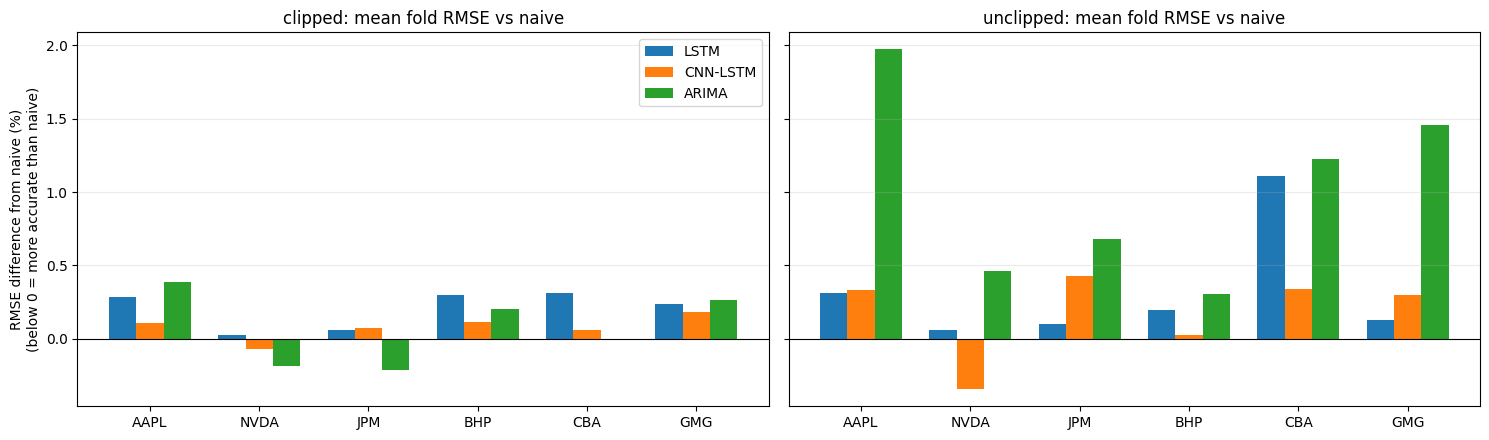

clipped                unclipped               
         LSTM CNN-LSTM ARIMA      LSTM CNN-LSTM ARIMA
stock                                                
AAPL        5        8     4         5        6     0
NVDA        6        6     8         6        8     4
JPM         7        7     7         8        6     6
BHP         4        3     0         4        4     0
CBA         5        5     0         4        4     1
GMG         5        6     4         6        2     1

In [55]:
# Added based on Nahian's parts: RMSE relative to naive, all models and both conditions
rel_plot = rel.pivot_table(index='stock', columns=['condition', 'model'], values='RMSE vs naive (%)').reindex(stock)
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(15, 4.5), sharey=True)
width = 0.25
x = np.arange(len(stock))
for ax, c in zip(axes, CONDITIONS):
    for j, m in enumerate(MODELS):
        ax.bar(x + (j - 1) * width, rel_plot[(c, m)], width, label=m)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(stock)
    ax.set_title(f'{c}: mean fold RMSE vs naive')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('RMSE difference from naive (%)\n(below 0 = more accurate than naive)')
axes[0].legend()
plt.tight_layout()
plt.savefig(MODEL_DIR / 'rmse_vs_naive_all_models.png', dpi=160, bbox_inches='tight')
plt.show()

# Added based on Nahian's parts: number of folds (out of 12) in which each model beats naive
naive_fold = cmp_fold[cmp_fold['model'] == 'Naive'].set_index(['stock', 'fold'])['RMSE']
wins = cmp_fold[cmp_fold['model'] != 'Naive'].copy()
wins['beats naive'] = wins['RMSE'].values < naive_fold.reindex(pd.MultiIndex.from_frame(wins[['stock', 'fold']])).values
display(wins.pivot_table(index='stock', columns=['condition', 'model'], values='beats naive', aggfunc='sum')
            .reindex(index=stock, columns=model_columns).astype(int))

### 8.3 Sharpe ratio and directional accuracy

The Sharpe ratio follows the evaluation plan: a predicted price increase generates a buy signal and a predicted decrease a sell signal (López de Prado, 2018). Concretely, on each test day the strategy is long (+1) if the predicted close is above yesterday's close, short (−1) if it is below, and has no position if the forecast is exactly unchanged. The daily strategy return is position × actual log return, and

$$\text{Sharpe} = \frac{\text{mean(strategy return)}}{\text{std(strategy return)}} \times \sqrt{252}$$

with a risk-free rate of 0, computed per fold. Because the Sharpe ratio depends only on the predicted direction, two further columns explain it: **directional accuracy** (share of traded days on which the predicted direction was right) and **% of days long**. The naive forecast never predicts a direction, so the **buy-and-hold** Sharpe ratio is shown as the reference instead (Section 5.5).

*Caveats:* each fold has only about 62 test days, so fold-level Sharpe ratios are very noisy; transaction costs are ignored; and a model that is long on almost every day has, by construction, nearly the buy-and-hold Sharpe ratio. A Sharpe ratio is therefore only evidence of skill if it is clearly above buy-and-hold. Finally, a model that predicts *exactly* no change on every day of a fold (ARIMA when it selects the random walk without drift, Section 7.6) never trades, so its Sharpe ratio for that fold is undefined. The column **Folds with trades** shows over how many folds each mean ± std is computed; a mean based on only one or two folds should not be compared with the others.

In [56]:
# ---- 8.3 Sharpe ratio and directional accuracy ----
def sharpe(daily_returns):
    return daily_returns.mean() / daily_returns.std() * np.sqrt(252) if daily_returns.std() > 0 else np.nan

def trading_row(g):
    position = np.sign(g['predicted_log_return'])      # +1 buy (predicted rise), -1 sell (predicted fall), 0 no signal
    traded = position != 0
    return {'Sharpe': sharpe(position * g['actual_return']) if traded.any() else np.nan,
            'Direction acc. (%)': (100 * (position[traded] == np.sign(g['actual_return'][traded])).mean()
                                   if traded.any() else np.nan),
            '% days long': 100 * (position > 0).mean()}

rows = [{'model': m, 'condition': c, 'stock': s, 'fold': k, **trading_row(g)}
        for (m, c, s, k), g in all_pred.groupby(['model', 'condition', 'stock', 'fold'])]
rows += [{'model': 'Buy-and-hold', 'condition': '-', 'stock': s, 'fold': k,
          'Sharpe': sharpe(g['actual_return']), 'Direction acc. (%)': np.nan, '% days long': 100.0}
         for (s, k), g in all_pred.drop_duplicates(['stock', 'fold', 'date']).groupby(['stock', 'fold'])]
cmp_trading = pd.DataFrame(rows)
cmp_trading.to_csv(MODEL_DIR / 'comparison_trading_metrics.csv', index=False)

display(cmp_trading.groupby(['stock', 'condition', 'model'])
        .agg(**{'Sharpe': ('Sharpe', mean_std), 'Direction acc. (%)': ('Direction acc. (%)', mean_std),
                '% days long': ('% days long', mean_std),
                'Folds with trades': ('Sharpe', 'count')})     # folds with no trade have an undefined Sharpe ratio
        .reindex(stock, level=0))

# Mean fold Sharpe ratio per stock, next to buy-and-hold
sharpe_table = cmp_trading.pivot_table(index='stock', columns=['condition', 'model'], values='Sharpe', aggfunc='mean')
display(sharpe_table.reindex(index=stock,
                             columns=list(model_columns) + [('-', 'Buy-and-hold')]).round(2))

Sharpe Direction acc. (%)      % days long  Folds with trades
stock condition model                                                                              
AAPL  -         Buy-and-hold   1.258 ± 2.388          nan ± nan  100.000 ± 0.000                 12
      clipped   ARIMA          0.135 ± 1.825     52.013 ± 7.316  73.483 ± 34.482                 11
                CNN-LSTM       1.136 ± 2.375     54.359 ± 7.279  92.919 ± 11.378                 12
                LSTM           0.571 ± 2.328     53.040 ± 7.441  86.254 ± 14.086                 12
      unclipped ARIMA         -0.762 ± 1.222     47.024 ± 4.060  63.697 ± 18.959                 12
                CNN-LSTM       1.005 ± 2.260     53.697 ± 7.876  92.539 ± 12.456                 12
                LSTM           1.054 ± 1.848     53.717 ± 6.494  85.630 ± 11.046                 12
NVDA  -         Buy-and-hold   1.818 ± 1.956          nan ± nan  100.000 ± 0.000                 12
      clipped   ARIMA          1.260 ± 1.054     53.296 ± 5.053  70.107 ± 13.808                 12
                CNN-LSTM       1.403 ± 1.778     53.545 ± 6.007  89.539 ± 20.758                 12
                LSTM           1.661 ± 2.327     54.630 ± 6.034  95.812 ± 11.645                 12
      unclipped ARIMA          0.183 ± 1.758     48.888 ± 7.289  63.281 ± 13.964                 12
                CNN-LSTM       1.150 ± 1.876     52.870 ± 5.500  86.788 ± 20.228                 12
                LSTM           1.408 ± 1.992     53.961 ± 4.957  84.400 ± 16.208                 12
JPM   -         Buy-and-hold   1.509 ± 1.704          nan ± nan  100.000 ± 0.000                 12
      clipped   ARIMA          1.301 ± 3.196     52.827 ± 9.608   50.721 ± 2.902                 12
                CNN-LSTM       0.672 ± 1.702     53.002 ± 6.844  78.808 ± 24.706                 12
                LSTM          -0.217 ± 1.715     50.034 ± 5.582  66.537 ± 22.244                 12
      unclipped ARIMA          1.270 ± 2.740     54.171 ± 7.796   49.931 ± 3.709                 12
                CNN-LSTM       1.300 ± 1.587     54.472 ± 6.241  79.594 ± 27.778                 12
                LSTM           0.287 ± 1.808     50.322 ± 6.862  67.892 ± 23.225                 12
BHP   -         Buy-and-hold  -0.051 ± 1.902          nan ± nan  100.000 ± 0.000                 12
      clipped   ARIMA           -3.150 ± nan       46.032 ± nan   4.233 ± 14.663                  1
                CNN-LSTM      -0.384 ± 1.669     49.246 ± 6.697  71.692 ± 29.321                 12
                LSTM          -0.022 ± 1.773     50.408 ± 7.315  80.901 ± 20.299                 12
      unclipped ARIMA           -0.444 ± nan       58.730 ± nan   4.101 ± 14.205                  1
                CNN-LSTM       0.012 ± 1.869     50.089 ± 6.719  72.846 ± 27.563                 12
                LSTM           0.221 ± 1.493     50.400 ± 5.708  81.599 ± 15.684                 12
CBA   -         Buy-and-hold   0.890 ± 1.719          nan ± nan  100.000 ± 0.000                 12
      clipped   ARIMA              nan ± nan          nan ± nan    0.000 ± 0.000                  0
                CNN-LSTM       0.220 ± 1.949     53.576 ± 7.623  87.709 ± 12.265                 12
                LSTM          -0.035 ± 1.352     52.470 ± 3.961  80.657 ± 12.012                 12
      unclipped ARIMA         -0.271 ± 1.925     47.235 ± 5.349   46.453 ± 5.303                 12
                CNN-LSTM       0.454 ± 1.918     51.947 ± 6.765  80.128 ± 25.054                 12
                LSTM           0.841 ± 2.141     54.600 ± 5.348  74.571 ± 15.640                 12
GMG   -         Buy-and-hold   0.807 ± 1.930          nan ± nan  100.000 ± 0.000                 12
      clipped   ARIMA         -0.283 ± 2.741     50.818 ± 5.785  64.632 ± 41.482                  9
                CNN-LSTM       0.520 ± 2.331     51.712 ± 6.654  90.689 ± 16.841                 12
                LSTM           0.200 ±

condition clipped                unclipped                           -
model        LSTM CNN-LSTM ARIMA      LSTM CNN-LSTM ARIMA Buy-and-hold
stock                                                                 
AAPL         0.57     1.14  0.14      1.05     1.00 -0.76         1.26
NVDA         1.66     1.40  1.26      1.41     1.15  0.18         1.82
JPM         -0.22     0.67  1.30      0.29     1.30  1.27         1.51
BHP         -0.02    -0.38 -3.15      0.22     0.01 -0.44        -0.05
CBA         -0.03     0.22   NaN      0.84     0.45 -0.27         0.89
GMG          0.20     0.52 -0.28      0.43    -0.11 -0.21         0.81

### 8.4 Diebold–Mariano test: deep learning vs ARIMA

The DM test of Section 6.5.2 (`dm_test`) is applied to each pair (LSTM vs ARIMA, CNN-LSTM vs ARIMA) for every stock and condition, on all ~750 test days pooled across the 12 folds, on the price scale and on the return scale. **DM < 0 means the deep-learning model has the smaller errors.**

RQ1 asks for *statistically meaningful* improvements, and 24 tests are run on each scale (2 pairs × 6 stocks × 2 conditions). With so many tests, about one in twenty would be "significant" at the 5% level by chance alone. The p-values are therefore also adjusted with the **Holm** method (Holm, 1979), which keeps the probability of any false positive across all 24 tests at 5%. The result columns are based on the Holm-adjusted p-values; the unadjusted p-values are shown for comparison with Section 6.5.2.

The column **ARIMA = naive** marks the cases where ARIMA chose the random walk without drift in every fold (Sections 7.6 and 7.9). There, "deep learning vs ARIMA" is the same test as "deep learning vs naive" in Section 6.5.2, and should be read that way.

In [57]:
# ---- 8.4 Diebold-Mariano test: LSTM / CNN-LSTM vs ARIMA ----
from statsmodels.stats.multitest import multipletests

PAIRS = [('LSTM', 'ARIMA'), ('CNN-LSTM', 'ARIMA')]
rows = []
for c in CONDITIONS:
    for s in stock:
        g = all_pred[(all_pred['condition'] == c) & (all_pred['stock'] == s)]
        price_err = g.pivot(index='date', columns='model', values='error')
        return_err = (g.assign(return_error=g['actual_return'] - g['predicted_log_return'])
                       .pivot(index='date', columns='model', values='return_error'))
        for m1, m2 in PAIRS:
            dm_p, p_p = dm_test(price_err[m1].values, price_err[m2].values)
            dm_r, p_r = dm_test(return_err[m1].values, return_err[m2].values)
            rows.append({'condition': c, 'market': MARKET[s], 'stock': s, 'comparison': f'{m1} vs {m2}',
                         'ARIMA = naive': bool(np.allclose(price_err['ARIMA'], g[g['model'] == 'ARIMA']
                                                                   .set_index('date')['naive_error'].reindex(price_err.index))),
                         'DM (price)': dm_p, 'p (price)': p_p, 'DM (return)': dm_r, 'p (return)': p_r})
cmp_dm = pd.DataFrame(rows)

for scale in ('price', 'return'):
    cmp_dm[f'Holm p ({scale})'] = multipletests(cmp_dm[f'p ({scale})'], method='holm')[1]
    cmp_dm[f'Result ({scale})'] = [dm_verdict(dm, p, better=f"{pair.split(' vs ')[0]} better", worse='ARIMA better')
                                   for dm, p, pair in zip(cmp_dm[f'DM ({scale})'], cmp_dm[f'Holm p ({scale})'],
                                                          cmp_dm['comparison'])]
cmp_dm.to_csv(MODEL_DIR / 'dm_test_deep_learning_vs_arima.csv', index=False)
display(cmp_dm.round(4))

# Summary: number of stocks per result
for scale in ('price', 'return'):
    print(f'\nResults on the {scale} scale (Holm-adjusted, 5% level):')
    display(cmp_dm.groupby(['condition', 'comparison'])[f'Result ({scale})'].value_counts().unstack(fill_value=0))

,condition,market,stock,comparison,ARIMA = naive,DM (price),p (price),DM (return),p (return),Holm p (price),Result (price),Holm p (return),Result (return)
0,clipped,US,AAPL,LSTM vs ARIMA,False,-0.0447,0.9643,-0.3497,0.7266,1.000,No significant difference,1.0000,No significant difference
1,clipped,US,AAPL,CNN-LSTM vs ARIMA,False,-0.6725,0.5014,-0.7143,0.4753,1.000,No significant difference,1.0000,No significant difference
2,clipped,US,NVDA,LSTM vs ARIMA,False,1.0713,0.2844,0.0992,0.9210,1.000,No significant difference,1.0000,No significant difference
3,clipped,US,NVDA,CNN-LSTM vs ARIMA,False,0.6526,0.5142,0.1865,0.8521,1.000,No significant difference,1.0000,No significant difference
4,clipped,US,JPM,LSTM vs ARIMA,False,0.3918,0.6953,0.8628,0.3885,1.000,No significant difference,1.0000,No significant difference
5,clipped,US,JPM,CNN-LSTM vs ARIMA,False,0.5429,0.5873,0.8844,0.3768,1.000,No significant difference,1.0000,No significant difference
6,clipped,AU,BHP,LSTM vs ARIMA,False,0.2545,0.7992,0.0152,0.9879,1.000,No significant difference,1.0000,No significant difference
7,clipped,AU,BHP,CNN-LSTM vs ARIMA,False,-0.3377,0.7357,-0.4735,0.6360,1.000,No significant difference,1.0000,No significant difference
8,clipped,AU,CBA,LSTM vs ARIMA,True,0.8684,0.3855,0.8962,0.3704,1.000,No significant difference,1.0000,No significant difference
9,clipped,AU,CBA,CNN-LSTM vs ARIMA,True,0.3739,0.7086,0.1470,0.8831,1.000,No significant difference,1.0000,No significant difference



Results on the price scale (Holm-adjusted, 5% level):


Result (price)               No significant difference
condition comparison                                  
clipped   CNN-LSTM vs ARIMA                          6
          LSTM vs ARIMA                              6
unclipped CNN-LSTM vs ARIMA                          6
          LSTM vs ARIMA                              6


Results on the return scale (Holm-adjusted, 5% level):


Result (return)              No significant difference
condition comparison                                  
clipped   CNN-LSTM vs ARIMA                          6
          LSTM vs ARIMA                              6
unclipped CNN-LSTM vs ARIMA                          6
          LSTM vs ARIMA                              6

### 8.5 U.S. vs Australian market

RQ1 covers equities from two markets. The tables below average the results over the three U.S. stocks (AAPL, NVDA, JPM) and the three Australian stocks (BHP, CBA, GMG): the mean RMSE difference from naive, the mean Sharpe ratio next to buy-and-hold, and the number of DM results per market. The RMSE difference is used instead of the RMSE itself because price levels differ widely between stocks. The DM tests are not pooled across stocks, because the returns of stocks in the same market are correlated (Section 4.6) and the test assumes independent comparisons.

*Note on the Sharpe ratio of ARIMA:* the market averages pool all folds in which a Sharpe ratio is defined. ARIMA does not trade in folds where it chose the random walk without drift (Section 8.3), so its Australian averages rest on few folds: 10 of 36 in the clipped condition (BHP 1, CBA 0, GMG 9) and 25 of 36 in the unclipped condition (BHP 1). These two values are not comparable with the others in the table.

In [58]:
# ---- 8.5 U.S. vs Australian market ----
market_order = ['US', 'AU']
display(rel.assign(market=rel['stock'].map(MARKET))
           .pivot_table(index='market', columns=['condition', 'model'], values='RMSE vs naive (%)', aggfunc='mean')
           .reindex(index=market_order, columns=model_columns).round(2))

display(cmp_trading.assign(market=cmp_trading['stock'].map(MARKET))
                   .pivot_table(index='market', columns=['condition', 'model'], values='Sharpe', aggfunc='mean')
                   .reindex(index=market_order, columns=list(model_columns) + [('-', 'Buy-and-hold')]).round(2))

display(cmp_dm.groupby(['market', 'condition', 'comparison'])['Result (price)'].value_counts()
              .unstack(fill_value=0).reindex(market_order, level=0))

clipped                unclipped               
          LSTM CNN-LSTM ARIMA      LSTM CNN-LSTM ARIMA
market                                                
US        0.12     0.04 -0.00      0.16     0.14  1.04
AU        0.28     0.12  0.16      0.48     0.22  1.00

condition clipped                unclipped                           -
model        LSTM CNN-LSTM ARIMA      LSTM CNN-LSTM ARIMA Buy-and-hold
market                                                                
US           0.67     1.07  0.92      0.92     1.15  0.23         1.53
AU           0.05     0.12 -0.57      0.50     0.12 -0.25         0.55

Result (price)                      No significant difference
market condition comparison                                  
US     clipped   CNN-LSTM vs ARIMA                          3
                 LSTM vs ARIMA                              3
       unclipped CNN-LSTM vs ARIMA                          3
                 LSTM vs ARIMA                              3
AU     clipped   CNN-LSTM vs ARIMA                          3
                 LSTM vs ARIMA                              3
       unclipped CNN-LSTM vs ARIMA                          3
                 LSTM vs ARIMA                              3

### 8.6 Answer to RQ1

*The statements below refer to the outputs of Sections 8.1–8.5, with the comparisons against naive from Sections 6.5 and 7.8–7.9.*

**Short answer: no.** Under the same walk-forward framework (same 12 folds, same ~750 test days per stock, same closing prices, same preprocessing within each outlier condition), neither LSTM nor CNN-LSTM provides a statistically meaningful improvement over ARIMA in forecasting next-day closing prices, in either the U.S. or the Australian market.

+ **Statistical significance (Section 8.4).** None of the 48 Diebold–Mariano tests (2 deep-learning models × 6 stocks × 2 conditions × 2 scales) is significant after the Holm adjustment; the smallest adjusted p-value is 0.52. Before adjustment, four tests are below 0.05, all in the unclipped condition and all in favour of deep learning: AAPL on the price scale (LSTM p = 0.036, CNN-LSTM p = 0.033) and GMG on the return scale (LSTM p = 0.022, CNN-LSTM p = 0.030). With 24 tests per scale, a few p-values of this size are expected by chance alone.
+ **Size of the differences (Section 8.2).** In the clipped condition the deep-learning models are within −0.28% to +0.31% of ARIMA's mean fold RMSE, with no consistent sign: each model has the lower RMSE in only 4–7 of the 12 folds. In the unclipped condition both deep-learning models have a lower RMSE than ARIMA for all six stocks (−0.11% to −1.63%), most clearly for AAPL (lower in 11 of 12 folds) and GMG (10 and 9 of 12).
+ **Why deep learning looks better in the unclipped condition.** This gap comes from ARIMA getting worse, not from the deep-learning models getting better. Without winsorisation, ARIMA chooses larger models that fit a few extreme days and often have near-cancelling roots (Section 7.7), which raises its error to 0.30–1.97% above naive. Once returns are winsorised, ARIMA mostly reduces to the random walk and the gap disappears. Outlier treatment therefore matters more than the choice between ARIMA and deep learning.
+ **Comparison with naive.** No model is significantly more accurate than the naive forecast for any stock or condition (Sections 6.5.2 and 7.9). The largest improvement over naive is 0.34% (CNN-LSTM, NVDA, unclipped). All three models produce predicted returns that are much smaller than the actual returns, so their forecasts stay close to yesterday's close (Sections 6.4 and 7.10).
+ **Trading performance (Section 8.3).** No model achieves a Sharpe ratio consistently above buy-and-hold. The deep-learning models are long on 67–96% of days, so their Sharpe ratios largely follow the market. Averaged by market, the best model reaches 1.15 against 1.53 for buy-and-hold in the U.S., and 0.50 against 0.55 in Australia. The fold-to-fold standard deviation of the deep-learning Sharpe ratios (about 1.3–2.4) is larger than any difference between models.
+ **U.S. vs Australian market (Section 8.5).** The pattern is the same in both markets: no DM test is significant in either; in the clipped condition all models are within about 0.3% of naive on average; and in the unclipped condition ARIMA is about 1% worse than naive in both markets, while the deep-learning models stay within about 0.5%. The Australian stocks have lower buy-and-hold Sharpe ratios over 2023–2025, but this reflects the market, not the models.

**Conclusion for RQ1.** The deep-learning models are, at best, as accurate as a well-specified (winsorised) ARIMA model, and all three are statistically indistinguishable from the naive random-walk forecast. This is consistent with the weak and unstable autocorrelation of daily returns found in the EDA (Section 4.4). Two limitations apply: about 750 test days per stock give the DM test limited power to detect differences of a few tenths of a percent, and the comparison covers only six stocks and one forecast horizon (one day). A difference too small to be detected here would also be too small to matter economically once transaction costs are considered.

**References (Part 8)**

López de Prado, M. (2018). *Advances in financial machine learning*. Wiley.

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.

## 9. SHAP Analysis (RQ2)

> **RQ2:** Are the SHAP feature attributions produced by LSTM and CNN-LSTM stable across the six selected companies, and to what extent do attribution patterns vary across companies and market settings?

This part explains the saved LSTM and CNN-LSTM models of Section 6.3 with SHAP (Lundberg & Lee, 2017), following the plan: SHAP values for every input, **beeswarm plots** of the attributions, and the **Spearman rank correlation** of the SHAP feature rankings between stocks. No model is retrained. **Run Sections 1–8 first.**

**Design choices**

| Item | Choice | Reason |
|---|---|---|
| Models explained | LSTM and CNN-LSTM, all 12 folds and all 3 seeds, **clipped** condition (`SHAP_CONDITION`) | RQ2 is about these two models. The clipped condition is the main preprocessing of Section 5.2; set `SHAP_CONDITION = 'unclipped'` to repeat the analysis on the other condition. Using every fold and seed covers the whole test period and lets the stability across folds and seeds be checked (Section 9.7). |
| Attribution method | DeepSHAP (`shap.DeepExplainer`) as planned; if it does not support the saved TensorFlow models, **expected gradients** (`shap.GradientExplainer`) | DeepSHAP combines DeepLIFT with Shapley values (Lundberg & Lee, 2017; Shrikumar et al., 2017). Its TensorFlow implementation does not support every recurrent layer in recent TensorFlow/Keras versions, so Section 9.2 tests it on the saved models first. Expected gradients is the gradient-based SHAP approximation from the same library and the same authors (Erion et al., 2021); it explains the same quantity against the same background data. The method actually used is printed and should be reported. |
| Background data | 100 sequences drawn at random from the fold's **training** rows (same draw for every model and seed of a fold) | SHAP values measure each input's contribution relative to an average prediction over the background. Using training data only keeps the test quarter out of the reference, as in the leakage rules of Section 5.6. |
| Days explained | Every test day of every fold (~750 per stock) | The attributions describe the forecasts that were evaluated in Sections 6 and 8. |
| Output explained | The model output (the scaled next-day log return, Section 5.2) | Converting to prices would not change the ranking of features. |
| Seeds | SHAP values averaged over the 3 seeds | The forecasts are the 3-seed ensemble (Section 6.4). Both SHAP methods are linear in the model output, so the average of the seed attributions is the attribution of the ensemble. |
| From 60 × 5 inputs to 5 features | For each day, the SHAP values of a feature are summed over its 60 lags (its total contribution to that forecast); a feature's **importance** is the mean absolute total contribution over the test days | Each forecast uses a 60-day window of 5 features (300 inputs). RQ2 is about features, so the lags are added up; how the importance is spread over the lags is shown separately (Section 9.5). |
| Stability measures | Spearman rank correlation of the five-feature importance rankings: between stocks (RQ2), between markets, between LSTM and CNN-LSTM, and, as a reliability check, between seeds and between folds | Spearman's ρ compares rankings and ignores the different scales of the stocks (Spearman, 1904). |

**Caveats to keep in mind when reading the results**

+ **Correlated features.** Open, High, Low and Close are strongly correlated (Section 5.1). A model can rely on any of them, so SHAP may divide the credit between them differently from stock to stock. Section 9.6 therefore also compares the share of the four price features taken together with that of volume.
+ **Weak models.** Sections 6.5 and 8 showed that neither model forecasts better than the naive baseline. SHAP explains what the models *use*, not what drives the market. If the attributions are not even stable between seeds of the same model, differences between stocks cannot be interpreted (Section 9.7).
+ **Only five features.** With five items, Spearman's ρ can take only a few values (steps of 0.1), and only a perfect agreement (ρ = 1) is significant at the 5% level (exact p = 0.017; ρ = 0.9 gives p = 0.083). The correlations are therefore read as a description of agreement, not as formal tests.

### 9.1 Setup

`shap` must be installed in the notebook's kernel (`%pip install shap`, then restart the kernel). The full run (Section 9.4) explains 432 saved models (2 models × 6 stocks × 12 folds × 3 seeds) and takes roughly 20–40 minutes on a CPU. Its results are saved in `model_outputs/`; set `RUN_SHAP = False` to reload them instead.

In [59]:
# ---- 9.1 Setup ----
try:
    import shap
except ImportError as e:
    raise ImportError('shap is not installed in this kernel: run  %pip install shap  in a cell, then restart the kernel') from e
from scipy.stats import spearmanr
from itertools import combinations

assert 'predictions_df' in globals() and 'MARKET' in globals(), 'Run Sections 1-8 first'
print('SHAP:', shap.__version__, '| TensorFlow:', tf.__version__)

RUN_SHAP = False             # False = load the saved SHAP results from model_outputs/ instead of recomputing (~1 h or more)
SHAP_CONDITION = 'clipped'   # main condition (Section 5.2); 'unclipped' repeats the analysis on the other condition
SHAP_MODELS = ['LSTM', 'CNN-LSTM']
N_BACKGROUND = 100           # training sequences used as the SHAP background
N_SAMPLES = 100              # samples per explained day (expected gradients only)
FEATURES = ['Open', 'High', 'Low', 'Close', 'Volume']   # column order of transform_features (Section 5.1)
WINDOW = chosen_configs['LSTM']['window']
assert all(c['window'] == WINDOW for c in chosen_configs.values()), 'both models must use the same window'

def model_path(kind, name, k, seed, condition=SHAP_CONDITION):
    return MODEL_DIR / f'{kind}_{name}_fold{k:02d}_{condition}_seed{seed}.keras'

def background_sample(X_train, k):
    rng = np.random.default_rng(k)     # same background for every model and seed of a fold
    idx = rng.choice(len(X_train), size=min(N_BACKGROUND, len(X_train)), replace=False)
    return X_train[np.sort(idx)]

def as_array(sv):
    # Depending on the shap version, the result is a list (one entry per output) or has a trailing output axis
    sv = sv[0] if isinstance(sv, list) else sv
    sv = np.asarray(sv)
    return sv[..., 0] if sv.ndim == 4 else sv

missing = [p for kind in SHAP_MODELS for name in stock for k, _, _ in folds for seed in SEEDS
           if not model_path(kind, name, k, seed).exists()]
assert not missing, f'{len(missing)} saved models are missing, e.g. {missing[0]}'
print('All', len(SHAP_MODELS) * len(stock) * len(folds) * len(SEEDS), 'saved models found for condition:', SHAP_CONDITION)

SHAP: 0.54.1 | TensorFlow: 2.21.0
All 432 saved models found for condition: clipped


### 9.2 Choice of explainer

DeepSHAP is tried first on one saved model of each type. The call checks *additivity*: the SHAP values of a forecast plus the base value must add up to the model's output. If DeepSHAP fails or does not add up for these models, expected gradients is used for the whole analysis (see the design table).

The test runs in a **separate Python process**. When DeepSHAP fails on a TensorFlow model, it leaves its own gradient definitions registered in TensorFlow, and every later SHAP call in the same session then fails as well (including expected gradients). Running the test in its own process keeps this notebook's session clean.

In [60]:
# ---- 9.2 Choice of explainer ----
import subprocess, sys, tempfile, textwrap

probe = get_fold('AAPL', 1, winsor=CONDITIONS[SHAP_CONDITION], window=WINDOW)
probe_dir = Path(tempfile.mkdtemp())
np.savez(probe_dir / 'probe.npz', background=background_sample(probe['X_train'], 1), X=probe['X_test'][:5])

# Small script that tries DeepSHAP on one saved model and reports the result
probe_script = probe_dir / 'deepshap_probe.py'
probe_script.write_text(textwrap.dedent('''
    import os, sys
    os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
    import numpy as np, tensorflow as tf, shap
    data = np.load(sys.argv[2])
    model = tf.keras.models.load_model(sys.argv[1])
    try:
        shap.DeepExplainer(model, data['background']).shap_values(data['X'])   # raises if additivity fails
        print('RESULT OK')
    except Exception as e:
        print('RESULT FAILED', type(e).__name__, (str(e).strip().splitlines() or [''])[-1][:200])
'''))

EXPLAINER = 'DeepExplainer'
for kind in SHAP_MODELS:
    run = subprocess.run([sys.executable, '-I', str(probe_script), str(model_path(kind, 'AAPL', 1, 0).resolve()),
                          str(probe_dir / 'probe.npz')], capture_output=True, text=True,
                         env={**os.environ, 'MPLBACKEND': 'Agg'})   # the notebook's inline plotting backend does not exist outside Jupyter
    result = next((l for l in run.stdout.splitlines() if l.startswith('RESULT')), 'RESULT FAILED (no output) ' + run.stderr[-200:])
    print(f'{kind}: DeepExplainer {result[7:]}')
    if not result.startswith('RESULT OK'):
        EXPLAINER = 'GradientExplainer'
print('\nExplainer used in Part 9:', EXPLAINER if EXPLAINER == 'DeepExplainer' else 'GradientExplainer (expected gradients)')

def make_explainer(model, background):
    return shap.DeepExplainer(model, background) if EXPLAINER == 'DeepExplainer' else shap.GradientExplainer(model, background)

def explain(explainer, X):
    if EXPLAINER == 'DeepExplainer':
        return as_array(explainer.shap_values(X, check_additivity=False))
    return as_array(explainer.shap_values(X, nsamples=N_SAMPLES, rseed=0))

LSTM: DeepExplainer FAILED StagingError     LookupError: gradient registry has no entry for: shap_TensorListStack
CNN-LSTM: DeepExplainer FAILED StagingError     LookupError: gradient registry has no entry for: shap_TensorListStack

Explainer used in Part 9: GradientExplainer (expected gradients)


### 9.3 Worked example: AAPL, fold 1, LSTM (seed 0)

For one model, the SHAP values have the same shape as the input: one value per test day, lag and feature. The check below compares the model's output with the base value plus the sum of the SHAP values (exact for DeepSHAP, approximate for expected gradients). The heat map shows the mean absolute SHAP value of each feature at each lag: lag 1 is the day before the forecast day.


Inputs: (62, 60, 5) -> SHAP values: (62, 60, 5) (test days, lags, features)
Mean |output - (base + sum of SHAP values)|: 0.0088   (std of the outputs: 0.0753, correlation: 0.990)


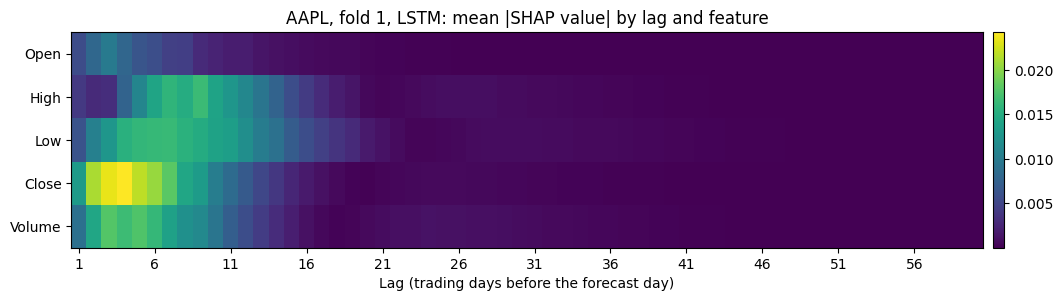

In [61]:
# ---- 9.3 Worked example ----
name_ex, k_ex, kind_ex = 'AAPL', 1, 'LSTM'
fd = get_fold(name_ex, k_ex, winsor=CONDITIONS[SHAP_CONDITION], window=WINDOW)
tf.keras.backend.clear_session()
model = tf.keras.models.load_model(model_path(kind_ex, name_ex, k_ex, 0))
bg = background_sample(fd['X_train'], k_ex)
sv = explain(make_explainer(model, bg), fd['X_test'])
print('Inputs:', fd['X_test'].shape, '-> SHAP values:', sv.shape, '(test days, lags, features)')

pred = model.predict(fd['X_test'], verbose=0).reshape(-1)
base = float(model.predict(bg, verbose=0).mean())          # average output over the background
recon = base + sv.sum(axis=(1, 2))
print(f'Mean |output - (base + sum of SHAP values)|: {np.abs(pred - recon).mean():.4f}   '
      f'(std of the outputs: {pred.std():.4f}, correlation: {np.corrcoef(pred, recon)[0, 1]:.3f})')

lag_imp = np.abs(sv).mean(axis=0)[::-1]                    # row 0 = lag 1 (most recent day)
fig, ax = plt.subplots(figsize=(14, 2.8))
im = ax.imshow(lag_imp.T, aspect='auto', cmap='viridis')
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(FEATURES)
ax.set_xticks(range(0, WINDOW, 5))
ax.set_xticklabels(range(1, WINDOW + 1, 5))
ax.set_xlabel('Lag (trading days before the forecast day)')
ax.set_title(f'{name_ex}, fold {k_ex}, {kind_ex}: mean |SHAP value| by lag and feature')
plt.colorbar(im, ax=ax, pad=0.01)
plt.show()
del model

### 9.4 SHAP values for all stocks, folds and seeds

For each model, stock and fold, the three seed models are explained on all test days and their SHAP values are averaged (the ensemble). Three tables are saved:

+ `shap_daily.csv` – for each test day and feature: the total SHAP value over the 60 lags and the feature's (scaled) value on the most recent day, used for the beeswarm plots;
+ `shap_lags.csv` – for each fold: the mean absolute SHAP value by lag and feature;
+ `shap_seed_importance.csv` – the feature importance of each seed separately, used to check the reliability of the attributions.

In [62]:
# ---- 9.4 Full SHAP run ----
SHAP_FILES = {name: MODEL_DIR / f'shap_{name}_{SHAP_CONDITION}.csv' for name in ('daily', 'lags', 'seed_importance')}

if RUN_SHAP:
    daily_rows, lag_rows, seed_rows = [], [], []
    t0 = time.time()
    for kind in SHAP_MODELS:
        for name in stock:
            for k, _, _ in folds:
                fd = get_fold(name, k, winsor=CONDITIONS[SHAP_CONDITION], window=WINDOW)
                bg = background_sample(fd['X_train'], k)
                seed_sv = []
                for seed in SEEDS:
                    tf.keras.backend.clear_session()
                    model = tf.keras.models.load_model(model_path(kind, name, k, seed))
                    sv = explain(make_explainer(model, bg), fd['X_test'])
                    seed_sv.append(sv)
                    seed_imp = np.abs(sv.sum(axis=1)).mean(axis=0)          # importance of each feature for this seed
                    seed_rows += [{'model': kind, 'stock': name, 'fold': k, 'seed': seed, 'feature': f,
                                   'importance': float(seed_imp[j])} for j, f in enumerate(FEATURES)]
                    del model
                    gc.collect()

                sv = np.mean(seed_sv, axis=0)            # attribution of the 3-seed ensemble
                contrib = sv.sum(axis=1)                 # (days, features): total contribution over the 60 lags
                last = fd['X_test'][:, -1, :]            # scaled feature values on the most recent day
                for d, date in enumerate(fd['test_dates']):
                    daily_rows += [{'model': kind, 'stock': name, 'fold': k, 'date': date, 'feature': f,
                                    'shap': float(contrib[d, j]), 'value': float(last[d, j])} for j, f in enumerate(FEATURES)]
                lag_mean = np.abs(sv).mean(axis=0)       # (lags, features), row 0 = oldest day of the window
                lag_rows += [{'model': kind, 'stock': name, 'fold': k, 'lag': WINDOW - i, 'feature': f,
                              'mean_abs_shap': float(lag_mean[i, j])} for i in range(WINDOW) for j, f in enumerate(FEATURES)]
            print(f'{kind:>8} | {name} done ({(time.time() - t0) / 60:.1f} min)')

    shap_daily, shap_lags, shap_seed = pd.DataFrame(daily_rows), pd.DataFrame(lag_rows), pd.DataFrame(seed_rows)
    for name, table in zip(SHAP_FILES, (shap_daily, shap_lags, shap_seed)):
        table.to_csv(SHAP_FILES[name], index=False)
    print('Saved SHAP outputs to:', MODEL_DIR.resolve())
else:   # reuse the saved results instead of recomputing
    shap_daily = pd.read_csv(SHAP_FILES['daily'], parse_dates=['date'])
    shap_lags = pd.read_csv(SHAP_FILES['lags'])
    shap_seed = pd.read_csv(SHAP_FILES['seed_importance'])
    print('Loaded saved SHAP outputs from:', MODEL_DIR.resolve())

# Every forecast of Section 6 must have been explained
n_test = predictions_df[(predictions_df['forecast_type'] == 'ensemble') & (predictions_df['condition'] == SHAP_CONDITION)
                        & predictions_df['model'].isin(SHAP_MODELS)].shape[0]
assert len(shap_daily) == n_test * len(FEATURES), 'SHAP values do not cover every test day'
print('Explained test days:', n_test, '| condition:', SHAP_CONDITION)

Loaded saved SHAP outputs from: C:\Users\happe\OneDrive\Desktop\COMP8851\model_outputs
Explained test days: 9052 | condition: clipped


### 9.5 Feature importance and beeswarm plots

The first table gives each feature's share of the total importance (mean absolute SHAP value, %) for every model and stock; the second gives the resulting rank (1 = most important). The beeswarm plots show one dot per test day: its position is the feature's total contribution to that day's forecast (right = pushes the predicted return up), and its colour is the feature's value on the day before the forecast (red = high, blue = low). The features are kept in the same order in every panel so the stocks can be compared.

The lag profile shows how the importance is spread over the 60-day window, summed over the features: a model that mostly uses the last few days has a profile concentrated at lag 1.

Share of total importance (%)


feature         Open  High   Low  Close  Volume
model    stock                                 
LSTM     AAPL   11.0  23.0  33.4   24.4     8.1
         NVDA   20.0  11.5  29.9   24.0    14.7
         JPM     8.3   7.3  22.5   43.9    18.1
         BHP    31.6  23.8   9.5   26.0     9.1
         CBA    14.5  15.5  31.1   25.4    13.5
         GMG    18.1  16.4  24.9   31.5     9.2
CNN-LSTM AAPL   20.2  18.3  27.8   19.2    14.5
         NVDA   15.7  18.1  23.0   26.8    16.4
         JPM    15.3  17.9  20.9   27.9    18.0
         BHP    33.0  12.0  14.8   21.3    18.9
         CBA    16.4  17.1  28.8   16.1    21.6
         GMG    18.2  19.6  21.2   26.3    14.7

Rank (1 = most important)


feature         Open  High  Low  Close  Volume
model    stock                                
LSTM     AAPL      4     3    1      2       5
         NVDA      3     5    1      2       4
         JPM       4     5    2      1       3
         BHP       1     3    4      2       5
         CBA       4     3    1      2       5
         GMG       3     4    2      1       5
CNN-LSTM AAPL      2     4    1      3       5
         NVDA      5     3    2      1       4
         JPM       5     4    2      1       3
         BHP       1     5    4      2       3
         CBA       4     3    1      5       2
         GMG       4     3    2      1       5

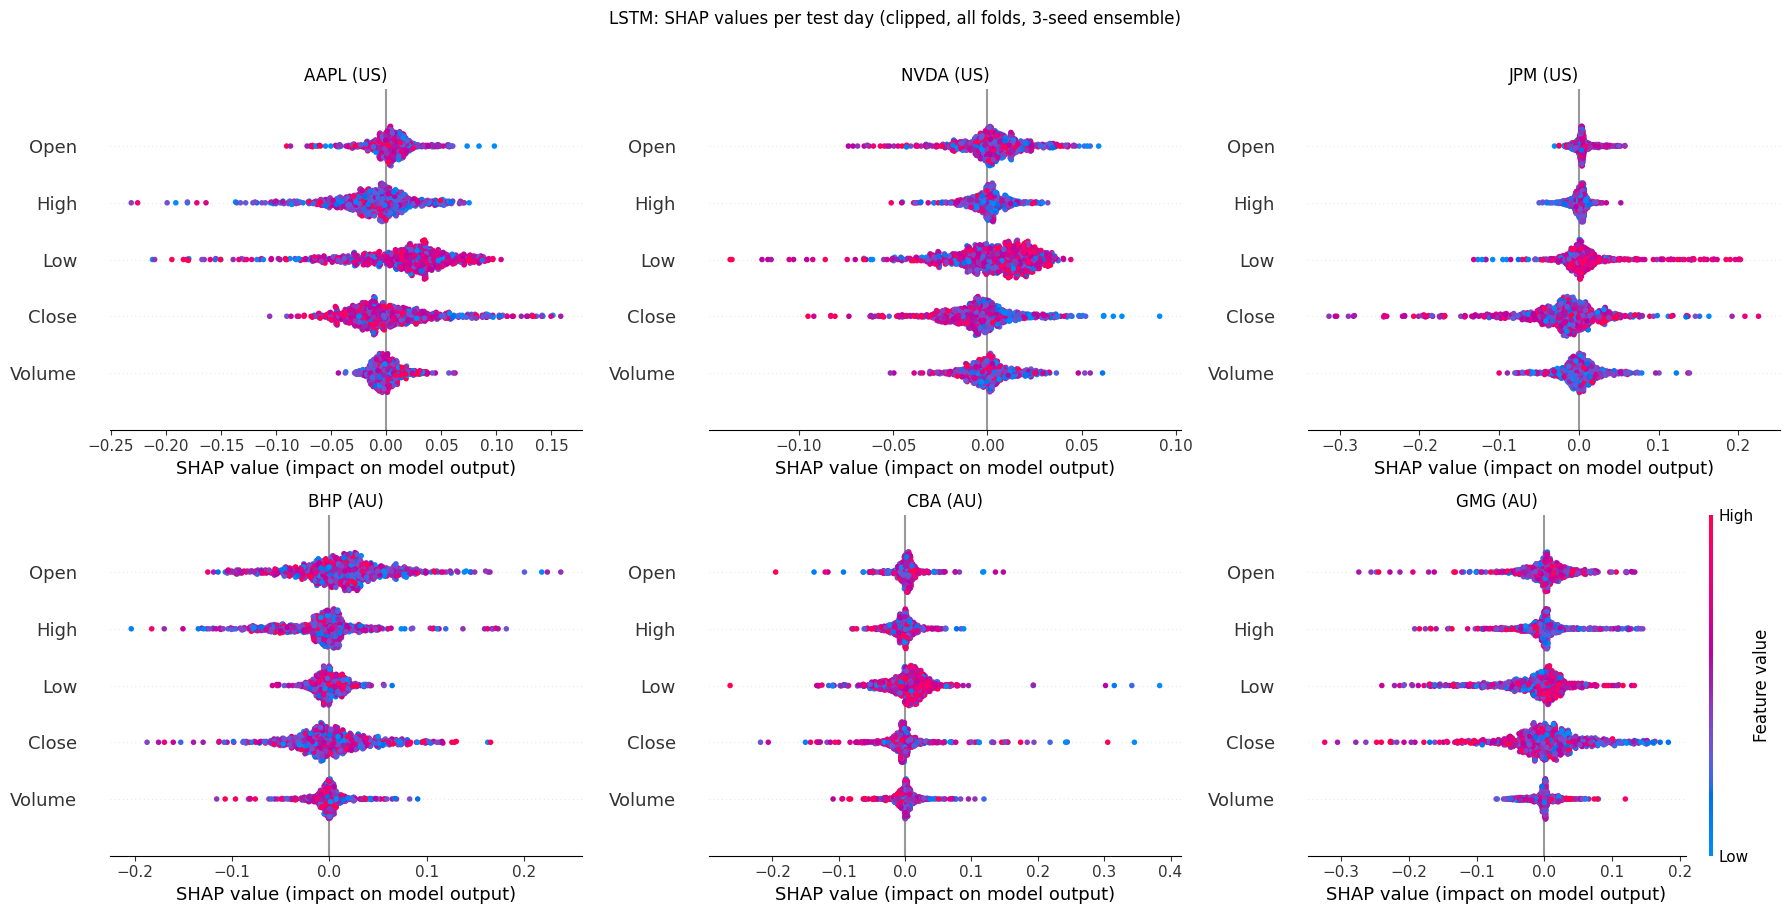

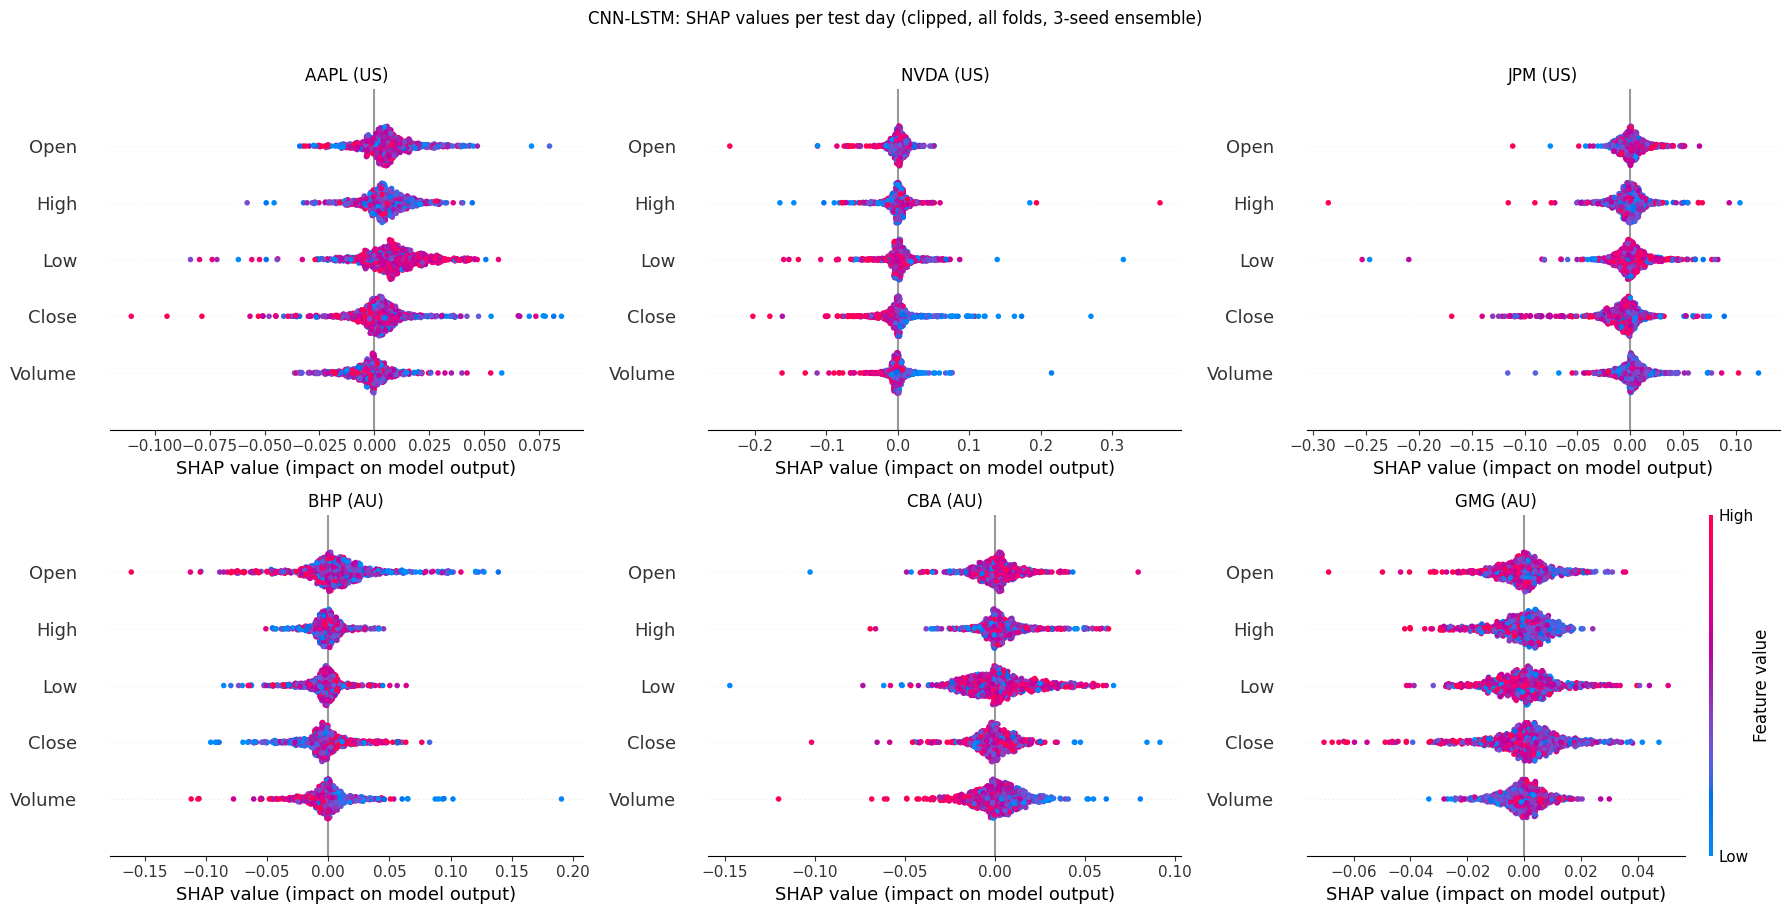

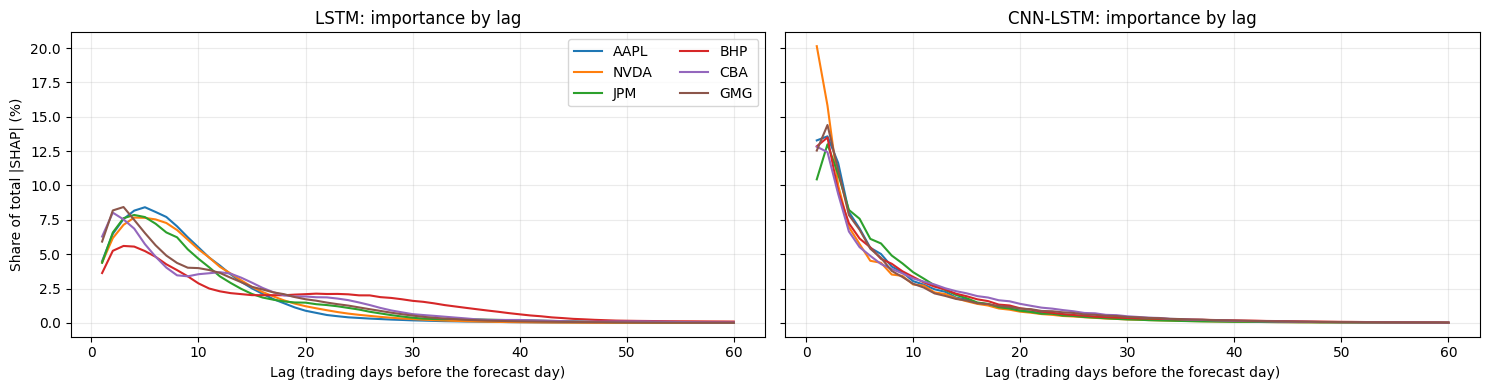

window          lag 1  lags 2-5  lags 6-20  lags 21-60
model    stock                                        
LSTM     AAPL     4.5      30.6       59.8         5.1
         NVDA     4.4      28.6       59.5         7.4
         JPM      4.4      29.8       53.0        12.9
         BHP      3.6      21.6       40.5        34.3
         CBA      6.3      28.1       47.0        18.6
         GMG      5.9      30.6       49.6        13.8
CNN-LSTM AAPL    13.3      40.1       38.2         8.4
         NVDA    20.1      38.5       34.5         6.8
         JPM     10.4      39.6       42.9         7.0
         BHP     12.9      36.4       40.6        10.1
         CBA     12.8      34.0       41.1        12.1
         GMG     12.5      40.2       36.4        10.9

In [63]:
# ---- 9.5 Feature importance, beeswarm plots and lag profile ----
importance = (shap_daily.assign(abs_shap=shap_daily['shap'].abs())
              .groupby(['model', 'stock', 'feature'])['abs_shap'].mean()
              .unstack('feature')[FEATURES]
              .reindex(pd.MultiIndex.from_product([SHAP_MODELS, stock], names=['model', 'stock'])))
share = importance.div(importance.sum(axis=1), axis=0) * 100
ranks = importance.rank(axis=1, ascending=False).astype(int)
print('Share of total importance (%)')
display(share.round(1))
print('Rank (1 = most important)')
display(ranks)
importance.to_csv(MODEL_DIR / f'shap_importance_{SHAP_CONDITION}.csv')

# Beeswarm plots: one figure per model, one panel per stock
for kind in SHAP_MODELS:
    fig = plt.figure(figsize=(18, 9))
    for i, name in enumerate(stock):
        g = shap_daily[(shap_daily['model'] == kind) & (shap_daily['stock'] == name)]
        values = g.pivot(index='date', columns='feature', values='shap')[FEATURES]
        data = g.pivot(index='date', columns='feature', values='value')[FEATURES]
        plt.subplot(2, 3, i + 1)
        shap.summary_plot(values.values, data.values, feature_names=FEATURES, sort=False,
                          show=False, plot_size=None, color_bar=(i == len(stock) - 1))
        plt.title(f'{name} ({MARKET[name]})')
    plt.suptitle(f'{kind}: SHAP values per test day ({SHAP_CONDITION}, all folds, 3-seed ensemble)', y=1.01)
    plt.tight_layout()
    plt.savefig(MODEL_DIR / f'shap_beeswarm_{kind}_{SHAP_CONDITION}.png', dpi=160, bbox_inches='tight')
    plt.show()

# Lag profile: share of the importance at each lag (summed over features and folds)
lag_share = shap_lags.groupby(['model', 'stock', 'lag'])['mean_abs_shap'].sum().reset_index()
lag_share['share'] = 100 * lag_share['mean_abs_shap'] / lag_share.groupby(['model', 'stock'])['mean_abs_shap'].transform('sum')
fig, axes = plt.subplots(1, len(SHAP_MODELS), figsize=(15, 4), sharey=True)
for ax, kind in zip(axes, SHAP_MODELS):
    for name in stock:
        g = lag_share[(lag_share['model'] == kind) & (lag_share['stock'] == name)].sort_values('lag')
        ax.plot(g['lag'], g['share'], label=name)
    ax.set_title(f'{kind}: importance by lag')
    ax.set_xlabel('Lag (trading days before the forecast day)')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Share of total |SHAP| (%)')
axes[0].legend(ncol=2)
plt.tight_layout()
plt.show()
display(lag_share.assign(window=pd.cut(lag_share['lag'], [0, 1, 5, 20, WINDOW], labels=['lag 1', 'lags 2-5', 'lags 6-20', 'lags 21-60']))
                 .pivot_table(index=['model', 'stock'], columns='window', values='share', aggfunc='sum', observed=False)
                 .reindex(importance.index).round(1))

### 9.6 Stability across companies and markets

This is the core of RQ2. For each model, the importance rankings of every pair of stocks are compared with Spearman's ρ (1 = same ranking, −1 = reversed). The heat maps show all pairs; the first table averages them over all pairs, the pairs within the U.S. market, the pairs within the Australian market, and the pairs across markets. If attributions were driven by market setting, the within-market correlations would be clearly higher than the cross-market ones.

The second table compares LSTM and CNN-LSTM on the same stock. The third groups the four correlated price features (Section 5.1) and shows the share of importance of the price features taken together versus volume, which is not affected by how the credit is divided among the price features.

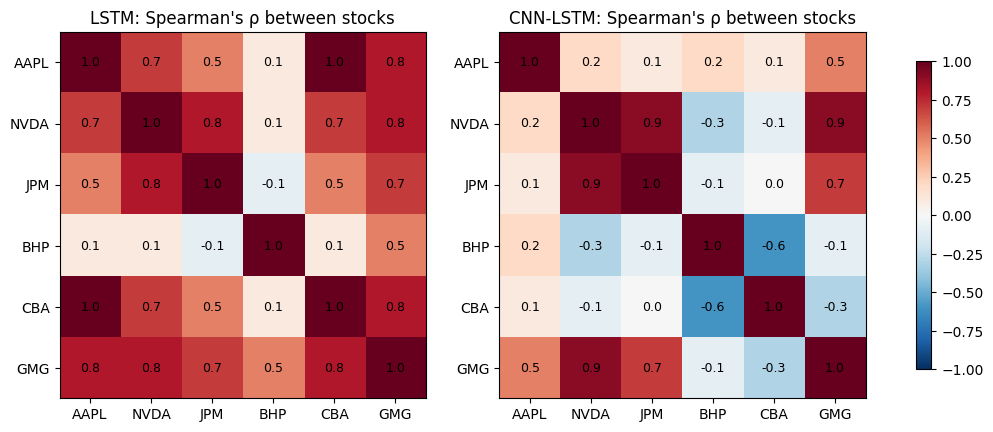

model,CNN-LSTM,LSTM
pairs,,
All pairs,0.14,0.53
Within U.S.,0.40,0.67
Within Australia,-0.33,0.47
U.S. vs Australia,0.21,0.51


,Spearman's ρ (LSTM vs CNN-LSTM),Top feature LSTM,Top feature CNN-LSTM
stock,,,
AAPL,0.7,Low,Low
NVDA,0.5,Low,Close
JPM,0.9,Close,Close
BHP,0.6,Open,Open
CBA,0.1,Low,Low
GMG,0.9,Close,Close


Price features (%)       Volume (%)      
model           CNN-LSTM  LSTM   CNN-LSTM  LSTM
stock                                          
AAPL                85.5  91.9       14.5   8.1
BHP                 81.1  90.9       18.9   9.1
CBA                 78.4  86.5       21.6  13.5
GMG                 85.3  90.8       14.7   9.2
JPM                 82.0  81.9       18.0  18.1
NVDA                83.6  85.3       16.4  14.7

In [64]:
# ---- 9.6 Stability across companies and markets ----
def rho(a, b):
    return spearmanr(a, b)[0]

pairs = list(combinations(stock, 2))
fig, axes = plt.subplots(1, len(SHAP_MODELS), figsize=(13, 5))
summary_rows = []
for ax, kind in zip(axes, SHAP_MODELS):
    imp = importance.loc[kind]
    mat = pd.DataFrame([[rho(imp.loc[a], imp.loc[b]) for b in stock] for a in stock], index=stock, columns=stock)
    im = ax.imshow(mat.values, vmin=-1, vmax=1, cmap='RdBu_r')
    for i in range(len(stock)):
        for j in range(len(stock)):
            ax.text(j, i, f'{mat.iloc[i, j]:.1f}', ha='center', va='center', fontsize=9)
    ax.set_xticks(range(len(stock)))
    ax.set_xticklabels(stock)
    ax.set_yticks(range(len(stock)))
    ax.set_yticklabels(stock)
    ax.set_title(f"{kind}: Spearman's ρ between stocks")

    def mean_rho(keep):
        vals = [mat.loc[a, b] for a, b in pairs if keep(a, b)]
        return np.mean(vals), len(vals)
    for label, keep in [('All pairs', lambda a, b: True),
                        ('Within U.S.', lambda a, b: MARKET[a] == MARKET[b] == 'US'),
                        ('Within Australia', lambda a, b: MARKET[a] == MARKET[b] == 'AU'),
                        ('U.S. vs Australia', lambda a, b: MARKET[a] != MARKET[b])]:
        m, n = mean_rho(keep)
        summary_rows.append({'model': kind, 'pairs': label, 'number of pairs': n, "mean Spearman's ρ": m})
plt.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(MODEL_DIR / f'shap_spearman_stocks_{SHAP_CONDITION}.png', dpi=160, bbox_inches='tight')
plt.show()
display(pd.DataFrame(summary_rows).pivot(index='pairs', columns='model', values="mean Spearman's ρ")
          .reindex(['All pairs', 'Within U.S.', 'Within Australia', 'U.S. vs Australia']).round(2))

# Same stock, LSTM vs CNN-LSTM
display(pd.DataFrame({"Spearman's ρ (LSTM vs CNN-LSTM)": [rho(importance.loc[('LSTM', s)], importance.loc[('CNN-LSTM', s)]) for s in stock],
                      'Top feature LSTM': [importance.loc[('LSTM', s)].idxmax() for s in stock],
                      'Top feature CNN-LSTM': [importance.loc[('CNN-LSTM', s)].idxmax() for s in stock]},
                     index=pd.Index(stock, name='stock')).round(2))

# Price features grouped (Section 5.1): share of importance of Open + High + Low + Close vs Volume
grouped = pd.DataFrame({'Price features (%)': share[['Open', 'High', 'Low', 'Close']].sum(axis=1),
                        'Volume (%)': share['Volume']})
display(grouped.unstack('model').round(1))

### 9.7 Reliability of the attributions: seeds and folds

Differences between stocks only mean something if a model's attributions are reproducible. Two checks:

+ **Seeds.** The three seeds of a model are trained on the same data and differ only in their random initialisation. The mean Spearman's ρ between the seeds' rankings (per fold, then averaged) shows how much of a ranking is due to chance in training.
+ **Folds.** The mean Spearman's ρ between the rankings of the 12 folds of the same stock shows whether the attributions are stable over time (2023–2025), and the last column counts the folds whose most important feature is the same as in the stock's overall ranking.

If the agreement between seeds or folds of the same stock is not clearly higher than the agreement between stocks (Section 9.6), the differences between stocks cannot be distinguished from noise.

In [65]:
# ---- 9.7 Reliability: agreement between seeds and between folds ----
def mean_pairwise_rho(table):
    # table: one row per item (seed or fold), one column per feature
    vals = [rho(table.loc[a], table.loc[b]) for a, b in combinations(table.index, 2)]
    return np.nanmean(vals)

seed_agree = (shap_seed.pivot_table(index=['model', 'stock', 'fold', 'seed'], columns='feature', values='importance')[FEATURES]
              .groupby(['model', 'stock', 'fold']).apply(lambda t: mean_pairwise_rho(t.droplevel([0, 1, 2])))
              .groupby(['model', 'stock']).mean())

fold_imp = (shap_daily.assign(abs_shap=shap_daily['shap'].abs())
            .groupby(['model', 'stock', 'fold', 'feature'])['abs_shap'].mean().unstack('feature')[FEATURES])
fold_agree = fold_imp.groupby(['model', 'stock']).apply(lambda t: mean_pairwise_rho(t.droplevel([0, 1])))
same_top = (fold_imp.idxmax(axis=1).rename('top').reset_index()
            .assign(overall=lambda t: [importance.loc[(m, s)].idxmax() for m, s in zip(t['model'], t['stock'])])
            .assign(same=lambda t: t['top'] == t['overall'])
            .groupby(['model', 'stock'])['same'].sum())

cross_stock = pd.DataFrame(summary_rows).query("pairs == 'All pairs'").set_index('model')["mean Spearman's ρ"]
reliability = pd.DataFrame({"Between seeds (mean ρ)": seed_agree,
                            "Between folds (mean ρ)": fold_agree,
                            'Folds with the overall top feature (of 12)': same_top}).reindex(importance.index)
display(reliability.round(2))
print("For reference, mean Spearman's ρ between stocks (Section 9.6):", cross_stock.round(2).to_dict())

Between seeds (mean ρ)  Between folds (mean ρ)  Folds with the overall top feature (of 12)
model    stock                                                                                            
LSTM     AAPL                     0.79                    0.74                                          10
         NVDA                     0.35                    0.46                                           9
         JPM                      0.59                    0.67                                          10
         BHP                      0.78                    0.66                                           7
         CBA                      0.48                    0.41                                           9
         GMG                      0.76                    0.68                                           8
CNN-LSTM AAPL                     0.15                    0.30                                           8
         NVDA                     0.13                    0.09                                           4
         JPM                      0.14                    0.03                                           3
         BHP                      0.16                    0.57                                           9
         CBA                      0.19                    0.29                                           7
         GMG                      0.15                    0.07                                           5

For reference, mean Spearman's ρ between stocks (Section 9.6): {'LSTM': 0.53, 'CNN-LSTM': 0.14}


### 9.7b Robustness of the SHAP estimates *(added based on Tiffany's parts)*

**Why this check is necessary.** Expected gradients is a Monte Carlo estimate: every SHAP value is an average over `N_SAMPLES` randomly drawn background windows and interpolation points, so repeating the calculation with another random seed of the explainer (`rseed`) gives slightly different values. Section 9.7 found that the three training seeds of a model often rank the features differently, especially for CNN-LSTM. That conclusion only holds if the disagreement between training seeds is larger than the noise of the explainer itself. In addition, Section 9.3 checked the approximation only through the correlation between the model output and its SHAP reconstruction (0.99), which can be high even when part of the output is not explained. Tiffany's validation notebook ran these checks on a small sample (AAPL, fold 1, 16 test days, a different importance definition); they are repeated here with the settings and the feature importance of Section 9.4 (contribution summed over the 60 lags, then the absolute value), on one U.S. and one Australian stock (BHP is the outlier of Section 9.6).

Three checks, on all test days of the selected folds:

+ **Explainer noise.** Each trained model is explained three times with `rseed` 0, 1 and 2 (`N_SAMPLES` = 100, as in Section 9.4). The agreement between these runs is compared with the agreement between the three training seeds.
+ **Convergence.** For training seed 0 the explanation is repeated with 1,000 samples. If the ranking at 1,000 samples is close to the ranking at 100, `N_SAMPLES` = 100 is sufficient.
+ **Relative additivity error.** Mean |output − (base value + sum of SHAP values)| divided by mean |output − base value|: the share of the part of the forecast that SHAP has to explain but does not.

*How to read the tables:* if the explainer runs agree much more closely than the training seeds (ρ close to 1, small changes in the feature shares), the instability found in Section 9.7 comes from the trained models, not from the SHAP estimation. Set `RUN_ROBUST = False` to reload the saved results instead of recomputing (about 5–10 minutes on a CPU).

In [66]:
# ---- 9.7b Robustness of the SHAP estimates (added based on Tiffany's parts) ----
RUN_ROBUST = True                          # False = load the saved results from model_outputs/
ROBUST_CASES = [('AAPL', 1), ('BHP', 1)]   # (stock, fold): one U.S. and one Australian stock
EXPLAINER_RSEEDS = (0, 1, 2)               # rseed 0 is the setting used in Section 9.4
N_SAMPLES_HIGH = 1000                      # convergence check (training seed 0 only)
ROBUST_FILE = MODEL_DIR / f'shap_robustness_{SHAP_CONDITION}.csv'
key = ['model', 'stock', 'fold']

def run_summary(sv, pred, base):
    imp = np.abs(sv.sum(axis=1)).mean(axis=0)            # feature importance, same definition as Section 9.4
    recon = base + sv.sum(axis=(1, 2))
    rel = np.abs(pred - recon).mean() / np.abs(pred - base).mean()
    return {'rel_error_pct': 100 * rel, **{f: float(imp[j]) for j, f in enumerate(FEATURES)}}

def share_spread(t):
    # largest change (percentage points) in a feature's share of the total importance between the rows of t
    s = t.div(t.sum(axis=1), axis=0) * 100
    return (s.max() - s.min()).max()

if EXPLAINER != 'GradientExplainer':
    robust = None
    print('DeepExplainer is deterministic: the Monte Carlo checks do not apply.')
elif RUN_ROBUST:
    rows, t0 = [], time.time()
    for kind in SHAP_MODELS:
        for name, k in ROBUST_CASES:
            fd = get_fold(name, k, winsor=CONDITIONS[SHAP_CONDITION], window=WINDOW)
            bg, X = background_sample(fd['X_train'], k), fd['X_test']
            for seed in SEEDS:
                tf.keras.backend.clear_session()
                model = tf.keras.models.load_model(model_path(kind, name, k, seed))
                pred = model.predict(X, verbose=0).reshape(-1)
                base = float(model.predict(bg, verbose=0).mean())
                explainer = make_explainer(model, bg)
                runs = [(r, N_SAMPLES) for r in EXPLAINER_RSEEDS] + ([(0, N_SAMPLES_HIGH)] if seed == SEEDS[0] else [])
                for r, n in runs:
                    sv = as_array(explainer.shap_values(X, nsamples=n, rseed=r))
                    rows.append({'model': kind, 'stock': name, 'fold': k, 'train_seed': seed, 'rseed': r,
                                 'nsamples': n, **run_summary(sv, pred, base)})
                del model, explainer
                gc.collect()
            print(f'{kind:>8} | {name} fold {k} done ({(time.time() - t0) / 60:.1f} min)')
    robust = pd.DataFrame(rows)
    robust.to_csv(ROBUST_FILE, index=False)
    print('Saved to:', ROBUST_FILE.resolve())
else:
    robust = pd.read_csv(ROBUST_FILE)
    print('Loaded:', ROBUST_FILE.resolve())

if robust is not None:
    base_runs = robust[robust['nsamples'] == N_SAMPLES]
    r0 = base_runs[base_runs['rseed'] == 0].set_index(key + ['train_seed'])[FEATURES]

    # Sanity check: rseed 0 with N_SAMPLES must reproduce the seed importances saved in Section 9.4
    saved = shap_seed.pivot_table(index=['model', 'stock', 'fold', 'seed'], columns='feature', values='importance')[FEATURES]
    saved = saved.loc[[tuple(i) for i in r0.index]]
    print(f'Largest relative difference from Section 9.4: {float((np.abs(r0.values - saved.values) / saved.values).max()):.2e}')

    # (1) Explainer noise vs training seeds
    by_model = base_runs.set_index(key + ['train_seed', 'rseed'])[FEATURES].groupby(key + ['train_seed'])
    noise = pd.DataFrame({
        "Explainer runs: mean ρ": by_model.apply(lambda t: mean_pairwise_rho(t.droplevel([0, 1, 2, 3]))).groupby(key).mean(),
        'Explainer runs: max share change (pp)': by_model.apply(share_spread).groupby(key).mean(),
        'Explainer runs: same top feature (models of 3)': by_model.apply(lambda t: t.idxmax(axis=1).nunique() == 1).groupby(key).sum(),
        "Training seeds: mean ρ": r0.groupby(key).apply(lambda t: mean_pairwise_rho(t.droplevel([0, 1, 2]))),
        'Training seeds: max share change (pp)': r0.groupby(key).apply(share_spread),
        'Relative additivity error (%)': base_runs.groupby(key)['rel_error_pct'].mean()})
    print('\n(1) Explainer noise vs differences between training seeds  (N_SAMPLES =', N_SAMPLES, ')')
    display(noise.round(2))

    # (2) Convergence: N_SAMPLES vs N_SAMPLES_HIGH for training seed 0, rseed 0
    conv_rows = []
    for (kind, name, k), g in robust[(robust['train_seed'] == SEEDS[0]) & (robust['rseed'] == 0)].groupby(key):
        lo = g[g['nsamples'] == N_SAMPLES].iloc[0]
        hi = g[g['nsamples'] == N_SAMPLES_HIGH].iloc[0]
        conv_rows.append({'model': kind, 'stock': name, 'fold': k,
                          f"ρ ({N_SAMPLES} vs {N_SAMPLES_HIGH})": rho(lo[FEATURES].astype(float), hi[FEATURES].astype(float)),
                          'max share change (pp)': share_spread(pd.DataFrame([lo[FEATURES], hi[FEATURES]]).astype(float)),
                          f'top feature ({N_SAMPLES})': lo[FEATURES].astype(float).idxmax(),
                          f'top feature ({N_SAMPLES_HIGH})': hi[FEATURES].astype(float).idxmax(),
                          f'rel. error {N_SAMPLES} (%)': lo['rel_error_pct'],
                          f'rel. error {N_SAMPLES_HIGH} (%)': hi['rel_error_pct']})
    print(f'(2) Convergence: {N_SAMPLES} vs {N_SAMPLES_HIGH} samples (training seed {SEEDS[0]})')
    display(pd.DataFrame(conv_rows).set_index(key).round(2))

    LSTM | AAPL fold 1 done (2.6 min)
    LSTM | BHP fold 1 done (4.9 min)
CNN-LSTM | AAPL fold 1 done (6.1 min)
CNN-LSTM | BHP fold 1 done (7.3 min)
Saved to: C:\Users\happe\OneDrive\Desktop\COMP8851\model_outputs\shap_robustness_clipped.csv
Largest relative difference from Section 9.4: 1.72e-14

(1) Explainer noise vs differences between training seeds  (N_SAMPLES = 100 )


Explainer runs: mean ρ  Explainer runs: max share change (pp)  Explainer runs: same top feature (models of 3)  Training seeds: mean ρ  Training seeds: max share change (pp)  \
model    stock fold                                                                                                                                                                                 
CNN-LSTM AAPL  1                       0.87                                   2.35                                               2                   -0.23                                  11.80   
         BHP   1                       0.98                                   1.56                                               3                    0.47                                  10.45   
LSTM     AAPL  1                       0.98                                   0.78                                               3                    0.83                                   5.81   
         BHP   1                       0.98                                   0.88                                               3                    0.87                                  16.11   

                     Relative additivity error (%)  
model    stock fold                                 
CNN-LSTM AAPL  1                             30.95  
         BHP   1                             19.55  
LSTM     AAPL  1                             15.96  
         BHP   1                             16.39

(2) Convergence: 100 vs 1000 samples (training seed 0)


ρ (100 vs 1000)  max share change (pp) top feature (100) top feature (1000)  rel. error 100 (%)  rel. error 1000 (%)
model    stock fold                                                                                                                      
CNN-LSTM AAPL  1                 0.7                   1.18             Close              Close               28.39                 9.69
         BHP   1                 1.0                   0.88              Open               Open               17.75                 5.38
LSTM     AAPL  1                 0.9                   0.61             Close              Close               13.56                 4.56
         BHP   1                 1.0                   0.37             Close              Close               18.09                 4.95

#### Findings (Section 9.7b)

*The statements below refer to the two tables above (AAPL and BHP, fold 1, clipped condition, all 62 test days).*

+ **Sanity check.** The run with `rseed` 0 and 100 samples reproduces the seed importances of Section 9.4 exactly (largest relative difference about 2·10⁻¹⁴), so the check uses the same models, background and settings as the main analysis.
+ **Explainer noise is small compared with the differences between training seeds.** Explaining the same trained model three times with different explainer seeds gives almost the same ranking (mean ρ 0.87–0.98) and changes no feature's share of the importance by more than 2.4 percentage points; the top feature is the same in all three runs for 11 of the 12 trained models (the exception is one CNN-LSTM for AAPL, where the two leading features are almost equal). The three training seeds, by contrast, disagree much more: mean ρ between −0.23 and 0.87, and feature shares that differ by 5.8–16.1 percentage points. The instability found in Section 9.7, especially for CNN-LSTM, therefore comes from the trained networks themselves and not from the SHAP estimation.
+ **100 samples are enough for the rankings.** With 1,000 instead of 100 samples, the ranking changes little (ρ 0.7–1.0, no feature share changes by more than 1.2 percentage points) and the top feature is the same in all four cases.
+ **The individual SHAP values are less precise than the correlation in Section 9.3 suggests.** With 100 samples, the sum of the SHAP values misses on average 16–31% of the part of the forecast to be explained (output minus base value); with 1,000 samples this falls to 5–10%. The error is larger for CNN-LSTM than for LSTM. Because the feature importances average the absolute contributions over all test days (and over 12 folds and 3 seeds in Section 9.6), most of this sampling error cancels out, which is why the rankings are stable even though single-day attributions are noisy.

**Conclusion.** The conclusions of Sections 9.6–9.7 do not depend on the random sampling of the explainer: the differences between seeds and between companies are much larger than the explainer noise. Single-day SHAP values at 100 samples should not be interpreted individually; only the aggregated importances are used in this analysis. The check covers two stocks and one fold, so it shows the size of the explainer noise rather than proving its size for every case.

### 9.8 Answer to RQ2

*The statements below refer to the outputs of Sections 9.2–9.7b. The attributions were computed with expected gradients, because DeepSHAP does not support the saved TensorFlow models (Section 9.2); the base value plus the sum of the SHAP values reproduces the model output with a correlation of 0.99 (Section 9.3), and the feature rankings do not depend on the random sampling of the explainer (Section 9.7b).*

**Short answer: only partly.** At a coarse level the attributions are stable across all six companies and both markets: both models rely mainly on the four price features and on the most recent trading days. At the level of the individual feature rankings, the agreement between companies is moderate for LSTM and low for CNN-LSTM, and it is of the same size as the agreement between seeds and folds of the same model. The variation between companies therefore cannot be attributed to company or market characteristics.

+ **What the models use (Section 9.5).** The price features (Open, High, Low, Close) account for 78–92% of the importance in every stock and both models; volume for 8–22%. For LSTM, Low or Close is the most important feature in 5 of 6 stocks (BHP: Open) and volume is the least important in 4 of 6. For CNN-LSTM, Low or Close is the most important feature in 5 of 6 stocks (again BHP: Open).
+ **Which days the models use (Section 9.5).** The models look only a few weeks back, and this pattern is the same for every stock. LSTM places 81–95% of its importance within the last 20 trading days, with a peak around lags 3–5; BHP is the exception (66%, with a third of the importance beyond lag 20). CNN-LSTM has a shorter memory: 47–59% of its importance lies in the last 5 days.
+ **Beeswarm plots (Section 9.5).** The colours show no clear gradient: a high or a low value of a feature on the previous day can push the forecast either way. This agrees with Part 8, where no model forecast better than naive. (The colour shows the value on the most recent day, while the SHAP value sums all 60 lags, so the plots describe the overall contribution rather than a one-day effect.)
+ **Stability across companies (Section 9.6).** For LSTM the mean Spearman's ρ between stocks is 0.53. BHP is the outlier (ρ between −0.1 and 0.5 with the others); among the other five stocks the agreement is high (mean ρ ≈ 0.73, with identical rankings for AAPL and CBA). For CNN-LSTM the mean ρ is only 0.14 (range −0.6 to 0.9): NVDA, JPM and GMG agree closely, the other stocks do not.
+ **Stability across markets (Section 9.6).** There is no market pattern. For LSTM, ρ is 0.67 within the U.S., 0.47 within Australia and 0.51 across markets; for CNN-LSTM, 0.40, −0.33 and 0.21. The lower Australian values come from BHP (LSTM) and from BHP and CBA (CNN-LSTM), and cross-market pairs such as AAPL–CBA agree as much as pairs within a market. The differences are company-specific rather than market-specific.
+ **LSTM vs CNN-LSTM (Section 9.6).** The two models agree on the most important feature in 5 of 6 stocks (all except NVDA), with ρ between 0.1 (CBA) and 0.9 (JPM, GMG).
+ **Reliability (Section 9.7).** The rankings of LSTM are fairly reproducible: ρ between seeds 0.35–0.79, between folds 0.41–0.74, and the overall top feature is the top feature in 7–10 of the 12 folds. The rankings of CNN-LSTM are not: ρ between seeds is only 0.13–0.19, so two CNN-LSTMs trained on the same data with different initialisations rank the features almost independently. For both models, the agreement between companies (0.53 and 0.14) is no higher than the agreement between seeds of the same stock. These seed and fold checks use one fold at a time, while the company rankings pool 12 folds and 3 seeds, so the checks are somewhat pessimistic; the conclusion that company differences are not clearly larger than training noise still holds.
+ **Robustness of the estimates (Section 9.7b)** *(check added based on Tiffany's parts)*. The disagreement between seeds is not caused by the SHAP estimation: explaining the same model with different explainer seeds gives nearly identical rankings (mean ρ 0.87–0.98, feature shares within 2.4 percentage points), whereas different training seeds differ by ρ between −0.23 and 0.87 and by 5.8–16.1 percentage points (AAPL and BHP, fold 1). Increasing the number of samples from 100 to 1,000 leaves the rankings and the top feature practically unchanged.
+ **Correlated features (Section 5.1).** Part of the instability in the rankings is the credit moving between the four correlated price features. When they are taken together, the split between price features and volume is stable across all stocks and both models.

**Conclusion for RQ2.** The SHAP attributions are stable in *what kind* of information LSTM and CNN-LSTM use: recent price movements over the last one to three weeks, with little weight on volume. This holds across all six companies and both markets. They are not stable in the *exact ranking* of the individual features: LSTM shows moderate agreement, with BHP as the exception, and CNN-LSTM shows little. In both cases the differences between companies and markets are of the same size as the differences between seeds and folds of the same stock. Because neither model forecasts better than the naive baseline (Part 8), these attributions describe how the networks process mostly unpredictable inputs rather than a predictive structure in the market, and the variation across companies should not be read as company- or market-specific drivers.

*Limitations:* expected gradients is an approximation of SHAP values: with 100 samples per test day the sum of the SHAP values misses 16–31% of the part of the forecast to be explained (5–10% with 1,000 samples), so single-day attributions are noisy, although the aggregated rankings used here are stable (Section 9.7b, which covers two stocks and one fold); with five features, Spearman's ρ is coarse (Section 9 introduction); and the analysis covers the clipped condition only (`SHAP_CONDITION`).

**References (Part 9)**

Erion, G., Janizek, J. D., Sturmfels, P., Lundberg, S. M., & Lee, S.-I. (2021). Improving performance of deep learning models with axiomatic attribution priors and expected gradients. *Nature Machine Intelligence, 3*(7), 620–631.

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765–4774.

Shrikumar, A., Greenside, P., & Kundaje, A. (2017). Learning important features through propagating activation differences. *Proceedings of the 34th International Conference on Machine Learning, 70*, 3145–3153.

Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101.